In [2]:
import pandas as pd
import matplotlib.pyplot as plt

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:

# Step 1: Import Pandas
import pandas as pd

# Step 2: Read the CSV file
df = pd.read_csv("data/IDS_CountryMetaData.csv", encoding="Latin-1")

# Step 3: Display the first 5 rows
print("FIRST 5 ROWS OF THE DATASET")
print(df.head())

# Step 4: Display the number of rows and columns
print("\nDATASET SIZE")
print(df.shape)

# Step 5: Display all column names
print("\nCOLUMN NAMES")
print(df.columns.tolist())

# Step 6: Display dataset information
print("\nDATASET INFORMATION")
df.info()
#dataset2
df = pd.read_csv("data/IDS_ALLCountries_Data.csv", encoding="Latin-1")

# Step 3: Display the first 5 rows
print("FIRST 5 ROWS OF THE DATASET")
print(df.head())

# Step 4: Display the number of rows and columns
print("\nDATASET SIZE")
print(df.shape)

# Step 5: Display all column names
print("\nCOLUMN NAMES")
print(df.columns.tolist())

# Step 6: Display dataset information
print("\nDATASET INFORMATION")
df.info()
#dataset3
df = pd.read_csv("data/IDS_CountryMetaData.csv", encoding="Latin-1")

# Step 3: Display the first 5 rows
print("FIRST 5 ROWS OF THE DATASET")
print(df.head())

# Step 4: Display the number of rows and columns
print("\nDATASET SIZE")
print(df.shape)

# Step 5: Display all column names
print("\nCOLUMN NAMES")
print(df.columns.tolist())

# Step 6: Display dataset information
print("\nDATASET INFORMATION")
df.info()
#dataset4
df = pd.read_csv("data/IDS_FootNoteMetaData.csv", encoding="Latin-1")

# Step 3: Display the first 5 rows
print("FIRST 5 ROWS OF THE DATASET")
print(df.head())

# Step 4: Display the number of rows and columns
print("\nDATASET SIZE")
print(df.shape)

# Step 5: Display all column names
print("\nCOLUMN NAMES")
print(df.columns.tolist())

# Step 6: Display dataset information
print("\nDATASET INFORMATION")
df.info()
#dataset5
df = pd.read_csv("data/IDS_SeriesMetaData.csv", encoding="Latin-1")

# Step 3: Display the first 5 rows
print("FIRST 5 ROWS OF THE DATASET")
print(df.head())

# Step 4: Display the number of rows and columns
print("\nDATASET SIZE")
print(df.shape)

# Step 5: Display all column names
print("\nCOLUMN NAMES")
print(df.columns.tolist())

# Step 6: Display dataset information
print("\nDATASET INFORMATION")
df.info()


FIRST 5 ROWS OF THE DATASET
  Code                                Long Name         Income Group  \
0  AFG             Islamic State of Afghanistan           Low income   
1  ALB                      Republic of Albania  Upper middle income   
2  DZA  People's Democratic Republic of Algeria  Upper middle income   
3  AGO              People's Republic of Angola  Lower middle income   
4  ARG                       Argentine Republic  Upper middle income   

                       Region Lending category Other groups   Currency Unit  \
0  Middle East & North Africa              IDA         HIPC  Afghan afghani   
1       Europe & Central Asia             IBRD          NaN    Albanian lek   
2  Middle East & North Africa             IBRD          NaN  Algerian dinar   
3          Sub-Saharan Africa             IBRD          NaN  Angolan kwanza   
4   Latin America & Caribbean             IBRD          NaN  Argentine peso   

  Latest population census                      Latest household

In [4]:
import re
import pandas as pd
#dataset1
SRC = "data/Country-Series - Metadata.csv"
OUT = "Output/country_series_cleaned.csv"
OUT_DEBT = "Output/country_series_debt_only.csv"

# 1. Load (file is Windows-1252 encoded, not UTF-8)
df = pd.read_csv(SRC, encoding="cp1252", dtype=str)
print("Raw shape:", df.shape)

# 2. Standardize column names
df.columns = [c.strip().lower().replace(" ", "_") for c in df.columns]

# 3. Missing values: blanks -> NaN, then report / drop rows missing key fields
df = df.replace(r"^\s*$", pd.NA, regex=True)
print("Nulls per column:\n", df.isna().sum())
df = df.dropna(subset=["country_code", "series_code"])
df["description"] = df["description"].fillna("No description available")

# 4. Split combined fields: "Afghanistan (AFG)" and "<name> (<code>)"
c = df["country_code"].str.extract(r"^(?P<country>.*?)\s*\((?P<country_code>[A-Z]{3})\)\s*$")
s = df["series_code"].str.extract(r"^(?P<indicator>.*?)\s*\((?P<indicator_code>[A-Z0-9.]+)\)\s*$")
df = df.assign(country=c["country"], country_code=c["country_code"],
               indicator=s["indicator"], indicator_code=s["indicator_code"])
df = df.dropna(subset=["country", "country_code", "indicator_code"])

# 5. Text cleaning: trim, collapse whitespace/newlines, fix encoding artefacts
def clean_text(x):
    x = re.sub(r"\s+", " ", str(x)).strip()
    return x.replace("\u2013", "-").replace("\u2019", "'")
for col in ["country", "indicator", "description"]:
    df[col] = df[col].map(clean_text)
df["country_code"] = df["country_code"].str.upper()
df["indicator_code"] = df["indicator_code"].str.upper()

# 6. Data type conversion
for col in ["country", "country_code", "indicator", "indicator_code"]:
    df[col] = df[col].astype("category")
df["description"] = df["description"].astype("string")

# 7. Flag debt indicators (World Bank external debt series = DT.DOD.*)
df["is_debt_indicator"] = df["indicator_code"].astype(str).str.startswith("DT.DOD")

# 8. Remove duplicates (exact + on the natural key)
before = len(df)
df = df.drop_duplicates().drop_duplicates(subset=["country_code", "indicator_code"])
print("Duplicates removed:", before - len(df))

# 9. Keep relevant columns, sort, save
cols = ["country", "country_code", "indicator", "indicator_code", "is_debt_indicator", "description"]
df = df[cols].sort_values(["country", "indicator_code"]).reset_index(drop=True)
df.to_csv(OUT, index=False, encoding="utf-8")
df[df["is_debt_indicator"]].to_csv(OUT_DEBT, index=False, encoding="utf-8")

print("Clean shape:", df.shape, "| countries:", df["country_code"].nunique())
print(df.dtypes)
print(df["indicator"].value_counts())

#dataset2
import re
import pandas as pd

SRC = "data/IDS_ALLCountries_Data.csv"
OUT_WIDE = "output/ids_cleaned_wide.csv"
OUT_DEBT_LONG = "output/ids_debt_long.csv"
OUT_LOOKUP = "output/ids_indicator_lookup.csv"

# 1. Load (file is Windows-1252 encoded; read everything as text first)
df = pd.read_csv(SRC, encoding="cp1252", dtype=str)
print("Raw shape:", df.shape)

# 2. Standardize column names
df.columns = [c.strip().lower().replace("-", "_").replace(" ", "_") for c in df.columns]
year_cols = [c for c in df.columns if c.isdigit()]

# 3. Remove footer / blank rows (no country or series code), e.g. the
#    "Data from database..." and "Last Updated..." lines at the bottom
df = df.dropna(subset=["country_code", "series_code"])
print("After removing blank/footer rows:", df.shape)

# 4. Text cleaning: trim, collapse whitespace (incl. non-breaking spaces)
def clean_text(x):
    return re.sub(r"\s+", " ", str(x).replace("\xa0", " ")).strip()

for c in ["country_name", "series_name"]:
    df[c] = df[c].map(clean_text)
df["country_code"] = df["country_code"].str.strip().str.upper()
df["series_code"] = df["series_code"].str.strip().str.upper()

# 5. Drop constant column (counterpart area is "World" for every row)
assert df["counterpart_area_code"].nunique() == 1
df = df.drop(columns=["counterpart_area_name", "counterpart_area_code"])

# 6. Data type conversion: year columns -> numeric (bad tokens like ".." -> NaN)
df[year_cols] = df[year_cols].apply(pd.to_numeric, errors="coerce")
df = df.rename(columns={"series_name": "indicator", "series_code": "indicator_code"})

# 7. Missing values: drop rows with no observation in any year
before = len(df)
df = df.dropna(subset=year_cols, how="all")
print("All-null rows removed:", before - len(df))

# 8. Duplicates (exact + natural key)
before = len(df)
df = df.drop_duplicates().drop_duplicates(subset=["country_code", "indicator_code"])
print("Duplicates removed:", before - len(df))

# 9. Add helper columns: unit and debt flag
def unit(name):
    n = name.lower()
    if "current us$" in n: return "current US$"
    if "(us$)" in n: return "US$"
    if "(%" in n or "% of" in n: return "%"
    if "(years)" in n: return "years"
    if "months of imports" in n: return "months of imports"
    return "other"

df["unit"] = df["indicator"].map(unit)
df["is_debt_indicator"] = df["indicator_code"].str.startswith("DT.")

# 10. Final types, column order, sort
for c in ["country_name", "country_code", "indicator", "indicator_code", "unit"]:
    df[c] = df[c].astype("category")
df = df[["country_name", "country_code", "indicator", "indicator_code",
         "unit", "is_debt_indicator"] + year_cols]
df = df.sort_values(["country_name", "indicator_code"]).reset_index(drop=True)

# 11. Save wide file (all indicators) and a tidy long file for debt indicators
df.to_csv(OUT_WIDE, index=False)

id_cols = ["country_name", "country_code", "indicator", "indicator_code", "unit"]
long = (df[df["is_debt_indicator"]]
        .melt(id_vars=id_cols, value_vars=year_cols, var_name="year", value_name="value")
        .dropna(subset=["value"]))
long["year"] = long["year"].astype(int)
long = long.sort_values(["country_code", "indicator_code", "year"])

# Slim long file: keep codes only; names/units live in a lookup table
(df[["indicator_code", "indicator", "unit", "is_debt_indicator"]]
   .drop_duplicates().sort_values("indicator_code")
   .to_csv(OUT_LOOKUP, index=False))
long = long[["country_code", "indicator_code", "year", "value"]]
long.to_csv(OUT_DEBT_LONG, index=False)

print("Clean wide shape:", df.shape, "| countries:", df["country_code"].nunique(),
      "| indicators:", df["indicator_code"].nunique())
print("Debt indicators:", df.loc[df.is_debt_indicator, "indicator_code"].nunique(),
      "| debt long rows:", len(long))
print(df.dtypes.head(8))

#dataset3

import os
from pathlib import Path
import pandas as pd

# ---- Paths: edit BASE / file names for your machine --------------------------
BASE = Path(r"C:\International_Debt Analysis System")
SRC = Path(os.environ.get("IDS_SRC", BASE / "data" / "IDS_CountryMetaData.csv"))
OUT_DIR = Path(os.environ.get("IDS_OUT", BASE / "outputs"))
OUT_DIR.mkdir(parents=True, exist_ok=True)          # fixes "non-existent directory"
OUT_FILE = OUT_DIR / "country_metadata_cleaned.csv"

# 1. Load (file is Windows-1252 encoded, not UTF-8); read as text first
df = pd.read_csv(SRC, encoding="cp1252", dtype=str)
print("Raw shape:", df.shape)

# 2. Standardize column names
df.columns = [c.strip().lower().replace("-", "_").replace(" ", "_") for c in df.columns]

# 3. Trim whitespace in every text column, blanks -> null
for c in df.columns:
    df[c] = df[c].str.replace(r"\s+", " ", regex=True).str.strip()
df = df.replace("", pd.NA)

# 4. Remove duplicates (exact rows, then on country code)
before = len(df)
df["code"] = df["code"].str.upper()
df = df.drop_duplicates().drop_duplicates(subset=["code"])
print("Duplicates removed:", before - len(df))

# 5. Filter relevant columns and rename
df = df.rename(columns={
    "code": "country_code", "short_name": "country_name", "long_name": "country_long_name",
    "2_alpha_code": "iso2_code", "external_debt_reporting_status": "debt_reporting_status",
})

# 6. Flag aggregates: regional / income-group rows (no region, lending category or currency)
df["entity_type"] = (df["region"].isna() & df["lending_category"].isna()
                     & df["currency_unit"].isna()).map({True: "Aggregate", False: "Country"})

# 7. Missing values
#    - "other_groups" only ever holds "HIPC", so null = not HIPC -> boolean flag
df["is_hipc"] = df["other_groups"].eq("HIPC")
cat_cols = ["income_group", "region", "lending_category", "currency_unit", "debt_reporting_status"]
is_agg = df["entity_type"].eq("Aggregate")
for c in cat_cols:
    df[c] = df[c].mask(is_agg & df[c].isna(), "Not applicable (aggregate)")
    df[c] = df[c].fillna("Not available")

# 8. Keep only columns relevant to debt analysis, set data types
keep = ["country_code", "country_name", "country_long_name", "iso2_code", "entity_type",
        "region", "income_group", "lending_category", "is_hipc", "currency_unit",
        "debt_reporting_status"]
df = df[keep].copy()
for c in keep:
    if c != "is_hipc":
        df[c] = df[c].astype("category")

df = df.sort_values(["entity_type", "country_name"]).reset_index(drop=True)
df.to_csv(OUT_FILE, index=False, encoding="utf-8")

print("Clean shape:", df.shape)
print(df["entity_type"].value_counts())
print("Countries with 'Not available' income group:",
      df.loc[(df.entity_type == "Country") & (df.income_group == "Not available"), "country_name"].tolist())
print(df.dtypes)

#dataset4
import os
import re
import numpy as np
import pandas as pd

def clean_debt_metadata(input_filepath, output_filepath):
    print("=" * 60)
    print("STARTING DATA CLEANING & STANDARDIZATION PIPELINE")
    print("=" * 60)

    # 1. File Existence & Loading Check
    if not os.path.exists(input_filepath):
        print(f"\n[ERROR] File not found: '{input_filepath}'")
        print(f"Current Working Directory: {os.getcwd()}")
        print("Please verify the filename or provide the absolute path.")
        return None

    print(f"\n1. Loading dataset from '{input_filepath}'...")
    try:
        # Using 'latin1' encoding to safely parse special characters/symbols
        df = pd.read_csv(input_filepath, encoding='latin1')
    except Exception as e:
        # Fallback encoding if latin1 encounters issues
        df = pd.read_csv(input_filepath, encoding='cp1252')
        
    print(f"   Original dataset shape: {df.shape}")

    # 2. Handle Missing Values (Null Data)
    print("\n2. Handling missing values...")
    # Replace blank or whitespace-only strings with NaN
    df.replace(r'^\s*$', np.nan, regex=True, inplace=True)
    
    initial_nulls = df.isnull().sum().to_dict()
    print(f"   Null counts per column before cleaning: {initial_nulls}")
    
    # Drop rows where critical identifier columns are completely missing
    critical_cols = [col for col in ['Country Code', 'Series Code', 'Time Code'] if col in df.columns]
    if critical_cols:
        df.dropna(subset=critical_cols, inplace=True)

    # 3. Remove Duplicate Records
    print("\n3. Removing duplicate records...")
    rows_before_dups = len(df)
    
    # Drop exact row duplicates
    df.drop_duplicates(inplace=True)
    
    # Drop duplicates based on core business/composite keys if present
    composite_keys = [c for c in ['Country Code', 'Series Code', 'Time Code'] if c in df.columns]
    if composite_keys:
        df.drop_duplicates(subset=composite_keys, inplace=True)
        
    duplicates_removed = rows_before_dups - len(df)
    print(f"   Total duplicate records removed: {duplicates_removed}")

    # 4. Perform Data Type Conversion & Feature Extraction
    print("\n4. Performing data type conversion and feature extraction...")
    # Standardize string formatting across all text columns
    for col in df.select_dtypes(include=['object']).columns:
        df[col] = df[col].astype(str).str.strip()

    # Extract Year from Time Code (e.g., '2024 (YR2024)' -> 2024) and convert to nullable integer type
    if 'Time Code' in df.columns:
        df['Year'] = df['Time Code'].str.extract(r'(\d{4})')
        df['Year'] = pd.to_numeric(df['Year'], errors='coerce').astype('Int64')

    # Separate Country Name and ISO Code from Country Code field (e.g., 'Afghanistan (AFG)')
    if 'Country Code' in df.columns:
        df['Country_Name'] = df['Country Code'].str.replace(r'\s*\([A-Z]+\)', '', regex=True)
        df['ISO_Code'] = df['Country Code'].str.extract(r'\(([A-Z]+)\)')

    # Separate Indicator Name from Series Code
    if 'Series Code' in df.columns:
        df['Indicator_Name'] = df['Series Code'].str.replace(r'\s*\([A-Za-z0-9\._-]+\s*\)', '', regex=True)

    # 5. Filter Relevant Columns (Country, Indicators, Debt/Time Values, Descriptions)
    print("\n5. Filtering relevant columns...")
    target_columns = [
        'Type', 
        'Country_Name', 
        'ISO_Code', 
        'Indicator_Name', 
        'Series Code', 
        'Year', 
        'Time Code', 
        'Description'
    ]
    # Keep only columns that exist in the dataframe to prevent KeyError
    available_columns = [col for col in target_columns if col in df.columns]
    df_filtered = df[available_columns].copy()

    # 6. Save Cleaned Dataset
    print(f"\n6. Saving cleaned dataset to '{output_filepath}'...")
    df_filtered.to_csv(output_filepath, index=False, encoding='utf-8')
    print(f"   Final cleaned dataset shape: {df_filtered.shape}")
    print("=" * 60)
    print("PIPELINE COMPLETED SUCCESSFULLY!")
    print("=" * 60)

    return df_filtered

if __name__ == '__main__':
    # File paths (Note: If your file is named 'IDS_FootNoteMetaData_2.csv', update input_file below)
    input_file = 'C:\\International_Debt Analysis System\\data\\IDS_FootNoteMetaData.csv'
    output_file = 'C:\\International_Debt Analysis System\\data\\IDS_FootNoteMetaData_Cleaned.csv'

    # Run the complete cleaning pipeline
    cleaned_data = clean_debt_metadata(input_file, output_file)
    
    if cleaned_data is not None:
        print("\nPreview of Cleaned Dataset:")
        print(cleaned_data.head(3))

        #dataset5
        import os
import numpy as np
import pandas as pd

def clean_series_metadata(input_filepath, output_filepath):
    print("=" * 60)
    print("STARTING SERIES METADATA CLEANING & STANDARDIZATION PIPELINE")
    print("=" * 60)

    # 1. File Existence & Loading Check
    if not os.path.exists(input_filepath):
        print(f"\n[ERROR] File not found: '{input_filepath}'")
        print(f"Current Working Directory: {os.getcwd()}")
        print("Please verify the filename or provide the absolute path.")
        return None

    print(f"\n1. Loading dataset from '{input_filepath}'...")
    try:
        # Using 'latin1' encoding to safely parse special characters and symbols
        df = pd.read_csv(input_filepath, encoding='latin1')
    except Exception as e:
        df = pd.read_csv(input_filepath, encoding='cp1252')
        
    print(f"   Original dataset shape: {df.shape}")

    # 2. Handle Missing Values (Null Data)
    print("\n2. Handling missing values...")
    # Replace blank or whitespace-only strings with NaN
    df.replace(r'^\s*$', np.nan, regex=True, inplace=True)
    
    initial_nulls = df.isnull().sum().to_dict()
    print(f"   Null counts per column before cleaning:\n   {initial_nulls}")
    
    # Fill sparse textual metadata gaps where appropriate
    if 'Short definition' in df.columns:
        df['Short definition'] = df['Short definition'].fillna('Not Specified')
    if 'Dataset' in df.columns:
        df['Dataset'] = df['Dataset'].fillna('International Debt Statistics')

    # 3. Remove Duplicate Records
    print("\n3. Removing duplicate records...")
    rows_before_dups = len(df)
    
    # Drop exact row duplicates
    df.drop_duplicates(inplace=True)
    
    # Drop duplicate records based on the unique indicator Code
    if 'Code' in df.columns:
        df.drop_duplicates(subset=['Code'], inplace=True)
        
    duplicates_removed = rows_before_dups - len(df)
    print(f"   Total duplicate records removed: {duplicates_removed}")

    # 4. Perform Data Type Conversion & Text Standardization
    print("\n4. Performing data type conversion and text standardization...")
    # Standardize string formatting (strip leading/trailing whitespaces) across all text columns
    for col in df.select_dtypes(include=['object']).columns:
        df[col] = df[col].astype(str).str.strip()

    # 5. Filter Relevant Columns (Indicators, Definitions, Topics, Sources)
    print("\n5. Filtering relevant columns...")
    target_columns = [
        'Code', 
        'Indicator Name', 
        'Short definition', 
        'Long definition', 
        'Topic', 
        'Source', 
        'Periodicity', 
        'Aggregation method'
    ]
    # Keep only available columns to prevent KeyError
    available_columns = [col for col in target_columns if col in df.columns]
    df_filtered = df[available_columns].copy()

    # 6. Save Cleaned Dataset
    print(f"\n6. Saving cleaned dataset to '{output_filepath}'...")
    df_filtered.to_csv(output_filepath, index=False, encoding='utf-8')
    print(f"   Final cleaned dataset shape: {df_filtered.shape}")
    print("=" * 60)
    print("PIPELINE COMPLETED SUCCESSFULLY!")
    print("=" * 60)

    return df_filtered

if __name__ == '__main__':
    # File paths
    input_file = 'C:\\International_Debt Analysis System\\data\\IDS_SeriesMetaData.csv' 
    output_file = 'IDS_SeriesMetaData_Cleaned.csv'
    
    # Run the complete cleaning pipeline
    cleaned_data = clean_series_metadata(input_file, output_file)
    
    if cleaned_data is not None:
        print("\nPreview of Cleaned Dataset:")
        print(cleaned_data.head(3))

Raw shape: (375, 4)
Nulls per column:
 type            0
country_code    0
series_code     0
description     0
dtype: int64
Duplicates removed: 0
Clean shape: (375, 6) | countries: 131
country                    category
country_code               category
indicator                  category
indicator_code             category
is_debt_indicator              bool
description          string[python]
dtype: object
indicator
Foreign direct investment, net inflows in reporting economy (DRS, current US$)    127
External debt stocks, total (DOD, current US$)                                    120
Population, total                                                                 119
External debt stocks, private nonguaranteed (PNG) (DOD, current US$)                3
External debt stocks, public and publicly guaranteed (PPG) (DOD, current US$)       3
External debt stocks, short-term (DOD, current US$)                                 2
PPG, bonds (DOD, current US$)                              

In [4]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from scipy import stats
import sys
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from scipy import stats

# ---- Paths: edit BASE for your machine ---------------------------------------
BASE = Path(r"C:\International_Debt Analysis System")  
OUT = Path(os.environ.get("IDS_OUT", BASE / "Output"))
WIDE = Path(os.environ.get("IDS_WIDE", OUT / "ids_cleaned_wide.csv"))
META = Path(os.environ.get("IDS_META", OUT / "country_metadata_cleaned.csv"))
RES = OUT / "analysis"
RES.mkdir(parents=True, exist_ok=True)
YEAR = "2024"

# ---- Load, join metadata, keep real countries only (drop 14 aggregates) -------
W = pd.read_csv(WIDE)
M = pd.read_csv(META)
M["country_code"] = M["country_code"].str.strip()
W = W.drop(columns=["country_name"]).merge(
    M[["country_code", "country_name", "entity_type", "region", "income_group", "is_hipc"]],
    on="country_code", how="left")
W = W[W.entity_type == "Country"]
info = W.drop_duplicates("country_code").set_index("country_code")[
    ["country_name", "region", "income_group", "is_hipc"]]

def s(code, y=YEAR):
    return W[W.indicator_code == code].set_index("country_code")[y]

# ---- Core table for the latest year -----------------------------------------
X = pd.DataFrame({
    "debt_usd": s("DT.DOD.DECT.CD"), "gni": s("NY.GNP.MKTP.CD"), "pop": s("SP.POP.TOTL"),
    "debt_gni": s("DT.DOD.DECT.GN.ZS"), "debt_exports": s("DT.DOD.DECT.EX.ZS"),
    "debt_service_exports": s("DT.TDS.DECT.EX.ZS"), "interest_gni": s("DT.INT.DECT.GN.ZS"),
    "debt_per_capita": s("DT.DOD.DECT.PC.CD"), "short_term_pct": s("DT.DOD.DSTC.ZS"),
    "concessional_pct": s("DT.DOD.ALLC.ZS"), "multilateral_pct": s("DT.DOD.MLAT.ZS"),
    "reserves_pct_debt": s("FI.RES.TOTL.DT.ZS") if (W.indicator_code == "FI.RES.TOTL.DT.ZS").any() else np.nan,
    "reserves_usd": s("FI.RES.TOTL.CD"),
}).join(info)
X["reserves_pct_debt"] = X["reserves_pct_debt"].fillna(X.reserves_usd / X.debt_usd * 100)
X.to_csv(RES / "country_debt_profile_2024.csv")

# ---- 1. Distribution, top/bottom ---------------------------------------------
d = X.debt_usd.sort_values(ascending=False)
summary = pd.Series({
    "countries": d.count(), "total_bn": d.sum() / 1e9, "mean_bn": d.mean() / 1e9,
    "median_bn": d.median() / 1e9, "std_bn": d.std() / 1e9, "skew": d.skew(),
    "top1_share_%": d.iloc[0] / d.sum() * 100, "top5_share_%": d.head(5).sum() / d.sum() * 100,
    "top10_share_%": d.head(10).sum() / d.sum() * 100})
summary.to_csv(RES / "distribution_summary.csv", header=["value"])
top10 = (d.head(10) / 1e9).rename(index=info.country_name)
bot10 = (d.tail(10) / 1e9).rename(index=info.country_name)

def ranked(col, n=10):
    r = X[col].dropna().sort_values(ascending=False)
    return pd.concat([r.head(n), r.tail(n)]).rename(index=info.country_name)
for col in ["debt_gni", "debt_per_capita", "debt_service_exports"]:
    ranked(col).to_csv(RES / f"top_bottom_{col}.csv", header=[col])

# ---- 2. Group comparisons -----------------------------------------------------
agg = {"n": ("debt_usd", "size"), "total_debt_bn": ("debt_usd", lambda x: x.sum() / 1e9),
       "median_debt_gni": ("debt_gni", "median"), "median_service_exports": ("debt_service_exports", "median"),
       "median_per_capita": ("debt_per_capita", "median"), "median_short_term": ("short_term_pct", "median"),
       "median_concessional": ("concessional_pct", "median")}
for grp in ["region", "income_group", "is_hipc"]:
    X.groupby(grp).agg(**agg).round(2).to_csv(RES / f"by_{grp}.csv")

# ---- 3. Trend (balanced panel so country coverage does not drive growth) -------
yrs = [str(y) for y in range(2000, 2025)]
D = W[W.indicator_code == "DT.DOD.DECT.CD"].set_index("country_code")[yrs]
bal = D.dropna(subset=["2000", "2024"])
trend = (bal.sum() / 1e9).rename("total_debt_bn")
cagr = ((trend["2024"] / trend["2000"]) ** (1 / 24) - 1) * 100
trend.to_csv(RES / "trend_total_debt_balanced.csv")

# ---- 4. Composition ----------------------------------------------------------
comp_codes = {"Public & publicly guaranteed": "DT.DOD.DPPG.CD", "Private nonguaranteed": "DT.DOD.DPNG.CD",
              "Short-term": "DT.DOD.DSTC.CD", "Long-term": "DT.DOD.DLXF.CD",
              "Multilateral (PPG)": "DT.DOD.MLAT.CD", "Bilateral (PPG)": "DT.DOD.BLAT.CD",
              "Concessional": "DT.DOD.ALLC.CD", "Variable rate": "DT.DOD.VTOT.CD"}
tot = X.debt_usd.sum()
comp = pd.DataFrame({k: [s(v).sum() / 1e9, s(v).sum() / tot * 100] for k, v in comp_codes.items()},
                    index=["bn_usd", "pct_of_total_debt"]).T.round(1)
comp.to_csv(RES / "debt_composition_2024.csv")

# ---- 5. Relationships (Spearman: robust to the heavy skew) --------------------
cols = ["debt_gni", "debt_service_exports", "interest_gni", "debt_per_capita", "short_term_pct",
        "concessional_pct", "multilateral_pct", "reserves_pct_debt"]
corr = X[cols].corr(method="spearman").round(2)
corr.to_csv(RES / "correlation_spearman.csv")
pairs = [("gni", "debt_usd"), ("pop", "debt_usd"), ("debt_gni", "debt_service_exports"),
         ("concessional_pct", "debt_service_exports"), ("reserves_pct_debt", "debt_gni"),
         ("reserves_pct_debt", "debt_service_exports"), ("short_term_pct", "debt_service_exports")]
rows = []
for a, b in pairs:
    z = X[[a, b]].dropna(); r = stats.spearmanr(z[a], z[b])
    rows.append({"x": a, "y": b, "n": len(z), "spearman_rho": round(r[0], 2), "p_value": r[1]})
pd.DataFrame(rows).to_csv(RES / "relationship_tests.csv", index=False)
hipc_rows = []
for v in ["debt_gni", "debt_service_exports", "concessional_pct", "short_term_pct", "debt_per_capita"]:
    a, c = X[X.is_hipc][v].dropna(), X[~X.is_hipc][v].dropna()
    hipc_rows.append({"indicator": v, "HIPC_median": a.median(), "non_HIPC_median": c.median(),
                      "mann_whitney_p": stats.mannwhitneyu(a, c).pvalue})
pd.DataFrame(hipc_rows).round(4).to_csv(RES / "hipc_vs_non_hipc.csv", index=False)

# ---- Charts --------------------------------------------------------------------
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False})
C1, C2 = "#1f4e79", "#c0504d"

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
top10[::-1].plot.barh(ax=ax[0], color=C1); ax[0].set_title("Top 10 – total external debt, 2024 (US$ bn)")
bot10[::-1].plot.barh(ax=ax[1], color=C2); ax[1].set_title("Bottom 10 – total external debt, 2024 (US$ bn)")
for a in ax: a.set_ylabel("")
plt.tight_layout(); plt.savefig(RES / "1_top_bottom_debt.png", dpi=150); plt.close()

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(trend.index.astype(int), trend.values, color=C1, lw=2.5, marker="o", ms=3)
ax.set_title(f"Total external debt, {len(bal)} countries with data in 2000 and 2024 (US$ bn; CAGR {cagr:.1f}%)")
ax.set_xlabel("Year"); plt.tight_layout(); plt.savefig(RES / "2_trend.png", dpi=150); plt.close()

fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
order = ["Low income", "Lower middle income", "Upper middle income"]
g = X[X.income_group.isin(order)].groupby("income_group")[["short_term_pct", "concessional_pct", "multilateral_pct"]].median().loc[order]
g.plot.bar(ax=ax[0], rot=15, color=[C1, "#9bbb59", C2]); ax[0].set_title("Median debt mix by income group (% of total external debt)"); ax[0].set_xlabel("")
reg = X.groupby("region")["debt_gni"].median().sort_values()
reg.plot.barh(ax=ax[1], color=C1); ax[1].set_title("Median external debt, % of GNI, by region (2024)"); ax[1].set_ylabel("")
plt.tight_layout(); plt.savefig(RES / "3_composition_regions.png", dpi=150); plt.close()

z = X[["gni", "debt_usd", "debt_gni"]].dropna()
fig, ax = plt.subplots(figsize=(8, 6))
sc = ax.scatter(z.gni / 1e9, z.debt_usd / 1e9, c=z.debt_gni.clip(upper=150), cmap="YlOrRd", edgecolor="k", lw=.3, s=45)
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("GNI (US$ bn, log)"); ax.set_ylabel("External debt (US$ bn, log)")
ax.set_title("Debt scales with economy size; colour = debt % of GNI"); plt.colorbar(sc, label="Debt % of GNI (capped at 150)")
for code in z.sort_values("debt_gni", ascending=False).head(4).index.union(z.debt_usd.nlargest(3).index):
    ax.annotate(info.country_name[code], (z.gni[code] / 1e9, z.debt_usd[code] / 1e9), fontsize=8, xytext=(4, 4), textcoords="offset points")
plt.tight_layout(); plt.savefig(RES / "4_gni_vs_debt.png", dpi=150); plt.close()

fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(cols))); ax.set_yticks(range(len(cols)))
ax.set_xticklabels(cols, rotation=45, ha="right"); ax.set_yticklabels(cols)
for i in range(len(cols)):
    for j in range(len(cols)): ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
ax.set_title("Spearman correlations, debt indicators (2024)"); plt.colorbar(im)
plt.tight_layout(); plt.savefig(RES / "5_correlation_heatmap.png", dpi=150); plt.close()

print(summary.round(2)); print("CAGR", round(cagr, 2)); print(comp); print(corr)
#debt_long
"""
External debt analysis: World Bank International Debt Statistics (long format).

Usage:
    python debt_analysis.py [path/to/ids_debt_long.csv] [output_dir]

Requires: pandas, numpy, scipy, matplotlib
Columns expected: country_code, indicator_code, year, value
"""


CSV = sys.argv[1] if len(sys.argv) > 1 else "Output/ids_debt_long.csv"
OUT = sys.argv[2] if len(sys.argv) > 2 else "Output/analysis"
LAST = 2024  # last year with actuals; 2025-2032 are scheduled debt service only

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titleweight": "bold",
                     "axes.titlesize": 11})
BLUE, RED, GREY = "#1f4e79", "#c0504d", "#7f7f7f"

# --------------------------------------------------------------------------
# 1. Metadata: country names and regions (the CSV has neither)
# --------------------------------------------------------------------------
NAMES = """AFG Afghanistan|AGO Angola|ALB Albania|ARG Argentina|ARM Armenia|AZE Azerbaijan|BDI Burundi|BEN Benin|BFA Burkina Faso|BGD Bangladesh|BIH Bosnia & Herz.|BLR Belarus|BLZ Belize|BOL Bolivia|BRA Brazil|BTN Bhutan|BWA Botswana|CAF Central African Rep.|CHN China|CIV Côte d'Ivoire|CMR Cameroon|COD DR Congo|COG Rep. of Congo|COL Colombia|COM Comoros|CPV Cabo Verde|DJI Djibouti|DMA Dominica|DOM Dominican Rep.|DZA Algeria|ECU Ecuador|EGY Egypt|ERI Eritrea|ETH Ethiopia|FJI Fiji|GAB Gabon|GEO Georgia|GHA Ghana|GIN Guinea|GMB Gambia|GNB Guinea-Bissau|GNQ Equatorial Guinea|GRD Grenada|GTM Guatemala|GUY Guyana|HND Honduras|HTI Haiti|IDN Indonesia|IND India|IRN Iran|IRQ Iraq|JAM Jamaica|JOR Jordan|KAZ Kazakhstan|KEN Kenya|KGZ Kyrgyz Rep.|KHM Cambodia|LAO Lao PDR|LBN Lebanon|LBR Liberia|LCA St. Lucia|LKA Sri Lanka|LSO Lesotho|MAR Morocco|MDA Moldova|MDG Madagascar|MDV Maldives|MEX Mexico|MKD North Macedonia|MLI Mali|MMR Myanmar|MNE Montenegro|MNG Mongolia|MOZ Mozambique|MRT Mauritania|MUS Mauritius|MWI Malawi|NER Niger|NGA Nigeria|NIC Nicaragua|NPL Nepal|PAK Pakistan|PER Peru|PHL Philippines|PNG Papua New Guinea|PRY Paraguay|RWA Rwanda|SDN Sudan|SEN Senegal|SLB Solomon Is.|SLE Sierra Leone|SLV El Salvador|SOM Somalia|SRB Serbia|STP São Tomé & Príncipe|SUR Suriname|SWZ Eswatini|SYR Syria|TCD Chad|TGO Togo|THA Thailand|TJK Tajikistan|TKM Turkmenistan|TLS Timor-Leste|TON Tonga|TUN Tunisia|TUR Türkiye|TZA Tanzania|UGA Uganda|UKR Ukraine|UZB Uzbekistan|VCT St. Vincent & Gren.|VNM Vietnam|VUT Vanuatu|WSM Samoa|XKX Kosovo|YEM Yemen|ZAF South Africa|ZMB Zambia|ZWE Zimbabwe"""
NAME = {x[:3]: x[4:] for x in NAMES.split("|")}

_REGIONS = {
    "SAS": "AFG BGD BTN IND LKA MDV NPL PAK",
    "EAP": "CHN FJI IDN KHM LAO MMR MNG PHL PNG SLB THA TLS TON VNM VUT WSM",
    "ECA": "ALB ARM AZE BIH BLR GEO KAZ KGZ MDA MKD MNE SRB TJK TKM TUR UKR UZB XKX",
    "MNA": "DJI DZA EGY IRN IRQ JOR LBN MAR SYR TUN YEM",
    "LAC": "ARG BLZ BOL BRA COL DMA DOM ECU GRD GTM GUY HND HTI JAM LCA MEX NIC PER PRY SLV SUR VCT",
}
REG = {c: r for r, codes in _REGIONS.items() for c in codes.split()}
for c in NAME:
    REG.setdefault(c, "SSA")  # everything else is Sub-Saharan Africa

# Indicator codes
D, GN, EX = "DT.DOD.DECT.CD", "DT.DOD.DECT.GN.ZS", "DT.DOD.DECT.EX.ZS"
TDS, TDSX = "DT.TDS.DECT.CD", "DT.TDS.DECT.EX.ZS"
INT, INTGN, NFL = "DT.INT.DECT.CD", "DT.INT.DECT.GN.ZS", "DT.NFL.DECT.CD"
STS, CONC, MLAT = "DT.DOD.DSTC.ZS", "DT.DOD.ALLC.ZS", "DT.DOD.MLAT.ZS"

# --------------------------------------------------------------------------
# 2. Load, drop regional/income aggregates, pivot to country-year x indicator
# --------------------------------------------------------------------------
raw = pd.read_csv(CSV)
raw = raw[raw.country_code.isin(NAME)]  # keeps only the 120 real countries
p = raw.pivot_table(index=["country_code", "year"], columns="indicator_code", values="value")
act = p[p.index.get_level_values("year") <= LAST]      # actuals
a = act.xs(LAST, level="year").copy()                  # 2024 cross-section
a["region"] = a.index.map(REG)

print(f"Countries: {a.shape[0]}, indicators: {p.shape[1]}, years: {raw.year.min()}-{raw.year.max()}")

# --------------------------------------------------------------------------
# 3. Country-wise distribution and concentration
# --------------------------------------------------------------------------
stock = a[D].sort_values(ascending=False)
total = stock.sum()
print(f"\nTotal external debt {LAST}: ${total/1e12:.2f}tn | median ${stock.median()/1e9:.1f}bn | mean ${stock.mean()/1e9:.1f}bn")
print(f"Share: top1 {stock.iloc[0]/total:.1%}, top5 {stock.head(5).sum()/total:.1%}, top10 {stock.head(10).sum()/total:.1%}")

# --------------------------------------------------------------------------
# 4. Highest / lowest by each measure
# --------------------------------------------------------------------------
def rank_table(col, label, n=10, scale=1.0):
    s = (a[col].dropna() / scale).sort_values(ascending=False)
    print(f"\n{label}  (n={len(s)}, median={s.median():.1f})")
    print("  Highest:", [(NAME[c], round(v, 1)) for c, v in s.head(n).items()])
    print("  Lowest :", [(NAME[c], round(v, 1)) for c, v in s.tail(n)[::-1].items()])

rank_table(D, "Debt stock ($bn)", scale=1e9)
rank_table(GN, "Debt / GNI (%)")
rank_table(EX, "Debt / exports (%)")
rank_table(TDSX, "Debt service / exports (%)")
rank_table(INTGN, "Interest / GNI (%)")

g, t = a[GN].dropna(), a[TDSX].dropna()
print(f"\nDebt/GNI > 60%: {(g > 60).sum()} of {len(g)} | > 100%: {(g > 100).sum()}")
print(f"Debt service/exports > 20%: {(t > 20).sum()} of {len(t)}")

# --------------------------------------------------------------------------
# 5. Trends over time
# --------------------------------------------------------------------------
yr = act.groupby(level="year")[[D, TDS, INT, NFL]].sum() / 1e9
yr["debt_ex_china"] = act.drop("CHN", level=0)[D].groupby(level="year").sum() / 1e9
med = act.groupby(level="year")[[GN, EX, TDSX]].median()
print("\nAggregate trend ($bn) and median ratios:")
print(pd.concat([yr, med], axis=1).loc[[2000, 2005, 2010, 2015, 2020, 2024]].round(1))

n_years = LAST - 2000
cagr = (yr[D][LAST] / yr[D][2000]) ** (1 / n_years) - 1
cagr_x = (yr.debt_ex_china[LAST] / yr.debt_ex_china[2000]) ** (1 / n_years) - 1
print(f"\nGrowth 2000-{LAST}: {yr[D][LAST]/yr[D][2000]:.1f}x | CAGR {cagr:.1%} (ex-China {cagr_x:.1%})")

d = act[D].unstack(0)
c = ((d.loc[LAST] / d.loc[2010]) ** (1 / 14) - 1).dropna().sort_values()
print("Fastest growth 2010-24 (%/yr):", [(NAME[k], round(v * 100, 1)) for k, v in c.tail(5)[::-1].items()])

gr = act[GN].unstack(0)
chg = (gr.loc[LAST] - gr.loc[2019]).dropna().sort_values()
print(f"Debt/GNI up since 2019 in {(chg > 0).sum()} of {len(chg)} countries")
print("  Largest rises :", [(NAME[k], round(v, 1)) for k, v in chg.tail(5)[::-1].items()])
print("  Largest falls :", [(NAME[k], round(v, 1)) for k, v in chg.head(5).items()])

# Composition of debt (% of total stock); PPG = multilateral + bilateral + bonds + other PPG
def tot(col): return act[col].groupby(level="year").sum()
comp = pd.DataFrame({
    "Multilateral (PPG)": tot("DT.DOD.MLAT.CD"),
    "Bilateral (PPG)": tot("DT.DOD.BLAT.CD"),
    "Bonds (PPG)": tot("DT.DOD.PBND.CD"),
})
comp["Other PPG"] = tot("DT.DOD.DPPG.CD") - comp.sum(axis=1)
comp["Private non-guaranteed"] = tot("DT.DOD.PRVS.CD")
comp["IMF credit"] = tot("DT.DOD.DIMF.CD")
comp["Short-term"] = tot("DT.DOD.DSTC.CD")
comp_pct = comp.div(tot(D), axis=0) * 100
print("\nComposition (% of total stock):")
print(comp_pct.loc[[2000, 2010, 2015, 2020, 2024]].round(1))

# Scheduled debt service on EXISTING debt (no new borrowing assumed after 2024)
sched = p[TDS].groupby(level="year").sum() / 1e9
print("\nDebt service $bn (2025+ is scheduled on existing debt only):")
print(sched.loc[2022:2032].round(0).to_string())

# --------------------------------------------------------------------------
# 6. Statistical summaries and relationships
# --------------------------------------------------------------------------
X = pd.DataFrame({
    "log10 stock": np.log10(a[D]),
    "Debt/GNI": a[GN],
    "Debt/Exports": a[EX],
    "DebtServ/Exports": a[TDSX],
    "Interest/GNI": a[INTGN],
    "Short-term %": a[STS],
    "Concessional %": a[CONC],
    "Multilateral %": a[MLAT],
    "USD share %": a["DT.CUR.USDL.ZS"],
    "Interest/stock %": a[INT] / a[D] * 100,
    "IMF share %": a["DT.DOD.DIMF.CD"] / a[D] * 100,
})
print("\nSummary statistics (2024):")
print(X.describe().T[["count", "mean", "50%", "std", "min", "max"]].round(1))
print("\nSkewness:", X.skew().round(1).to_dict())

corr = X.corr(method="spearman")  # rank-based: robust to heavy skew/outliers
print("\nSpearman correlation matrix:")
print(corr.round(2))

def spearman(x, y):
    dd = X[[x, y]].dropna()
    r, pv = stats.spearmanr(dd[x], dd[y])
    return f"rho={r:.2f}, p={pv:.4f}, n={len(dd)}"

print("\nKey pairs:")
for x, y in [("Debt/GNI", "Interest/GNI"), ("Concessional %", "Interest/stock %"),
             ("Concessional %", "DebtServ/Exports"), ("Concessional %", "Debt/GNI"),
             ("Short-term %", "DebtServ/Exports"), ("Debt/Exports", "DebtServ/Exports"),
             ("log10 stock", "Debt/GNI")]:
    print(f"  {x} vs {y}: {spearman(x, y)}")

# Group comparisons
print("\nRegional medians (2024):")
reg = a.groupby("region").agg(n=(D, "size"), debt_bn=(D, lambda s: s.sum() / 1e9),
                              med_debt_GNI=(GN, "median"), med_debt_exports=(EX, "median"),
                              med_service_exports=(TDSX, "median"), med_concessional=(CONC, "median"))
reg["share_%"] = reg.debt_bn / reg.debt_bn.sum() * 100
print(reg.round(1))

for col, lab in [(GN, "Debt/GNI"), (TDSX, "Debt service/exports"), (CONC, "Concessional share")]:
    h, pv = stats.kruskal(*[g_[col].dropna() for _, g_ in a.groupby("region")])
    print(f"  Kruskal-Wallis across regions, {lab}: H={h:.2f}, p={pv:.4g}")

a["conc_tercile"] = pd.qcut(a[CONC], 3, labels=["low", "mid", "high"], duplicates="drop")
print("\nMedians by concessional-share tercile:")
print(a.groupby("conc_tercile", observed=True)[[GN, EX, TDSX, INTGN]].median().round(1))

a["size_quartile"] = pd.qcut(a[D], 4, labels=["Q1 small", "Q2", "Q3", "Q4 large"])
print("\nMedians by debt-size quartile:")
print(a.groupby("size_quartile", observed=True)[[GN, EX, TDSX, INTGN]].median().round(1))

# Paired change over time: same countries, Wilcoxon signed-rank
for col, y0, lab in [(GN, 2010, "Debt/GNI"), (TDSX, 2012, "Debt service/exports")]:
    w = act[col].unstack(0).loc[[y0, LAST]].dropna(axis=1)
    stat, pv = stats.wilcoxon(w.loc[y0], w.loc[LAST])
    print(f"\n{lab} {y0} vs {LAST} (n={w.shape[1]}): median {w.loc[y0].median():.1f} -> "
          f"{w.loc[LAST].median():.1f}, Wilcoxon p={pv:.2g}")

# --------------------------------------------------------------------------
# 7. Charts
# --------------------------------------------------------------------------
fig, ax = plt.subplots(3, 2, figsize=(15, 16))
ax = ax.ravel()

s = stock.head(10)[::-1]
ax[0].barh([NAME[c] for c in s.index], s / 1e9, color=BLUE)
for i, v in enumerate(s / 1e9):
    ax[0].text(v + 20, i, f"${v:,.0f}bn", va="center", fontsize=9)
ax[0].set_xlim(0, s.max() / 1e9 * 1.15)
ax[0].set_title(f"Top 10 by external debt stock, {LAST}")

gg = a[GN].dropna().sort_values(ascending=False).head(10)[::-1]
ax[1].barh([NAME[c] for c in gg.index], gg, color=RED)
for i, v in enumerate(gg):
    ax[1].text(v + 3, i, f"{v:.0f}%", va="center", fontsize=9)
ax[1].set_xlim(0, gg.max() * 1.15)
ax[1].set_title(f"Top 10 by debt as % of GNI, {LAST}")

ax[2].plot(yr.index, yr[D] / 1e3, color=BLUE, lw=2.5, label="All 120 countries")
ax[2].plot(yr.index, yr.debt_ex_china / 1e3, color=GREY, lw=2, ls="--", label="Excluding China")
ax[2].set_ylim(0)
ax[2].legend(frameon=False)
ax[2].set_title("Total external debt stock ($ trillion)")

ax[3].plot(med.index, med[GN], color=BLUE, lw=2.5)
ax[3].set_ylabel("Median debt / GNI (%)", color=BLUE)
ax[3].set_ylim(0)
tw = ax[3].twinx()
tw.plot(med.index, med[TDSX], color=RED, lw=2.5)
tw.set_ylabel("Median debt service / exports (%)", color=RED)
tw.set_ylim(0)
tw.spines["right"].set_visible(True)
ax[3].set_title("Median burden ratios")

ax[4].stackplot(comp_pct.index, comp_pct.T.values, labels=comp_pct.columns,
                colors=["#1f4e79", "#6fa8dc", "#c0504d", "#d9d9d9", "#f6b26b", "#93c47d", "#555555"])
ax[4].legend(loc="upper center", bbox_to_anchor=(0.5, -0.08), fontsize=8, ncol=4, frameon=False)
ax[4].set_ylim(0, 100)
ax[4].set_title("Composition of external debt (% of total stock)")

sch = sched.loc[2019:]
ax[5].bar(sch.index, sch, color=[BLUE if i <= LAST else GREY for i in sch.index])
ax[5].set_ylabel("$ bn")
ax[5].set_title("Debt service: actual to 2024, scheduled on existing debt after")
plt.tight_layout()
plt.savefig(f"{OUT}/debt_overview.png", dpi=130)
plt.close()

fig, ax = plt.subplots(1, 3, figsize=(17, 5.5))
dd = a[[GN, INTGN]].dropna()
ax[0].scatter(dd[GN], dd[INTGN], c=BLUE, alpha=0.7, s=28)
ax[0].set_xscale("log"); ax[0].set_yscale("log")
ax[0].set_xlabel("Debt / GNI (%)"); ax[0].set_ylabel("Interest / GNI (%)")
ax[0].set_title("Debt vs interest burden")
for code in ["MOZ", "MNG", "SEN", "UKR", "ZMB", "LAO"]:
    if code in dd.index:
        ax[0].annotate(NAME[code], (dd.loc[code, GN], dd.loc[code, INTGN]), fontsize=8,
                       xytext=(4, 3), textcoords="offset points")

ax[1].scatter(X["Concessional %"], X["Interest/stock %"], c=RED, alpha=0.7, s=28)
ax[1].set_xlabel("Concessional share of debt (%)"); ax[1].set_ylabel("Interest paid / debt stock (%)")
ax[1].set_title("Concessional lending vs interest cost")

hm_cols = ["Debt/GNI", "Debt/Exports", "DebtServ/Exports", "Interest/GNI",
           "Short-term %", "Concessional %", "Multilateral %", "IMF share %"]
cm = corr.loc[hm_cols, hm_cols]
ax[2].imshow(cm, cmap="RdBu_r", vmin=-1, vmax=1)
ax[2].set_xticks(range(len(hm_cols))); ax[2].set_xticklabels(hm_cols, rotation=45, ha="right", fontsize=8)
ax[2].set_yticks(range(len(hm_cols))); ax[2].set_yticklabels(hm_cols, fontsize=8)
for i in range(len(hm_cols)):
    for j in range(len(hm_cols)):
        ax[2].text(j, i, f"{cm.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
ax[2].set_title(f"Spearman correlations, {LAST}")
ax[2].spines[:].set_visible(False)
plt.tight_layout()
plt.savefig(f"{OUT}/debt_relationships.png", dpi=130)
plt.close()

print(f"\nSaved charts to {OUT}/debt_overview.png and {OUT}/debt_relationships.png")

#indicator_lookup
"""
International Debt Statistics (IDS) - country-wise debt analysis
-----------------------------------------------------------------
Inputs
  1. DATA_PATH   : main IDS data file (country x indicator x year). Wide format
                   (1970, 1971, ... columns) or long format are both accepted.
  2. LOOKUP_PATH : ids_indicator_lookup.csv (indicator_code, indicator, unit, is_debt_indicator)

Outputs (in OUTPUT_DIR): CSV tables + PNG charts.

Usage:  python debt_analysis.py --data ids_data.csv --lookup ids_indicator_lookup.csv
"""
import argparse
import re
from pathlib import Path

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")

# ----------------------------------------------------------------------------
# Config
# ----------------------------------------------------------------------------
KEY = {
    "total_debt":      "DT.DOD.DECT.CD",     # External debt stocks, total (US$)
    "debt_gni":        "DT.DOD.DECT.GN.ZS",  # External debt stocks (% of GNI)
    "debt_exports":    "DT.DOD.DECT.EX.ZS",  # External debt stocks (% of exports)
    "service_exports": "DT.TDS.DECT.EX.ZS",  # Total debt service (% of exports)
    "interest_gni":    "DT.INT.DECT.GN.ZS",  # Interest payments (% of GNI)
    "short_term_pct":  "DT.DOD.DSTC.ZS",     # Short-term debt (% of total debt)
    "multilateral":    "DT.DOD.MLAT.ZS",     # Multilateral debt (% of total debt)
    "concessional":    "DT.DOD.ALLC.ZS",     # Concessional debt (% of total debt)
    "reserves_debt":   "FI.RES.TOTL.DT.ZS",  # Reserves (% of external debt)
    "reserves_months": "FI.RES.TOTL.MO",     # Reserves in months of imports
    "gni":             "NY.GNP.MKTP.CD",
    "population":      "SP.POP.TOTL",
}

# Regional / income aggregates to drop so only real countries are ranked
AGG_PATTERN = re.compile(
    r"income|region|IDA|IBRD|world|countries|developing|Sub-Saharan|Asia|Europe|"
    r"Latin America|Middle East|North Africa|Caribbean|Pacific|Fragile|Heavily|"
    r"Least developed|Small states|Arab|OECD|Euro area|dollar|members|total|"
    r"blend|only|Africa (East|West)|Central Europe",
    re.I,
)

# Column-name aliases -> standard names
ALIASES = {
    "country": ["country name", "country", "country_name", "economy"],
    "country_code": ["country code", "country_code", "iso3", "code"],
    "indicator_code": ["series code", "indicator_code", "indicator code", "series_code"],
    "counterpart": ["counterpart-area name", "counterpart area", "counterpart", "counterpart_area"],
    "year": ["year", "time", "date"],
    "value": ["value", "obs_value", "amount"],
}


# ----------------------------------------------------------------------------
# Loading
# ----------------------------------------------------------------------------
def _rename_standard(df: pd.DataFrame) -> pd.DataFrame:
    lower = {c.lower().strip(): c for c in df.columns}
    ren = {}
    for std, options in ALIASES.items():
        for o in options:
            if o in lower:
                ren[lower[o]] = std
                break
    return df.rename(columns=ren)


def load_data(data_path: str, lookup_path: str) -> pd.DataFrame:
    lookup = pd.read_csv(lookup_path)
    raw = pd.read_csv(data_path, low_memory=False, na_values=["..", "", "NA"])
    raw = _rename_standard(raw)

    # wide -> long if year columns exist
    year_cols = [c for c in raw.columns if re.fullmatch(r"(19|20)\d{2}(\s*\[YR\d{4}\])?", str(c).strip())]
    if year_cols:
        id_cols = [c for c in raw.columns if c not in year_cols]
        raw = raw.melt(id_vars=id_cols, value_vars=year_cols, var_name="year", value_name="value")
        raw["year"] = raw["year"].astype(str).str.extract(r"((?:19|20)\d{2})")[0]

    missing = {"country", "indicator_code", "year", "value"} - set(raw.columns)
    if missing:
        raise ValueError(f"Could not find columns for: {missing}. Found: {list(raw.columns)}")

    # keep aggregate counterpart ("World") rows only, if counterpart info exists
    if "counterpart" in raw.columns:
        raw = raw[raw["counterpart"].astype(str).str.lower().isin(["world", "all", "nan"])]

    raw["year"] = pd.to_numeric(raw["year"], errors="coerce")
    raw["value"] = pd.to_numeric(raw["value"], errors="coerce")
    raw = raw.dropna(subset=["year", "value"])
    raw["year"] = raw["year"].astype(int)

    df = raw.merge(lookup, on="indicator_code", how="left")
    df = df[~df["country"].astype(str).str.contains(AGG_PATTERN)]
    return df


def pivot_latest(df: pd.DataFrame, codes: dict) -> pd.DataFrame:
    """Latest available observation per country for each key indicator."""
    sub = df[df["indicator_code"].isin(codes.values())]
    sub = sub.sort_values("year").groupby(["country", "indicator_code"]).tail(1)
    wide = sub.pivot(index="country", columns="indicator_code", values="value")
    inv = {v: k for k, v in codes.items()}
    return wide.rename(columns=inv)


# ----------------------------------------------------------------------------
# Analyses
# ----------------------------------------------------------------------------
def fmt_usd(x):
    return f"${x/1e9:,.1f}B"


def rank_countries(latest: pd.DataFrame, out: Path, n=10):
    for col, label in [("total_debt", "Total external debt (US$)"),
                       ("debt_gni", "External debt (% of GNI)"),
                       ("service_exports", "Debt service (% of exports)")]:
        if col not in latest:
            continue
        s = latest[col].dropna().sort_values(ascending=False)
        print(f"\n=== {label}: top {n} ===\n{s.head(n).to_string()}")
        print(f"\n=== {label}: bottom {n} ===\n{s.tail(n).to_string()}")
        pd.concat([s.head(n).rename("top"), s.tail(n).rename("bottom")], axis=1) \
            .to_csv(out / f"rank_{col}.csv")

        fig, ax = plt.subplots(1, 2, figsize=(14, 5))
        s.head(n)[::-1].plot.barh(ax=ax[0], color="firebrick", title=f"Highest - {label}")
        s.tail(n)[::-1].plot.barh(ax=ax[1], color="seagreen", title=f"Lowest - {label}")
        for a in ax:
            a.set_ylabel("")
        plt.tight_layout()
        fig.savefig(out / f"rank_{col}.png", dpi=150)
        plt.close(fig)


def distribution_summary(latest: pd.DataFrame, out: Path):
    cols = [c for c in latest.columns if c in KEY]
    desc = latest[cols].describe(percentiles=[.1, .25, .5, .75, .9]).T
    desc["skew"] = latest[cols].skew()
    desc["cv"] = desc["std"] / desc["mean"]
    print("\n=== Summary statistics (latest year per country) ===")
    print(desc.round(2).to_string())
    desc.to_csv(out / "summary_statistics.csv")

    if "total_debt" in latest:
        s = latest["total_debt"].dropna()
        top10_share = s.nlargest(10).sum() / s.sum() * 100
        print(f"\nTop-10 debtors hold {top10_share:.1f}% of total external debt")
        # Gini coefficient of debt concentration
        x = np.sort(s.values)
        n = len(x)
        gini = (2 * np.sum((np.arange(1, n + 1)) * x) / (n * x.sum())) - (n + 1) / n
        print(f"Gini coefficient of debt distribution: {gini:.3f}")

        fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
        sns.histplot(np.log10(s[s > 0]), bins=30, kde=True, ax=ax[0], color="steelblue")
        ax[0].set_title("Distribution of total external debt (log10 US$)")
        sns.boxplot(x=s / 1e9, ax=ax[1], color="lightsteelblue")
        ax[1].set_xscale("log")
        ax[1].set_title("Boxplot of total external debt (US$ bn, log scale)")
        plt.tight_layout()
        fig.savefig(out / "debt_distribution.png", dpi=150)
        plt.close(fig)


def indicator_relationships(latest: pd.DataFrame, out: Path):
    cols = [c for c in KEY if c in latest.columns and c not in ("gni", "population")]
    data = latest[cols].dropna(thresh=max(3, len(cols) // 2))
    corr = data.corr(method="spearman")
    print("\n=== Spearman correlation matrix ===")
    print(corr.round(2).to_string())
    corr.to_csv(out / "correlation_matrix.csv")

    fig, ax = plt.subplots(figsize=(9, 7))
    sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=ax)
    ax.set_title("Debt indicator correlations (Spearman)")
    plt.tight_layout()
    fig.savefig(out / "correlation_heatmap.png", dpi=150)
    plt.close(fig)

    # Significance tests for a few key pairs
    pairs = [("debt_gni", "reserves_debt"), ("short_term_pct", "service_exports"),
             ("debt_exports", "service_exports"), ("concessional", "debt_gni")]
    rows = []
    for a, b in pairs:
        if a in data and b in data:
            d = data[[a, b]].dropna()
            if len(d) > 5:
                rho, p = stats.spearmanr(d[a], d[b])
                rows.append({"x": a, "y": b, "n": len(d), "rho": rho, "p_value": p})
    if rows:
        res = pd.DataFrame(rows)
        print("\n=== Pairwise tests ===")
        print(res.round(4).to_string(index=False))
        res.to_csv(out / "pairwise_tests.csv", index=False)

    if {"debt_gni", "reserves_debt"} <= set(data.columns):
        fig, ax = plt.subplots(figsize=(7, 5))
        sns.scatterplot(data=data, x="debt_gni", y="reserves_debt", ax=ax)
        ax.set_xscale("log"); ax.set_yscale("log")
        ax.set_title("External debt (% GNI) vs reserves (% of debt)")
        plt.tight_layout()
        fig.savefig(out / "scatter_debt_vs_reserves.png", dpi=150)
        plt.close(fig)


def trends(df: pd.DataFrame, out: Path, n=5):
    code = KEY["total_debt"]
    t = df[df["indicator_code"] == code]
    if t.empty:
        return
    wide = t.pivot_table(index="year", columns="country", values="value")

    global_total = wide.sum(axis=1)
    yoy = global_total.pct_change() * 100
    print("\n=== Aggregate external debt, all countries ===")
    print(pd.DataFrame({"total_US$bn": global_total / 1e9, "yoy_%": yoy}).tail(10).round(1).to_string())

    # CAGR over last 10 years where data exists
    last = wide.index.max()
    first = last - 10
    if first in wide.index:
        cagr = ((wide.loc[last] / wide.loc[first]) ** (1 / 10) - 1) * 100
        cagr = cagr.replace([np.inf, -np.inf], np.nan).dropna().sort_values(ascending=False)
        print(f"\n=== Fastest growing debtors, CAGR {first}-{last} (top 10) ===")
        print(cagr.head(10).round(1).to_string())
        cagr.to_csv(out / "debt_cagr_10y.csv", header=["cagr_pct"])

    top = wide.loc[last].nlargest(n).index
    fig, ax = plt.subplots(1, 2, figsize=(14, 5))
    (global_total / 1e12).plot(ax=ax[0], color="navy")
    ax[0].set_title("Total external debt, all countries (US$ tn)")
    (wide[top] / 1e9).plot(ax=ax[1])
    ax[1].set_title(f"Top {n} debtors (US$ bn)")
    plt.tight_layout()
    fig.savefig(out / "trends.png", dpi=150)
    plt.close(fig)


def creditor_composition(df: pd.DataFrame, out: Path):
    """Share of each creditor type in total external debt (latest year)."""
    parts = {
        "Multilateral": "DT.DOD.MLAT.CD", "Bilateral": "DT.DOD.BLAT.CD",
        "Bondholders": "DT.DOD.PBND.CD", "Commercial banks": "DT.DOD.PCBK.CD",
        "Other private": "DT.DOD.PROP.CD",
    }
    avail = {k: v for k, v in parts.items() if v in df["indicator_code"].unique()}
    if not avail or KEY["total_debt"] not in df["indicator_code"].unique():
        return
    latest = pivot_latest(df, {**avail, "total": KEY["total_debt"]})
    shares = latest[list(avail)].div(latest["total"], axis=0) * 100
    shares = shares.dropna(how="all")
    print("\n=== Average creditor mix (% of total external debt) ===")
    print(shares.mean().round(1).to_string())
    shares.to_csv(out / "creditor_shares.csv")

    top = latest["total"].nlargest(15).index
    shares.loc[shares.index.intersection(top)].plot.barh(stacked=True, figsize=(10, 6))
    plt.title("Creditor composition - 15 largest debtors (%)")
    plt.tight_layout()
    plt.savefig(out / "creditor_composition.png", dpi=150)
    plt.close()


def debt_tiers(latest: pd.DataFrame, out: Path):
    """Compare indicator profiles across debt-size quartiles (Kruskal-Wallis)."""
    if "total_debt" not in latest:
        return
    d = latest.dropna(subset=["total_debt"]).copy()
    d["tier"] = pd.qcut(d["total_debt"], 4, labels=["Q1 low", "Q2", "Q3", "Q4 high"])
    cols = [c for c in ["debt_gni", "service_exports", "short_term_pct", "concessional",
                        "multilateral", "reserves_debt"] if c in d]
    med = d.groupby("tier", observed=True)[cols].median()
    print("\n=== Median indicator by debt-size quartile ===")
    print(med.round(1).to_string())
    med.to_csv(out / "tier_medians.csv")
    for c in cols:
        groups = [g[c].dropna() for _, g in d.groupby("tier", observed=True)]
        if all(len(g) > 2 for g in groups):
            h, p = stats.kruskal(*groups)
            print(f"Kruskal-Wallis {c}: H={h:.2f}, p={p:.4f}")


def lookup_overview(lookup_path: str):
    lk = pd.read_csv(lookup_path)
    lk["series_type"] = lk["indicator_code"].str.split(".").str[1]
    print("=== Indicator catalogue ===")
    print(lk["is_debt_indicator"].value_counts().to_string())
    print(lk[lk["is_debt_indicator"]]["series_type"].value_counts().head(10).to_string())


# ----------------------------------------------------------------------------
def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--data", required=True, help="Main IDS data CSV")
    ap.add_argument("--lookup", default="ids_indicator_lookup.csv")
    ap.add_argument("--out", default="debt_output")
    args = ap.parse_args()

    out = Path(args.out)
    out.mkdir(exist_ok=True, parents=True)

    lookup_overview(args.lookup)
    df = load_data(args.data, args.lookup)
    print(f"\nLoaded {len(df):,} observations | {df['country'].nunique()} countries | "
          f"{df['year'].min()}-{df['year'].max()}")

    latest = pivot_latest(df, KEY)
    latest.to_csv(out / "latest_country_indicators.csv")

    rank_countries(latest, out)
    distribution_summary(latest, out)
    indicator_relationships(latest, out)
    trends(df, out)
    creditor_composition(df, out)
    debt_tiers(latest, out)
    print(f"\nDone. Tables and charts saved to: {out.resolve()}")


if __name__ == "__main__":
    main()

countries         120.00
total_bn         8939.92
mean_bn            74.50
median_bn          12.85
std_bn            247.07
skew                7.69
top1_share_%       27.07
top5_share_%       54.22
top10_share_%      68.20
dtype: float64
CAGR 6.81
                              bn_usd  pct_of_total_debt
Public & publicly guaranteed  3561.0               39.8
Private nonguaranteed         2612.9               29.2
Short-term                    2398.9               26.8
Long-term                     6177.9               69.1
Multilateral (PPG)             988.6               11.1
Bilateral (PPG)                476.1                5.3
Concessional                   409.3                4.6
Variable rate                 3779.0               42.3
                      debt_gni  debt_service_exports  interest_gni  debt_per_capita  short_term_pct  concessional_pct  multilateral_pct  reserves_pct_debt
debt_gni                  1.00                  0.40          0.78             0.62        

OSError: [Errno 22] Invalid argument: '--f=c:\\Users\\PANIMALAR\\AppData\\Roaming\\jupyter\\runtime\\kernel-v3dd860be5e9539b02b786ad6ae81ec5d3e7ef4761.json'

In [3]:
"""
International Debt Statistics (IDS) - country-wise debt analysis
Usage:  python debt_analysis.py
   or:  python debt_analysis.py --data ids_data.csv --lookup ids_indicator_lookup.csv
"""
import argparse
import re
from pathlib import Path

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")

# ----------------------------------------------------------------------------
# Config
# ----------------------------------------------------------------------------
KEY = {
    "total_debt":      "DT.DOD.DECT.CD",     # External debt stocks, total (US$)
    "debt_gni":        "DT.DOD.DECT.GN.ZS",  # External debt stocks (% of GNI)
    "debt_exports":    "DT.DOD.DECT.EX.ZS",  # External debt stocks (% of exports)
    "service_exports": "DT.TDS.DECT.EX.ZS",  # Total debt service (% of exports)
    "interest_gni":    "DT.INT.DECT.GN.ZS",  # Interest payments (% of GNI)
    "short_term_pct":  "DT.DOD.DSTC.ZS",     # Short-term debt (% of total debt)
    "multilateral":    "DT.DOD.MLAT.ZS",     # Multilateral debt (% of total debt)
    "concessional":    "DT.DOD.ALLC.ZS",     # Concessional debt (% of total debt)
    "reserves_debt":   "FI.RES.TOTL.DT.ZS",  # Reserves (% of external debt)
    "reserves_months": "FI.RES.TOTL.MO",     # Reserves in months of imports
    "gni":             "NY.GNP.MKTP.CD",
    "population":      "SP.POP.TOTL",
}

# Regional / income aggregates to drop so only real countries are ranked
AGG_PATTERN = re.compile(
    r"income|region|IDA|IBRD|world|countries|developing|Sub-Saharan|Asia|Europe|"
    r"Latin America|Middle East|North Africa|Caribbean|Pacific|Fragile|Heavily|"
    r"Least developed|Small states|Arab|OECD|Euro area|dollar|members|total|"
    r"blend|only|Africa (East|West)|Central Europe",
    re.I,
)

# Column-name aliases -> standard names
ALIASES = {
    "country": ["country name", "country", "country_name", "economy"],
    "country_code": ["country code", "country_code", "iso3", "code"],
    "indicator_code": ["series code", "indicator_code", "indicator code", "series_code"],
    "counterpart": ["counterpart-area name", "counterpart area", "counterpart", "counterpart_area"],
    "year": ["year", "time", "date"],
    "value": ["value", "obs_value", "amount"],
}


# ----------------------------------------------------------------------------
# Loading
# ----------------------------------------------------------------------------
def _rename_standard(df: pd.DataFrame) -> pd.DataFrame:
    lower = {c.lower().strip(): c for c in df.columns}
    ren = {}
    for std, options in ALIASES.items():
        for o in options:
            if o in lower:
                ren[lower[o]] = std
                break
    return df.rename(columns=ren)


def load_data(data_path: str, lookup_path: str) -> pd.DataFrame:
    lookup = pd.read_csv(lookup_path)
    raw = pd.read_csv(data_path, low_memory=False, na_values=["..", "", "NA"])
    raw = _rename_standard(raw)

    # wide -> long if year columns exist
    year_cols = [c for c in raw.columns if re.fullmatch(r"(19|20)\d{2}(\s*\[YR\d{4}\])?", str(c).strip())]
    if year_cols:
        id_cols = [c for c in raw.columns if c not in year_cols]
        raw = raw.melt(id_vars=id_cols, value_vars=year_cols, var_name="year", value_name="value")
        raw["year"] = raw["year"].astype(str).str.extract(r"((?:19|20)\d{2})")[0]

    missing = {"country", "indicator_code", "year", "value"} - set(raw.columns)
    if missing:
        raise ValueError(f"Could not find columns for: {missing}. Found: {list(raw.columns)}")

    # keep aggregate counterpart ("World") rows only, if counterpart info exists
    if "counterpart" in raw.columns:
        raw = raw[raw["counterpart"].astype(str).str.lower().isin(["world", "all", "nan"])]

    raw["year"] = pd.to_numeric(raw["year"], errors="coerce")
    raw["value"] = pd.to_numeric(raw["value"], errors="coerce")
    raw = raw.dropna(subset=["year", "value"])
    raw["year"] = raw["year"].astype(int)

    df = raw.merge(lookup, on="indicator_code", how="left")
    df = df[~df["country"].astype(str).str.contains(AGG_PATTERN)]
    return df


def pivot_latest(df: pd.DataFrame, codes: dict) -> pd.DataFrame:
    """Latest available observation per country for each key indicator."""
    sub = df[df["indicator_code"].isin(codes.values())]
    sub = sub.sort_values("year").groupby(["country", "indicator_code"]).tail(1)
    wide = sub.pivot(index="country", columns="indicator_code", values="value")
    inv = {v: k for k, v in codes.items()}
    return wide.rename(columns=inv)


# ----------------------------------------------------------------------------
# Analyses
# ----------------------------------------------------------------------------
def rank_countries(latest: pd.DataFrame, out: Path, n=10):
    for col, label in [("total_debt", "Total external debt (US$)"),
                       ("debt_gni", "External debt (% of GNI)"),
                       ("service_exports", "Debt service (% of exports)")]:
        if col not in latest:
            continue
        s = latest[col].dropna().sort_values(ascending=False)
        print(f"\n=== {label}: top {n} ===\n{s.head(n).to_string()}")
        print(f"\n=== {label}: bottom {n} ===\n{s.tail(n).to_string()}")
        pd.concat([s.head(n).rename("top"), s.tail(n).rename("bottom")], axis=1) \
            .to_csv(out / f"rank_{col}.csv")

        fig, ax = plt.subplots(1, 2, figsize=(14, 5))
        s.head(n)[::-1].plot.barh(ax=ax[0], color="firebrick", title=f"Highest - {label}")
        s.tail(n)[::-1].plot.barh(ax=ax[1], color="seagreen", title=f"Lowest - {label}")
        for a in ax:
            a.set_ylabel("")
        plt.tight_layout()
        fig.savefig(out / f"rank_{col}.png", dpi=150)
        plt.close(fig)


def distribution_summary(latest: pd.DataFrame, out: Path):
    cols = [c for c in latest.columns if c in KEY]
    desc = latest[cols].describe(percentiles=[.1, .25, .5, .75, .9]).T
    desc["skew"] = latest[cols].skew()
    desc["cv"] = desc["std"] / desc["mean"]
    print("\n=== Summary statistics (latest year per country) ===")
    print(desc.round(2).to_string())
    desc.to_csv(out / "summary_statistics.csv")

    if "total_debt" in latest:
        s = latest["total_debt"].dropna()
        top10_share = s.nlargest(10).sum() / s.sum() * 100
        print(f"\nTop-10 debtors hold {top10_share:.1f}% of total external debt")
        # Gini coefficient of debt concentration
        x = np.sort(s.values)
        n = len(x)
        gini = (2 * np.sum((np.arange(1, n + 1)) * x) / (n * x.sum())) - (n + 1) / n
        print(f"Gini coefficient of debt distribution: {gini:.3f}")

        fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
        sns.histplot(np.log10(s[s > 0]), bins=30, kde=True, ax=ax[0], color="steelblue")
        ax[0].set_title("Distribution of total external debt (log10 US$)")
        sns.boxplot(x=s / 1e9, ax=ax[1], color="lightsteelblue")
        ax[1].set_xscale("log")
        ax[1].set_title("Boxplot of total external debt (US$ bn, log scale)")
        plt.tight_layout()
        fig.savefig(out / "debt_distribution.png", dpi=150)
        plt.close(fig)


def indicator_relationships(latest: pd.DataFrame, out: Path):
    cols = [c for c in KEY if c in latest.columns and c not in ("gni", "population")]
    data = latest[cols].dropna(thresh=max(3, len(cols) // 2))
    corr = data.corr(method="spearman")
    print("\n=== Spearman correlation matrix ===")
    print(corr.round(2).to_string())
    corr.to_csv(out / "correlation_matrix.csv")

    fig, ax = plt.subplots(figsize=(9, 7))
    sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=ax)
    ax.set_title("Debt indicator correlations (Spearman)")
    plt.tight_layout()
    fig.savefig(out / "correlation_heatmap.png", dpi=150)
    plt.close(fig)

    # Significance tests for a few key pairs
    pairs = [("debt_gni", "reserves_debt"), ("short_term_pct", "service_exports"),
             ("debt_exports", "service_exports"), ("concessional", "debt_gni")]
    rows = []
    for a, b in pairs:
        if a in data and b in data:
            d = data[[a, b]].dropna()
            if len(d) > 5:
                rho, p = stats.spearmanr(d[a], d[b])
                rows.append({"x": a, "y": b, "n": len(d), "rho": rho, "p_value": p})
    if rows:
        res = pd.DataFrame(rows)
        print("\n=== Pairwise tests ===")
        print(res.round(4).to_string(index=False))
        res.to_csv(out / "pairwise_tests.csv", index=False)

    if {"debt_gni", "reserves_debt"} <= set(data.columns):
        fig, ax = plt.subplots(figsize=(7, 5))
        sns.scatterplot(data=data, x="debt_gni", y="reserves_debt", ax=ax)
        ax.set_xscale("log"); ax.set_yscale("log")
        ax.set_title("External debt (% GNI) vs reserves (% of debt)")
        plt.tight_layout()
        fig.savefig(out / "scatter_debt_vs_reserves.png", dpi=150)
        plt.close(fig)


def trends(df: pd.DataFrame, out: Path, n=5):
    code = KEY["total_debt"]
    t = df[df["indicator_code"] == code]
    if t.empty:
        return
    wide = t.pivot_table(index="year", columns="country", values="value")

    global_total = wide.sum(axis=1)
    yoy = global_total.pct_change() * 100
    print("\n=== Aggregate external debt, all countries ===")
    print(pd.DataFrame({"total_US$bn": global_total / 1e9, "yoy_%": yoy}).tail(10).round(1).to_string())

    # CAGR over last 10 years where data exists
    last = wide.index.max()
    first = last - 10
    if first in wide.index:
        cagr = ((wide.loc[last] / wide.loc[first]) ** (1 / 10) - 1) * 100
        cagr = cagr.replace([np.inf, -np.inf], np.nan).dropna().sort_values(ascending=False)
        print(f"\n=== Fastest growing debtors, CAGR {first}-{last} (top 10) ===")
        print(cagr.head(10).round(1).to_string())
        cagr.to_csv(out / "debt_cagr_10y.csv", header=["cagr_pct"])

    top = wide.loc[last].nlargest(n).index
    fig, ax = plt.subplots(1, 2, figsize=(14, 5))
    (global_total / 1e12).plot(ax=ax[0], color="navy")
    ax[0].set_title("Total external debt, all countries (US$ tn)")
    (wide[top] / 1e9).plot(ax=ax[1])
    ax[1].set_title(f"Top {n} debtors (US$ bn)")
    plt.tight_layout()
    fig.savefig(out / "trends.png", dpi=150)
    plt.close(fig)


def creditor_composition(df: pd.DataFrame, out: Path):
    """Share of each creditor type in total external debt (latest year)."""
    parts = {
        "Multilateral": "DT.DOD.MLAT.CD", "Bilateral": "DT.DOD.BLAT.CD",
        "Bondholders": "DT.DOD.PBND.CD", "Commercial banks": "DT.DOD.PCBK.CD",
        "Other private": "DT.DOD.PROP.CD",
    }
    avail = {k: v for k, v in parts.items() if v in df["indicator_code"].unique()}
    if not avail or KEY["total_debt"] not in df["indicator_code"].unique():
        return
    latest = pivot_latest(df, {**avail, "total": KEY["total_debt"]})
    shares = latest[list(avail)].div(latest["total"], axis=0) * 100
    shares = shares.dropna(how="all")
    print("\n=== Average creditor mix (% of total external debt) ===")
    print(shares.mean().round(1).to_string())
    shares.to_csv(out / "creditor_shares.csv")

    top = latest["total"].nlargest(15).index
    shares.loc[shares.index.intersection(top)].plot.barh(stacked=True, figsize=(10, 6))
    plt.title("Creditor composition - 15 largest debtors (%)")
    plt.tight_layout()
    plt.savefig(out / "creditor_composition.png", dpi=150)
    plt.close()


def debt_tiers(latest: pd.DataFrame, out: Path):
    """Compare indicator profiles across debt-size quartiles (Kruskal-Wallis)."""
    if "total_debt" not in latest:
        return
    d = latest.dropna(subset=["total_debt"]).copy()
    d["tier"] = pd.qcut(d["total_debt"], 4, labels=["Q1 low", "Q2", "Q3", "Q4 high"])
    cols = [c for c in ["debt_gni", "service_exports", "short_term_pct", "concessional",
                        "multilateral", "reserves_debt"] if c in d]
    med = d.groupby("tier", observed=True)[cols].median()
    print("\n=== Median indicator by debt-size quartile ===")
    print(med.round(1).to_string())
    med.to_csv(out / "tier_medians.csv")
    for c in cols:
        groups = [g[c].dropna() for _, g in d.groupby("tier", observed=True)]
        if all(len(g) > 2 for g in groups):
            h, p = stats.kruskal(*groups)
            print(f"Kruskal-Wallis {c}: H={h:.2f}, p={p:.4f}")


def lookup_overview(lookup_path: str):
    lk = pd.read_csv(lookup_path)
    lk["series_type"] = lk["indicator_code"].str.split(".").str[1]
    print("=== Indicator catalogue ===")
    print(lk["is_debt_indicator"].value_counts().to_string())
    print(lk[lk["is_debt_indicator"]]["series_type"].value_counts().head(10).to_string())


# ----------------------------------------------------------------------------
def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--data", default=None, help="Main IDS data CSV (auto-detected if omitted)")
    ap.add_argument("--lookup", default="ids_indicator_lookup.csv")
    ap.add_argument("--out", default="debt_output")
    args, _ = ap.parse_known_args()

    if args.data is None:
        # auto-pick the largest CSV in this folder that is not the lookup file
        csvs = [f for f in Path(".").glob("*.csv") if "lookup" not in f.name.lower()]
        if not csvs:
            raise SystemExit("No data CSV found. Put the main IDS data file in this folder "
                             "or run: python debt_analysis.py --data your_file.csv")
        args.data = str(max(csvs, key=lambda f: f.stat().st_size))
        print(f"Using data file: {args.data}")

    out = Path(args.out)
    out.mkdir(exist_ok=True, parents=True)

    lookup_overview(args.lookup)
    df = load_data(args.data, args.lookup)
    print(f"\nLoaded {len(df):,} observations | {df['country'].nunique()} countries | "
          f"{df['year'].min()}-{df['year'].max()}")

    latest = pivot_latest(df, KEY)
    latest.to_csv(out / "latest_country_indicators.csv")

    rank_countries(latest, out)
    distribution_summary(latest, out)
    indicator_relationships(latest, out)
    trends(df, out)
    creditor_composition(df, out)
    debt_tiers(latest, out)
    print(f"\nDone. Tables and charts saved to: {out.resolve()}")


if __name__ == "__main__":
    main()

SystemExit: No data CSV found. Put the main IDS data file in this folder or run: python debt_analysis.py --data your_file.csv

In [1]:
# ===== CELL 1: settings (edit these 2 lines only) =====
DATA_PATH   = r""            # e.g. r"C:\International_Debt Analysis System\Data\ids_data.csv"  (leave "" to auto-search)
LOOKUP_PATH = r"ids_indicator_lookup.csv"
OUT_DIR     = "debt_output"

In [5]:
# ===== CELL 2: analysis (run as-is) =====
import re
from pathlib import Path
import numpy as np, pandas as pd, seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats
sns.set_theme(style="whitegrid")
out = Path(OUT_DIR); out.mkdir(exist_ok=True)

# --- 1. find the data file -------------------------------------------------
if not DATA_PATH:
    roots = [Path("."), Path(".."), Path.home() / "Downloads", Path.home() / "Documents"]
    found = [f for r in roots if r.exists() for f in r.rglob("*.csv")
             if "lookup" not in f.name.lower() and f.stat().st_size > 200_000]
    if not found:
        raise SystemExit("Main IDS data CSV not found. Set DATA_PATH in Cell 1.")
    DATA_PATH = str(max(found, key=lambda f: f.stat().st_size))
print("Using data file:", DATA_PATH)

# --- 2. load + tidy --------------------------------------------------------
ALIAS = {"country": ["country name", "country", "economy"],
         "indicator_code": ["series code", "indicator_code", "indicator code"],
         "counterpart": ["counterpart-area name", "counterpart area", "counterpart"],
         "year": ["year", "time"], "value": ["value", "obs_value"]}
raw = pd.read_csv(DATA_PATH, low_memory=False, na_values=["..", "", "NA"])
low = {c.lower().strip(): c for c in raw.columns}
raw = raw.rename(columns={low[o]: k for k, v in ALIAS.items() for o in v if o in low})
ycols = [c for c in raw.columns if re.fullmatch(r"(19|20)\d{2}(\s*\[YR\d{4}\])?", str(c).strip())]
if ycols:
    raw = raw.melt(id_vars=[c for c in raw.columns if c not in ycols], value_vars=ycols,
                   var_name="year", value_name="value")
    raw["year"] = raw["year"].astype(str).str.extract(r"((?:19|20)\d{2})")[0]
    if "country" not in raw.columns and "country_code" in raw.columns:
        raw["country"] = raw["country_code"]          # file has codes only
    need = {"country", "indicator_code", "year", "value"} - set(raw.columns)
if need:
    raise SystemExit(f"Missing columns {need}. Your columns: {list(raw.columns)}")
if "counterpart" in raw.columns:
    raw = raw[raw["counterpart"].astype(str).str.lower().isin(["world", "all", "nan"])]
raw["year"] = pd.to_numeric(raw["year"], errors="coerce")
raw["value"] = pd.to_numeric(raw["value"], errors="coerce")
raw = raw.dropna(subset=["year", "value"]); raw["year"] = raw["year"].astype(int)
AGG = re.compile(r"income|region|IDA|IBRD|world|countries|developing|Sub-Saharan|Asia|Europe|"
                 r"Latin America|Middle East|North Africa|Caribbean|Pacific|Fragile|Heavily|"
                 r"Least developed|Small states|Arab|OECD|Euro area|members|total|blend|only", re.I)
AGG_CODES = set("WLD LMY LIC MIC LMC UMC HIC EAS EAP ECS ECA LCN LAC MEA MNA SAS SSF SSA AFE AFW ARB CEB CSS EAR EMU EUU FCS HPC IBD IBT IDA IDB IDX LDC LTE NAC OED OSS PRE PSS PST SST TEA TEC TLA TMN TSA TSS INX".split())
df = raw[~raw["country"].astype(str).str.contains(AGG) & ~raw["country"].astype(str).isin(AGG_CODES)]
print(f"{len(df):,} rows | {df.country.nunique()} countries | {df.year.min()}-{df.year.max()}")

# --- 3. key indicators -----------------------------------------------------
KEY = {"total_debt": "DT.DOD.DECT.CD", "debt_gni": "DT.DOD.DECT.GN.ZS",
       "debt_exports": "DT.DOD.DECT.EX.ZS", "service_exports": "DT.TDS.DECT.EX.ZS",
       "interest_gni": "DT.INT.DECT.GN.ZS", "short_term_pct": "DT.DOD.DSTC.ZS",
       "multilateral": "DT.DOD.MLAT.ZS", "concessional": "DT.DOD.ALLC.ZS",
       "reserves_debt": "FI.RES.TOTL.DT.ZS"}
inv = {v: k for k, v in KEY.items()}
sub = df[df.indicator_code.isin(KEY.values())].sort_values("year")
latest = (sub.groupby(["country", "indicator_code"]).tail(1)
             .pivot(index="country", columns="indicator_code", values="value").rename(columns=inv))
latest.to_csv(out / "latest_country_indicators.csv")
print("Indicators found:", list(latest.columns))

# --- 4. top / bottom countries --------------------------------------------
for col, label in [("total_debt", "Total external debt (US$)"),
                   ("debt_gni", "Debt (% of GNI)"), ("service_exports", "Debt service (% of exports)")]:
    if col in latest:
        s = latest[col].dropna().sort_values(ascending=False)
        print(f"\n--- {label}: TOP 10 ---\n{s.head(10).to_string()}")
        print(f"\n--- {label}: BOTTOM 10 ---\n{s.tail(10).to_string()}")
        fig, ax = plt.subplots(1, 2, figsize=(14, 5))
        s.head(10)[::-1].plot.barh(ax=ax[0], color="firebrick", title="Highest")
        s.tail(10)[::-1].plot.barh(ax=ax[1], color="seagreen", title="Lowest")
        fig.suptitle(label); plt.tight_layout(); fig.savefig(out / f"rank_{col}.png", dpi=130); plt.show()

# --- 5. distribution + summary statistics ---------------------------------
desc = latest.describe(percentiles=[.25, .5, .75, .9]).T
desc["skew"] = latest.skew(); desc["cv"] = desc["std"] / desc["mean"]
print("\n--- Summary statistics ---\n", desc.round(2).to_string()); desc.to_csv(out / "summary_stats.csv")
if "total_debt" in latest:
    s = latest.total_debt.dropna(); x = np.sort(s.values); n = len(x)
    print(f"\nTop-10 share of total debt: {s.nlargest(10).sum()/s.sum()*100:.1f}%")
    print(f"Gini of debt distribution: {(2*np.sum(np.arange(1,n+1)*x)/(n*x.sum()))-(n+1)/n:.3f}")
    fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
    sns.histplot(np.log10(s[s > 0]), bins=30, kde=True, ax=ax[0]); ax[0].set_title("log10 total debt")
    sns.boxplot(x=s / 1e9, ax=ax[1]); ax[1].set_xscale("log"); ax[1].set_title("US$ bn (log)")
    plt.tight_layout(); fig.savefig(out / "distribution.png", dpi=130); plt.show()

# --- 6. relationships ------------------------------------------------------
corr = latest.corr(method="spearman")
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=ax)
ax.set_title("Spearman correlations"); plt.tight_layout(); fig.savefig(out / "correlations.png", dpi=130); plt.show()
rows = []
for a, b in [("debt_gni", "reserves_debt"), ("short_term_pct", "service_exports"),
             ("debt_exports", "service_exports"), ("concessional", "debt_gni")]:
    if a in latest and b in latest:
        d = latest[[a, b]].dropna()
        if len(d) > 5:
            r, p = stats.spearmanr(d[a], d[b]); rows.append(dict(x=a, y=b, n=len(d), rho=r, p=p))
if rows: print("\n--- Pairwise tests ---\n", pd.DataFrame(rows).round(4).to_string(index=False))

# --- 7. trends -------------------------------------------------------------
t = df[df.indicator_code == KEY["total_debt"]].pivot_table(index="year", columns="country", values="value")
if not t.empty:
    g = t.sum(axis=1)
    print("\n--- Aggregate debt (US$ bn) & YoY % ---\n",
          pd.DataFrame({"US$bn": g/1e9, "yoy_%": g.pct_change()*100}).tail(10).round(1).to_string())
    last = t.index.max()
    if last - 10 in t.index:
        cagr = (((t.loc[last] / t.loc[last-10]) ** 0.1 - 1) * 100).replace([np.inf, -np.inf], np.nan).dropna()
        print(f"\n--- Fastest growing debtors, CAGR {last-10}-{last} ---\n{cagr.nlargest(10).round(1).to_string()}")
    fig, ax = plt.subplots(1, 2, figsize=(14, 5))
    (g/1e12).plot(ax=ax[0], title="Total external debt (US$ tn)")
    (t[t.loc[last].nlargest(5).index]/1e9).plot(ax=ax[1], title="Top 5 debtors (US$ bn)")
    plt.tight_layout(); fig.savefig(out / "trends.png", dpi=130); plt.show()

# --- 8. comparison by debt-size quartile ----------------------------------
if "total_debt" in latest:
    d = latest.dropna(subset=["total_debt"]).copy()
    d["tier"] = pd.qcut(d.total_debt, 4, labels=["Q1 low", "Q2", "Q3", "Q4 high"])
    cols = [c for c in ["debt_gni", "service_exports", "short_term_pct", "concessional", "reserves_debt"] if c in d]
    print("\n--- Median by debt-size quartile ---\n", d.groupby("tier", observed=True)[cols].median().round(1).to_string())
    for c in cols:
        gs = [g[c].dropna() for _, g in d.groupby("tier", observed=True)]
        if all(len(g) > 2 for g in gs):
            h, p = stats.kruskal(*gs); print(f"Kruskal-Wallis {c}: H={h:.2f}, p={p:.4f}")
print("\nDone. Files saved in:", out.resolve())

Using data file: Output\ids_debt_long.csv


SystemExit: Missing columns {'country'}. Your columns: ['country_code', 'indicator_code', 'year', 'value']

c:\Users\PANIMALAR\anaconda3\Lib\site-packages\IPython\core\interactiveshell.py:3707: UserWarning: To exit: use 'exit', 'quit', or Ctrl-D.
  warn("To exit: use 'exit', 'quit', or Ctrl-D.", stacklevel=1)


In [6]:
%run debt_notebook.py


Exception: File `'debt_notebook.py'` not found.

Using data file: Output\ids_debt_long.csv
1,104,724 rows | 120 countries | 2000-2032
Indicators found: ['concessional', 'total_debt', 'debt_exports', 'debt_gni', 'short_term_pct', 'multilateral', 'interest_gni', 'service_exports']

--- Total external debt (US$): TOP 10 ---
country
CHN    2.420000e+12
IND    7.160000e+11
BRA    6.050000e+11
MEX    5.910000e+11
TUR    5.150000e+11
IDN    4.210000e+11
ARG    2.420000e+11
COL    2.020000e+11
UKR    1.930000e+11
THA    1.920000e+11

--- Total external debt (US$): BOTTOM 10 ---
country
VCT    806447451.4
ERI    667267678.5
SLB    596145038.0
DMA    569530343.0
VUT    519876544.1
WSM    394938377.5
COM    385570286.6
STP    326406625.8
TLS    296673869.1
TON    173176112.1


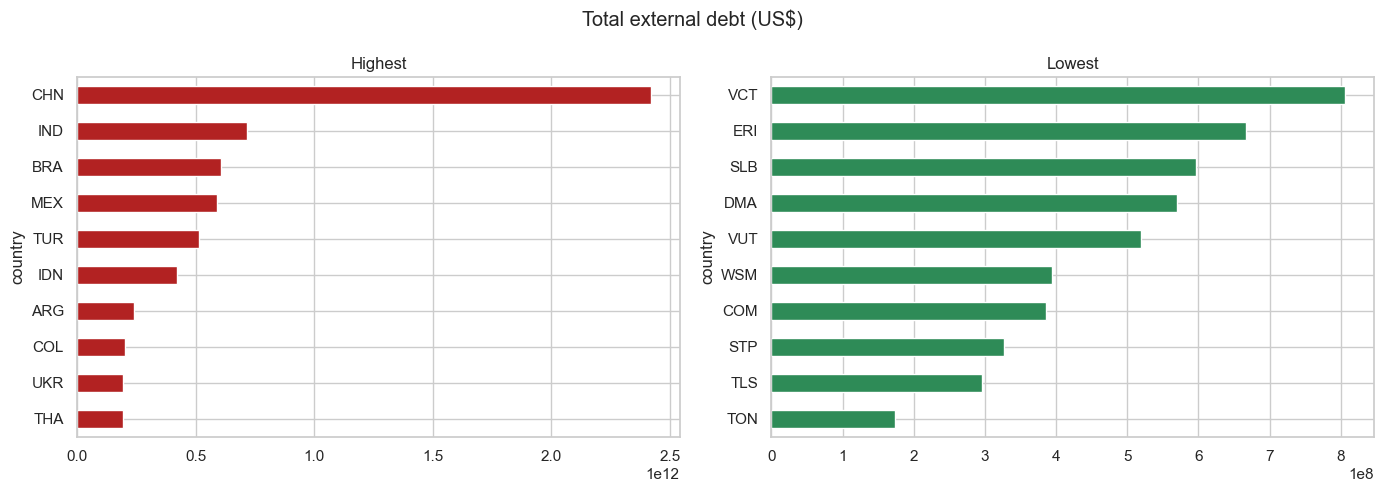


--- Debt (% of GNI): TOP 10 ---
country
MOZ    350.573067
LBN    331.649551
MNG    181.856577
SEN    150.690164
MUS    123.165055
LAO    115.404418
BTN    114.499504
ZMB    114.201909
MNE    108.635520
UKR    101.267170

--- Debt (% of GNI): BOTTOM 10 ---
country
MMR    15.275987
SOM    14.918887
GNQ    13.615096
CHN    13.000752
BWA    11.927533
IRQ     6.226399
TKM     5.216613
HTI     3.744845
DZA     2.667748
IRN     2.212806


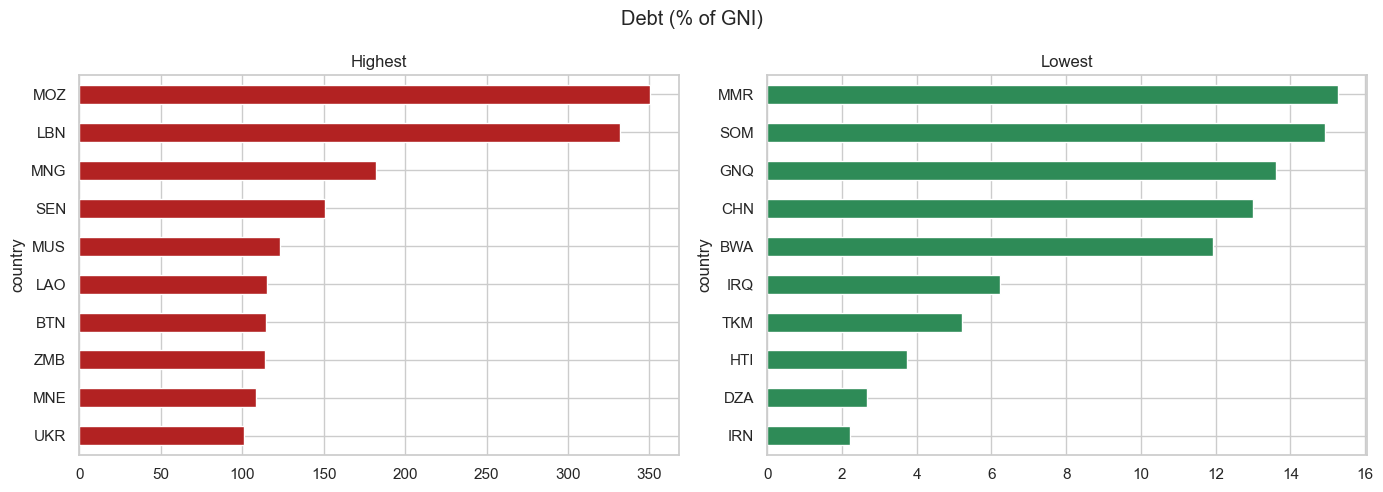


--- Debt service (% of exports): TOP 10 ---
country
SLV    96.198584
HTI    63.162659
EGY    49.229102
KAZ    48.434376
MOZ    46.509649
PNG    43.338271
COL    42.997593
SEN    41.805004
PAK    39.542584
ARG    38.253354

--- Debt service (% of exports): BOTTOM 10 ---
country
TLS    3.050648
IRQ    2.956762
SDN    2.956229
GUY    2.885728
AFG    2.673975
DJI    2.526753
COD    1.321422
DZA    0.797700
SOM    0.656955
IRN    0.284994


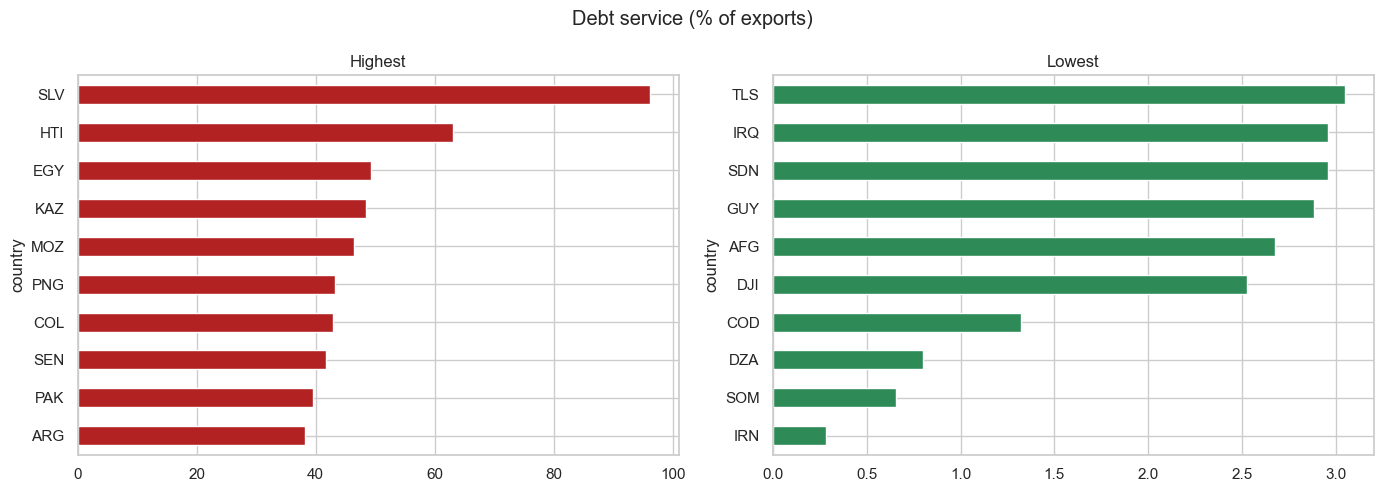


--- Summary statistics ---
                  count          mean           std           min           25%           50%           75%           90%           max  skew    cv
indicator_code                                                                                                                                    
concessional     120.0  1.936000e+01  1.993000e+01  0.000000e+00  3.270000e+00  1.213000e+01  3.214000e+01  4.412000e+01  8.528000e+01  1.25  1.03
total_debt       120.0  7.449934e+10  2.470678e+11  1.731761e+08  3.417751e+09  1.284569e+10  4.390611e+10  1.572000e+11  2.420000e+12  7.69  3.32
debt_exports     119.0  1.682100e+02  1.242200e+02  7.600000e+00  9.185000e+01  1.510600e+02  2.091000e+02  2.833300e+02  7.381600e+02  2.21  0.74
debt_gni         120.0  5.415000e+01  4.826000e+01  2.210000e+00  3.044000e+01  4.296000e+01  6.669000e+01  9.051000e+01  3.505700e+02  3.83  0.89
short_term_pct   120.0  1.181000e+01  1.151000e+01  0.000000e+00  2.650000e+00  9.140000e

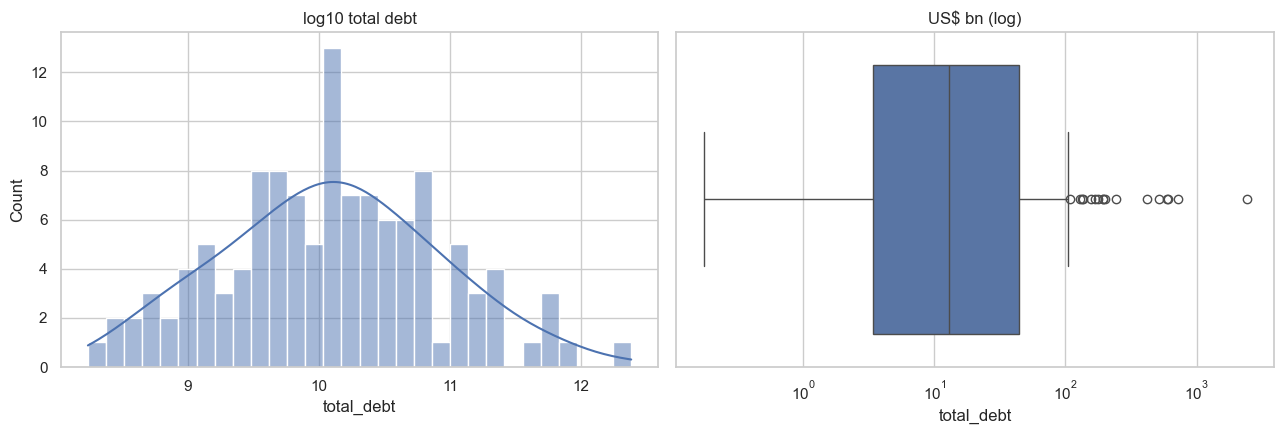

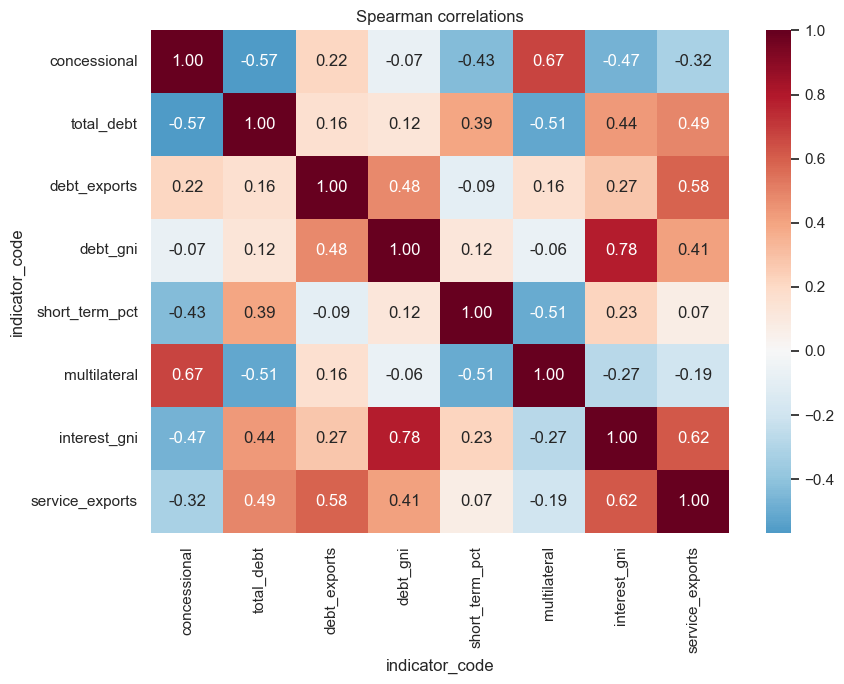


--- Pairwise tests ---
              x               y   n     rho      p
short_term_pct service_exports 119  0.0723 0.4344
  debt_exports service_exports 119  0.5843 0.0000
  concessional        debt_gni 120 -0.0737 0.4238

--- Aggregate debt (US$ bn) & YoY % ---
        US$bn  yoy_%
year               
2015  5871.0   -6.2
2016  6091.6    3.8
2017  6855.9   12.5
2018  7344.0    7.1
2019  7723.7    5.2
2020  8152.2    5.5
2021  8791.4    7.8
2022  8683.1   -1.2
2023  8841.0    1.8
2024  8939.9    1.1

--- Fastest growing debtors, CAGR 2014-2024 ---
country
UZB    19.1
RWA    16.2
SEN    15.9
MDV    15.6
TGO    15.3
CIV    15.3
BEN    14.5
EGY    14.1
GNB    13.9
DJI    13.8


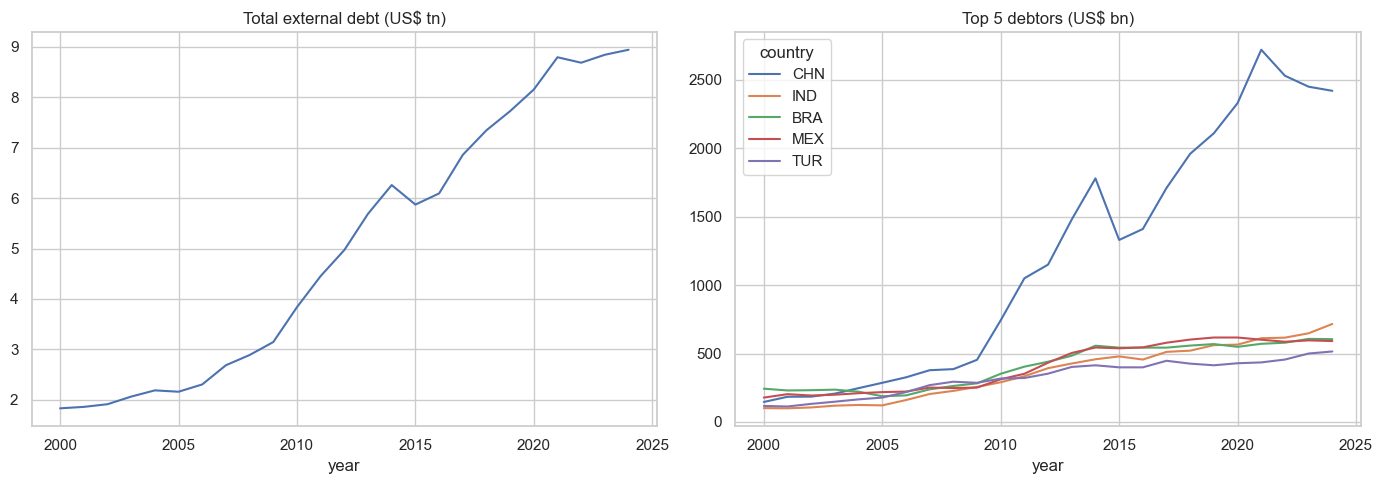


--- Median by debt-size quartile ---
 indicator_code  debt_gni  service_exports  short_term_pct  concessional
tier                                                                   
Q1 low              38.4              8.1             4.3          32.6
Q2                  38.0              9.6             5.8          15.6
Q3                  48.1             18.0             9.6           8.8
Q4 high             44.8             21.9            12.0           1.8
Kruskal-Wallis debt_gni: H=7.66, p=0.0535
Kruskal-Wallis service_exports: H=34.09, p=0.0000
Kruskal-Wallis short_term_pct: H=17.62, p=0.0005
Kruskal-Wallis concessional: H=36.88, p=0.0000

Done. Files saved in: C:\International_Debt Analysis System\debt_output


In [7]:
# ===== CELL 1: settings (edit these 2 lines only) =====
DATA_PATH   = r""            # e.g. r"C:\International_Debt Analysis System\Data\ids_data.csv"  (leave "" to auto-search)
LOOKUP_PATH = r"ids_indicator_lookup.csv"
OUT_DIR     = "debt_output"

# ===== CELL 2: analysis (run as-is) =====
import re
from pathlib import Path
import numpy as np, pandas as pd, seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats
sns.set_theme(style="whitegrid")
out = Path(OUT_DIR); out.mkdir(exist_ok=True)

# --- 1. find the data file -------------------------------------------------
if not DATA_PATH:
    roots = [Path("."), Path(".."), Path.home() / "Downloads", Path.home() / "Documents"]
    found = [f for r in roots if r.exists() for f in r.rglob("*.csv")
             if "lookup" not in f.name.lower() and f.stat().st_size > 200_000]
    if not found:
        raise SystemExit("Main IDS data CSV not found. Set DATA_PATH in Cell 1.")
    DATA_PATH = str(max(found, key=lambda f: f.stat().st_size))
print("Using data file:", DATA_PATH)

# --- 2. load + tidy --------------------------------------------------------
ALIAS = {"country": ["country name", "country", "economy"],
         "indicator_code": ["series code", "indicator_code", "indicator code"],
         "counterpart": ["counterpart-area name", "counterpart area", "counterpart"],
         "year": ["year", "time"], "value": ["value", "obs_value"]}
raw = pd.read_csv(DATA_PATH, low_memory=False, na_values=["..", "", "NA"])
low = {c.lower().strip(): c for c in raw.columns}
raw = raw.rename(columns={low[o]: k for k, v in ALIAS.items() for o in v if o in low})
ycols = [c for c in raw.columns if re.fullmatch(r"(19|20)\d{2}(\s*\[YR\d{4}\])?", str(c).strip())]
if ycols:
    raw = raw.melt(id_vars=[c for c in raw.columns if c not in ycols], value_vars=ycols,
                   var_name="year", value_name="value")
    raw["year"] = raw["year"].astype(str).str.extract(r"((?:19|20)\d{2})")[0]
if "country" not in raw.columns and "country_code" in raw.columns:
    raw["country"] = raw["country_code"]          # file has codes only
need = {"country", "indicator_code", "year", "value"} - set(raw.columns)
if need:
    raise SystemExit(f"Missing columns {need}. Your columns: {list(raw.columns)}")
if "counterpart" in raw.columns:
    raw = raw[raw["counterpart"].astype(str).str.lower().isin(["world", "all", "nan"])]
raw["year"] = pd.to_numeric(raw["year"], errors="coerce")
raw["value"] = pd.to_numeric(raw["value"], errors="coerce")
raw = raw.dropna(subset=["year", "value"]); raw["year"] = raw["year"].astype(int)
AGG = re.compile(r"income|region|IDA|IBRD|world|countries|developing|Sub-Saharan|Asia|Europe|"
                 r"Latin America|Middle East|North Africa|Caribbean|Pacific|Fragile|Heavily|"
                 r"Least developed|Small states|Arab|OECD|Euro area|members|total|blend|only", re.I)
AGG_CODES = set("WLD LMY LIC MIC LMC UMC HIC EAS EAP ECS ECA LCN LAC MEA MNA SAS SSF SSA AFE AFW ARB CEB CSS EAR EMU EUU FCS HPC IBD IBT IDA IDB IDX LDC LTE NAC OED OSS PRE PSS PST SST TEA TEC TLA TMN TSA TSS INX".split())
df = raw[~raw["country"].astype(str).str.contains(AGG) & ~raw["country"].astype(str).isin(AGG_CODES)]
print(f"{len(df):,} rows | {df.country.nunique()} countries | {df.year.min()}-{df.year.max()}")

# --- 3. key indicators -----------------------------------------------------
KEY = {"total_debt": "DT.DOD.DECT.CD", "debt_gni": "DT.DOD.DECT.GN.ZS",
       "debt_exports": "DT.DOD.DECT.EX.ZS", "service_exports": "DT.TDS.DECT.EX.ZS",
       "interest_gni": "DT.INT.DECT.GN.ZS", "short_term_pct": "DT.DOD.DSTC.ZS",
       "multilateral": "DT.DOD.MLAT.ZS", "concessional": "DT.DOD.ALLC.ZS",
       "reserves_debt": "FI.RES.TOTL.DT.ZS"}
inv = {v: k for k, v in KEY.items()}
sub = df[df.indicator_code.isin(KEY.values())].sort_values("year")
latest = (sub.groupby(["country", "indicator_code"]).tail(1)
             .pivot(index="country", columns="indicator_code", values="value").rename(columns=inv))
latest.to_csv(out / "latest_country_indicators.csv")
print("Indicators found:", list(latest.columns))

# --- 4. top / bottom countries --------------------------------------------
for col, label in [("total_debt", "Total external debt (US$)"),
                   ("debt_gni", "Debt (% of GNI)"), ("service_exports", "Debt service (% of exports)")]:
    if col in latest:
        s = latest[col].dropna().sort_values(ascending=False)
        print(f"\n--- {label}: TOP 10 ---\n{s.head(10).to_string()}")
        print(f"\n--- {label}: BOTTOM 10 ---\n{s.tail(10).to_string()}")
        fig, ax = plt.subplots(1, 2, figsize=(14, 5))
        s.head(10)[::-1].plot.barh(ax=ax[0], color="firebrick", title="Highest")
        s.tail(10)[::-1].plot.barh(ax=ax[1], color="seagreen", title="Lowest")
        fig.suptitle(label); plt.tight_layout(); fig.savefig(out / f"rank_{col}.png", dpi=130); plt.show()

# --- 5. distribution + summary statistics ---------------------------------
desc = latest.describe(percentiles=[.25, .5, .75, .9]).T
desc["skew"] = latest.skew(); desc["cv"] = desc["std"] / desc["mean"]
print("\n--- Summary statistics ---\n", desc.round(2).to_string()); desc.to_csv(out / "summary_stats.csv")
if "total_debt" in latest:
    s = latest.total_debt.dropna(); x = np.sort(s.values); n = len(x)
    print(f"\nTop-10 share of total debt: {s.nlargest(10).sum()/s.sum()*100:.1f}%")
    print(f"Gini of debt distribution: {(2*np.sum(np.arange(1,n+1)*x)/(n*x.sum()))-(n+1)/n:.3f}")
    fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
    sns.histplot(np.log10(s[s > 0]), bins=30, kde=True, ax=ax[0]); ax[0].set_title("log10 total debt")
    sns.boxplot(x=s / 1e9, ax=ax[1]); ax[1].set_xscale("log"); ax[1].set_title("US$ bn (log)")
    plt.tight_layout(); fig.savefig(out / "distribution.png", dpi=130); plt.show()

# --- 6. relationships ------------------------------------------------------
corr = latest.corr(method="spearman")
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=ax)
ax.set_title("Spearman correlations"); plt.tight_layout(); fig.savefig(out / "correlations.png", dpi=130); plt.show()
rows = []
for a, b in [("debt_gni", "reserves_debt"), ("short_term_pct", "service_exports"),
             ("debt_exports", "service_exports"), ("concessional", "debt_gni")]:
    if a in latest and b in latest:
        d = latest[[a, b]].dropna()
        if len(d) > 5:
            r, p = stats.spearmanr(d[a], d[b]); rows.append(dict(x=a, y=b, n=len(d), rho=r, p=p))
if rows: print("\n--- Pairwise tests ---\n", pd.DataFrame(rows).round(4).to_string(index=False))

# --- 7. trends -------------------------------------------------------------
t = df[df.indicator_code == KEY["total_debt"]].pivot_table(index="year", columns="country", values="value")
if not t.empty:
    g = t.sum(axis=1)
    print("\n--- Aggregate debt (US$ bn) & YoY % ---\n",
          pd.DataFrame({"US$bn": g/1e9, "yoy_%": g.pct_change()*100}).tail(10).round(1).to_string())
    last = t.index.max()
    if last - 10 in t.index:
        cagr = (((t.loc[last] / t.loc[last-10]) ** 0.1 - 1) * 100).replace([np.inf, -np.inf], np.nan).dropna()
        print(f"\n--- Fastest growing debtors, CAGR {last-10}-{last} ---\n{cagr.nlargest(10).round(1).to_string()}")
    fig, ax = plt.subplots(1, 2, figsize=(14, 5))
    (g/1e12).plot(ax=ax[0], title="Total external debt (US$ tn)")
    (t[t.loc[last].nlargest(5).index]/1e9).plot(ax=ax[1], title="Top 5 debtors (US$ bn)")
    plt.tight_layout(); fig.savefig(out / "trends.png", dpi=130); plt.show()

# --- 8. comparison by debt-size quartile ----------------------------------
if "total_debt" in latest:
    d = latest.dropna(subset=["total_debt"]).copy()
    d["tier"] = pd.qcut(d.total_debt, 4, labels=["Q1 low", "Q2", "Q3", "Q4 high"])
    cols = [c for c in ["debt_gni", "service_exports", "short_term_pct", "concessional", "reserves_debt"] if c in d]
    print("\n--- Median by debt-size quartile ---\n", d.groupby("tier", observed=True)[cols].median().round(1).to_string())
    for c in cols:
        gs = [g[c].dropna() for _, g in d.groupby("tier", observed=True)]
        if all(len(g) > 2 for g in gs):
            h, p = stats.kruskal(*gs); print(f"Kruskal-Wallis {c}: H={h:.2f}, p={p:.4f}")
print("\nDone. Files saved in:", out.resolve())

In [1]:
from db_connection import run_query
df = run_query("SELECT COUNT(*) AS rows_loaded FROM debt_data")
df

ModuleNotFoundError: No module named 'db_connection'

In [1]:
/* =====================================================================
   INTERNATIONAL DEBT DATABASE (MySQL 8.0+)
   Tables : countries, indicators, debt_data (+ staging_debt)
   Source : country_metadata_cleaned.csv (134 rows: 120 countries,
            14 aggregates) -> loaded below as INSERT statements.
   Note   : debt values file not provided; section 4 is ready for it.
   Run    : mysql --default-character-set=utf8mb4 -u root -p < debt_analysis.sql
   ===================================================================== */


/* ---------------------------------------------------------------------
   1. CREATE DATABASE
   --------------------------------------------------------------------- */
DROP DATABASE IF EXISTS debt_db;
CREATE DATABASE debt_db CHARACTER SET utf8mb4 COLLATE utf8mb4_unicode_ci;
USE debt_db;
SET NAMES utf8mb4 COLLATE utf8mb4_unicode_ci;   -- keeps names like Côte d'Ivoire intact; matches table collation


/* ---------------------------------------------------------------------
   2. RELATIONAL SCHEMA (PRIMARY KEYS + FOREIGN KEYS)
   --------------------------------------------------------------------- */

-- 2.1 Countries (dimension) - natural key = 3-letter code used in the data
CREATE TABLE countries (
    country_code          CHAR(3)      NOT NULL,
    country_name          VARCHAR(150) NOT NULL,
    country_long_name     VARCHAR(200) NULL,
    iso2_code             CHAR(2)      NULL,
    entity_type           ENUM('Country','Aggregate') NOT NULL,
    region                VARCHAR(60)  NULL,   -- NULL for aggregates
    income_group          VARCHAR(40)  NULL,   -- NULL for aggregates / not available
    lending_category      VARCHAR(20)  NULL,   -- IDA / IBRD / Blend
    is_hipc               TINYINT(1)   NOT NULL DEFAULT 0,
    currency_unit         VARCHAR(80)  NULL,
    debt_reporting_status VARCHAR(20)  NULL,   -- Actual / Estimate / Preliminary
    CONSTRAINT pk_countries     PRIMARY KEY (country_code),
    CONSTRAINT uq_country_name  UNIQUE (country_name),
    CONSTRAINT uq_iso2          UNIQUE (iso2_code),
    INDEX idx_region (region),
    INDEX idx_income (income_group)
) ENGINE=InnoDB;

-- 2.2 Indicators (dimension)
CREATE TABLE indicators (
    indicator_id    INT UNSIGNED NOT NULL AUTO_INCREMENT,
    indicator_code  VARCHAR(60)  NOT NULL,
    indicator_name  VARCHAR(255) NOT NULL,
    CONSTRAINT pk_indicators     PRIMARY KEY (indicator_id),
    CONSTRAINT uq_indicator_code UNIQUE (indicator_code)
) ENGINE=InnoDB;

-- 2.3 Debt data (fact)
CREATE TABLE debt_data (
    debt_id       BIGINT UNSIGNED NOT NULL AUTO_INCREMENT,
    country_code  CHAR(3)         NOT NULL,
    indicator_id  INT UNSIGNED    NOT NULL,
    year          SMALLINT        NOT NULL,
    value         DECIMAL(20,2)   NULL,
    CONSTRAINT pk_debt_data PRIMARY KEY (debt_id),
    CONSTRAINT uq_debt_obs  UNIQUE (country_code, indicator_id, year),
    CONSTRAINT fk_debt_country
        FOREIGN KEY (country_code) REFERENCES countries (country_code)
        ON UPDATE CASCADE ON DELETE RESTRICT,
    CONSTRAINT fk_debt_indicator
        FOREIGN KEY (indicator_id) REFERENCES indicators (indicator_id)
        ON UPDATE CASCADE ON DELETE RESTRICT,
    CONSTRAINT chk_year CHECK (year BETWEEN 1960 AND 2100),
    INDEX idx_debt_year      (year),
    INDEX idx_debt_indicator (indicator_id, year)
) ENGINE=InnoDB;

-- 2.4 Staging table for the debt values file
CREATE TABLE staging_debt (
    country_code    CHAR(3),
    indicator_code  VARCHAR(60),
    indicator_name  VARCHAR(255),
    year            SMALLINT,
    value           DECIMAL(20,2)
) ENGINE=InnoDB;


/* ---------------------------------------------------------------------
   3. INSERT CLEANED DATA - COUNTRIES (from country_metadata_cleaned.csv)
      'Not applicable (aggregate)' and 'Not available' are stored as NULL.
   --------------------------------------------------------------------- */
INSERT INTO countries
  (country_code, country_name, country_long_name, iso2_code, entity_type, region,
   income_group, lending_category, is_hipc, currency_unit, debt_reporting_status)
VALUES
('EAP','East Asia & Pacific (excluding high income)','East Asia & Pacific (excluding high income)','4E','Aggregate',NULL,NULL,NULL,0,NULL,NULL),
('ECA','Europe & Central Asia (excluding high income)','Europe & Central Asia (excluding high income)','7E','Aggregate',NULL,NULL,NULL,0,NULL,NULL),
('IDX','IDA only','IDA only','XI','Aggregate',NULL,NULL,NULL,0,NULL,NULL),
('IDA','IDA total','IDA total','XG','Aggregate',NULL,NULL,NULL,0,NULL,NULL),
('LAC','Latin America & Caribbean (excluding high income)','Latin America & Caribbean (excluding high income)','XJ','Aggregate',NULL,NULL,NULL,0,NULL,NULL),
('LDC','Least developed countries: UN classification','Least developed countries: UN classification','XL','Aggregate',NULL,NULL,NULL,0,NULL,NULL),
('LMY','Low & middle income','Low & middle income','XO','Aggregate',NULL,NULL,NULL,0,NULL,NULL),
('LIC','Low income','Low income','XM','Aggregate',NULL,NULL,NULL,0,NULL,NULL),
('LMC','Lower middle income','Lower middle income','XN','Aggregate',NULL,NULL,NULL,0,NULL,NULL),
('MNA','Middle East, North Africa, Afghanistan & Pakistan (excluding high income)','Middle East, North Africa, Afghanistan & Pakistan (excluding high income)','XQ','Aggregate',NULL,NULL,NULL,0,NULL,NULL),
('MIC','Middle income','Middle income','XP','Aggregate',NULL,NULL,NULL,0,NULL,NULL),
('SAS','South Asia','South Asia','8S','Aggregate',NULL,NULL,NULL,0,NULL,NULL),
('SSA','Sub-Saharan Africa (excluding high income)','Sub-Saharan Africa (excluding high income)','ZF','Aggregate',NULL,NULL,NULL,0,NULL,NULL),
('UMC','Upper middle income','Upper middle income','XT','Aggregate',NULL,NULL,NULL,0,NULL,NULL),
('AFG','Afghanistan','Islamic State of Afghanistan','AF','Country','Middle East & North Africa','Low income','IDA',1,'Afghan afghani','Estimate'),
('ALB','Albania','Republic of Albania','AL','Country','Europe & Central Asia','Upper middle income','IBRD',0,'Albanian lek','Actual'),
('DZA','Algeria','People''s Democratic Republic of Algeria','DZ','Country','Middle East & North Africa','Upper middle income','IBRD',0,'Algerian dinar','Actual'),
('AGO','Angola','People''s Republic of Angola','AO','Country','Sub-Saharan Africa','Lower middle income','IBRD',0,'Angolan kwanza','Actual'),
('ARG','Argentina','Argentine Republic','AR','Country','Latin America & Caribbean','Upper middle income','IBRD',0,'Argentine peso','Actual'),
('ARM','Armenia','Republic of Armenia','AM','Country','Europe & Central Asia','Upper middle income','IBRD',0,'Armenian dram','Actual'),
('AZE','Azerbaijan','Republic of Azerbaijan','AZ','Country','Europe & Central Asia','Upper middle income','IBRD',0,'New Azeri manat','Actual'),
('BGD','Bangladesh','People''s Republic of Bangladesh','BD','Country','South Asia','Lower middle income','IDA',0,'Bangladeshi taka','Actual'),
('BLR','Belarus','Republic of Belarus','BY','Country','Europe & Central Asia','Upper middle income','IBRD',0,'Belarusian rubel','Estimate'),
('BLZ','Belize','Belize','BZ','Country','Latin America & Caribbean','Upper middle income','Blend',0,'Belize dollar','Actual'),
('BEN','Benin','Republic of Benin','BJ','Country','Sub-Saharan Africa','Lower middle income','IDA',1,'West African CFA franc','Actual'),
('BTN','Bhutan','Kingdom of Bhutan','BT','Country','South Asia','Lower middle income','IDA',0,'Bhutanese ngultrum','Actual'),
('BOL','Bolivia, Plurinational State of','Plurinational State of Bolivia','BO','Country','Latin America & Caribbean','Lower middle income','IBRD',1,'Bolivian Boliviano','Actual'),
('BIH','Bosnia and Herzegovina','Bosnia and Herzegovina','BA','Country','Europe & Central Asia','Upper middle income','IBRD',0,'Bosnia and Herzegovina convertible mark','Actual'),
('BWA','Botswana','Republic of Botswana','BW','Country','Sub-Saharan Africa','Upper middle income','IBRD',0,'Botswana pula','Actual'),
('BRA','Brazil','Federative Republic of Brazil','BR','Country','Latin America & Caribbean','Upper middle income','IBRD',0,'Brazilian real','Actual'),
('BFA','Burkina Faso','Burkina Faso','BF','Country','Sub-Saharan Africa','Low income','IDA',1,'West African CFA franc','Actual'),
('BDI','Burundi','Republic of Burundi','BI','Country','Sub-Saharan Africa','Low income','IDA',1,'Burundi franc','Actual'),
('CPV','Cabo Verde','Republic of Cabo Verde','CV','Country','Sub-Saharan Africa','Upper middle income','Blend',0,'Cabo Verde escudo','Actual'),
('KHM','Cambodia','Kingdom of Cambodia','KH','Country','East Asia & Pacific','Lower middle income','IDA',0,'Cambodian riel','Actual'),
('CMR','Cameroon','Republic of Cameroon','CM','Country','Sub-Saharan Africa','Lower middle income','Blend',1,'Central African CFA franc','Actual'),
('CAF','Central African Republic','Central African Republic','CF','Country','Sub-Saharan Africa','Low income','IDA',1,'Central African CFA franc','Actual'),
('TCD','Chad','Republic of Chad','TD','Country','Sub-Saharan Africa','Low income','IDA',1,'Central African CFA franc','Preliminary'),
('CHN','China','People''s Republic of China','CN','Country','East Asia & Pacific','Upper middle income','IBRD',0,'Chinese yuan','Preliminary'),
('COL','Colombia','Republic of Colombia','CO','Country','Latin America & Caribbean','Upper middle income','IBRD',0,'Colombian peso','Actual'),
('COM','Comoros','Union of the Comoros','KM','Country','Sub-Saharan Africa','Lower middle income','IDA',1,'Comorian franc','Actual'),
('COD','Congo, Democratic Republic of','Democratic Republic of the Congo','CD','Country','Sub-Saharan Africa','Low income','IDA',1,'Congolese franc','Actual'),
('COG','Congo, Republic of','Republic of Congo','CG','Country','Sub-Saharan Africa','Lower middle income','Blend',1,'Central African CFA franc','Actual'),
('CIV','Côte d''Ivoire','Republic of Côte d''Ivoire','CI','Country','Sub-Saharan Africa','Lower middle income','Blend',1,'West African CFA franc','Actual'),
('DJI','Djibouti','Republic of Djibouti','DJ','Country','Middle East & North Africa','Lower middle income','IDA',0,'Djibouti franc','Actual'),
('DMA','Dominica','Commonwealth of Dominica','DM','Country','Latin America & Caribbean','Upper middle income','Blend',0,'East Caribbean dollar','Actual'),
('DOM','Dominican Republic','Dominican Republic','DO','Country','Latin America & Caribbean','Upper middle income','IBRD',0,'Dominican peso','Actual'),
('ECU','Ecuador','Republic of Ecuador','EC','Country','Latin America & Caribbean','Upper middle income','IBRD',0,'U.S. dollar','Preliminary'),
('EGY','Egypt, Arab Republic of','Arab Republic of Egypt','EG','Country','Middle East & North Africa','Lower middle income','IBRD',0,'Egyptian pound','Actual'),
('SLV','El Salvador','Republic of El Salvador','SV','Country','Latin America & Caribbean','Upper middle income','IBRD',0,'U.S. dollar','Actual'),
('GNQ','Equatorial Guinea','Republic of Equatorial Guinea','GQ','Country','Sub-Saharan Africa','Upper middle income','IBRD',0,'Central African CFA franc','Actual'),
('ERI','Eritrea','State of Eritrea','ER','Country','Sub-Saharan Africa','Low income','IDA',1,'Eritrean nakfa','Estimate'),
('SWZ','Eswatini','Kingdom of Eswatini','SZ','Country','Sub-Saharan Africa','Lower middle income','Blend',0,'Swazi lilangeni','Actual'),
('ETH','Ethiopia','Federal Democratic Republic of Ethiopia','ET','Country','Sub-Saharan Africa',NULL,'IDA',1,'Ethiopian birr','Actual'),
('FJI','Fiji','Republic of Fiji','FJ','Country','East Asia & Pacific','Upper middle income','Blend',0,'Fijian dollar','Actual'),
('GAB','Gabon','Gabonese Republic','GA','Country','Sub-Saharan Africa','Upper middle income','IBRD',0,'Central African CFA franc','Actual'),
('GMB','Gambia, The','Republic of The Gambia','GM','Country','Sub-Saharan Africa','Low income','IDA',1,'Gambian dalasi','Actual'),
('GEO','Georgia','Georgia','GE','Country','Europe & Central Asia','Upper middle income','IBRD',0,'Georgian lari','Actual'),
('GHA','Ghana','Republic of Ghana','GH','Country','Sub-Saharan Africa','Lower middle income','IDA',1,'New Ghanaian cedi','Actual'),
('GRD','Grenada','Grenada','GD','Country','Latin America & Caribbean','Upper middle income','Blend',0,'East Caribbean dollar','Actual'),
('GTM','Guatemala','Republic of Guatemala','GT','Country','Latin America & Caribbean','Upper middle income','IBRD',0,'Guatemalan quetzal','Actual'),
('GIN','Guinea','Republic of Guinea','GN','Country','Sub-Saharan Africa','Lower middle income','IDA',1,'Guinean franc','Actual'),
('GNB','Guinea-Bissau','Republic of Guinea-Bissau','GW','Country','Sub-Saharan Africa','Low income','IDA',1,'West African CFA franc','Actual'),
('GUY','Guyana','Co-operative Republic of Guyana','GY','Country','Latin America & Caribbean','High income','IDA',1,'Guyana dollar','Actual'),
('HTI','Haiti','Republic of Haiti','HT','Country','Latin America & Caribbean','Lower middle income','IDA',1,'Haitian gourde','Actual'),
('HND','Honduras','Republic of Honduras','HN','Country','Latin America & Caribbean','Lower middle income','IDA',1,'Honduran lempira','Actual'),
('IND','India','Republic of India','IN','Country','South Asia','Lower middle income','IBRD',0,'Indian rupee','Actual'),
('IDN','Indonesia','Republic of Indonesia','ID','Country','East Asia & Pacific','Upper middle income','IBRD',0,'Indonesian rupiah','Actual'),
('IRN','Iran, Islamic Republic of','Islamic Republic of Iran','IR','Country','Middle East & North Africa','Upper middle income','IBRD',0,'Iranian rial','Estimate'),
('IRQ','Iraq','Republic of Iraq','IQ','Country','Middle East & North Africa','Upper middle income','IBRD',0,'Iraqi dinar','Actual'),
('JAM','Jamaica','Jamaica','JM','Country','Latin America & Caribbean','Upper middle income','IBRD',0,'Jamaican dollar','Actual'),
('JOR','Jordan','Hashemite Kingdom of Jordan','JO','Country','Middle East & North Africa','Lower middle income','IBRD',0,'Jordanian dinar','Actual'),
('KAZ','Kazakhstan','Republic of Kazakhstan','KZ','Country','Europe & Central Asia','Upper middle income','IBRD',0,'Kazakh tenge','Actual'),
('KEN','Kenya','Republic of Kenya','KE','Country','Sub-Saharan Africa','Lower middle income','Blend',0,'Kenyan shilling','Actual'),
('XKX','Kosovo','Republic of Kosovo','XK','Country','Europe & Central Asia','Upper middle income','IDA',0,'Euro','Actual'),
('KGZ','Kyrgyz Republic','Kyrgyz Republic','KG','Country','Europe & Central Asia','Lower middle income','IDA',1,'Kyrgyz som','Actual'),
('LAO','Lao PDR','Lao People''s Democratic Republic','LA','Country','East Asia & Pacific','Lower middle income','IDA',0,'Lao kip','Actual'),
('LBN','Lebanon','Lebanese Republic','LB','Country','Middle East & North Africa','Lower middle income','IBRD',0,'Lebanese pound','Estimate'),
('LSO','Lesotho','Kingdom of Lesotho','LS','Country','Sub-Saharan Africa','Lower middle income','IDA',0,'Lesotho loti','Actual'),
('LBR','Liberia','Republic of Liberia','LR','Country','Sub-Saharan Africa','Low income','IDA',1,'Liberian dollar','Actual'),
('MDG','Madagascar','Republic of Madagascar','MG','Country','Sub-Saharan Africa','Low income','IDA',1,'Malagasy ariary','Actual'),
('MWI','Malawi','Republic of Malawi','MW','Country','Sub-Saharan Africa','Low income','IDA',1,'Malawi kwacha','Actual'),
('MDV','Maldives','Republic of Maldives','MV','Country','South Asia','Upper middle income','IDA',0,'Maldivian rufiyaa','Actual'),
('MLI','Mali','Republic of Mali','ML','Country','Sub-Saharan Africa','Low income','IDA',1,'West African CFA franc','Actual'),
('MRT','Mauritania','Islamic Republic of Mauritania','MR','Country','Sub-Saharan Africa','Lower middle income','IDA',1,'Mauritanian ouguiya','Actual'),
('MUS','Mauritius','Republic of Mauritius','MU','Country','Sub-Saharan Africa','Upper middle income','IBRD',0,'Mauritian rupee','Actual'),
('MEX','Mexico','United Mexican States','MX','Country','Latin America & Caribbean','Upper middle income','IBRD',0,'Mexican peso','Actual'),
('MDA','Moldova','Republic of Moldova','MD','Country','Europe & Central Asia','Upper middle income','IBRD',0,'Moldovan leu','Actual'),
('MNG','Mongolia','Mongolia','MN','Country','East Asia & Pacific','Upper middle income','IBRD',0,'Mongolian tugrik','Actual'),
('MNE','Montenegro','Montenegro','ME','Country','Europe & Central Asia','Upper middle income','IBRD',0,'Euro','Actual'),
('MAR','Morocco','Kingdom of Morocco','MA','Country','Middle East & North Africa','Lower middle income','IBRD',0,'Moroccan dirham','Actual'),
('MOZ','Mozambique','Republic of Mozambique','MZ','Country','Sub-Saharan Africa','Low income','IDA',1,'New Mozambican metical','Actual'),
('MMR','Myanmar','Republic of the Union of Myanmar','MM','Country','East Asia & Pacific','Lower middle income','IDA',0,'Myanmar kyat','Actual'),
('NPL','Nepal','Nepal','NP','Country','South Asia','Lower middle income','IDA',0,'Nepalese rupee','Actual'),
('NIC','Nicaragua','Republic of Nicaragua','NI','Country','Latin America & Caribbean','Lower middle income','IDA',1,'Nicaraguan gold cordoba','Actual'),
('NER','Niger','Republic of Niger','NE','Country','Sub-Saharan Africa','Low income','IDA',1,'West African CFA franc','Actual'),
('NGA','Nigeria','Federal Republic of Nigeria','NG','Country','Sub-Saharan Africa','Lower middle income','Blend',0,'Nigerian naira','Actual'),
('MKD','North Macedonia','Republic of North Macedonia','MK','Country','Europe & Central Asia','Upper middle income','IBRD',0,'Macedonian denar','Actual'),
('PAK','Pakistan','Islamic Republic of Pakistan','PK','Country','Middle East & North Africa','Lower middle income','Blend',0,'Pakistani rupee','Actual'),
('PNG','Papua New Guinea','The Independent State of Papua New Guinea','PG','Country','East Asia & Pacific','Lower middle income','Blend',0,'Papua New Guinea kina','Actual'),
('PRY','Paraguay','Republic of Paraguay','PY','Country','Latin America & Caribbean','Upper middle income','IBRD',0,'Paraguayan guarani','Actual'),
('PER','Peru','Republic of Peru','PE','Country','Latin America & Caribbean','Upper middle income','IBRD',0,'Peruvian new sol','Actual'),
('PHL','Philippines','Republic of the Philippines','PH','Country','East Asia & Pacific','Lower middle income','IBRD',0,'Philippine peso','Actual'),
('RWA','Rwanda','Republic of Rwanda','RW','Country','Sub-Saharan Africa','Low income','IDA',1,'Rwandan franc','Actual'),
('WSM','Samoa','Independent State of Samoa','WS','Country','East Asia & Pacific','Upper middle income','IDA',0,'Samoan tala','Actual'),
('SEN','Senegal','Republic of Senegal','SN','Country','Sub-Saharan Africa','Lower middle income','IDA',1,'West African CFA franc','Actual'),
('SRB','Serbia','Republic of Serbia','RS','Country','Europe & Central Asia','Upper middle income','IBRD',0,'New Serbian dinar','Actual'),
('SLE','Sierra Leone','Republic of Sierra Leone','SL','Country','Sub-Saharan Africa','Low income','IDA',1,'Sierra Leonean leone','Actual'),
('SLB','Solomon Islands','Solomon Islands','SB','Country','East Asia & Pacific','Lower middle income','IDA',0,'Solomon Islands dollar','Actual'),
('SOM','Somalia, Fed. Rep.','Federal Republic of Somalia','SO','Country','Sub-Saharan Africa','Low income','IDA',1,'Somali shilling','Actual'),
('ZAF','South Africa','Republic of South Africa','ZA','Country','Sub-Saharan Africa','Upper middle income','IBRD',0,'South African rand','Actual'),
('LKA','Sri Lanka','Democratic Socialist Republic of Sri Lanka','LK','Country','South Asia','Lower middle income','IDA',0,'Sri Lankan rupee','Actual'),
('LCA','St. Lucia','St. Lucia','LC','Country','Latin America & Caribbean','Upper middle income','Blend',0,'East Caribbean dollar','Actual'),
('VCT','St. Vincent and the Grenadines','St. Vincent and the Grenadines','VC','Country','Latin America & Caribbean','Upper middle income','Blend',0,'East Caribbean dollar','Actual'),
('SDN','Sudan','Republic of the Sudan','SD','Country','Sub-Saharan Africa','Low income','IDA',1,'Sudanese pound','Estimate'),
('SUR','Suriname','Republic of Suriname','SR','Country','Latin America & Caribbean','Upper middle income','Blend',0,'Suriname dollar','Actual'),
('SYR','Syrian Arab Republic','Syrian Arab Republic','SY','Country','Middle East & North Africa','Low income','IDA',0,'Syrian pound','Estimate'),
('STP','São Tomé and Principe','Democratic Republic of São Tomé and Principe','ST','Country','Sub-Saharan Africa','Lower middle income','IDA',1,'São Tomé and Principe dobra','Actual'),
('TJK','Tajikistan','Republic of Tajikistan','TJ','Country','Europe & Central Asia','Lower middle income','IDA',0,'Tajik somoni','Actual'),
('TZA','Tanzania','United Republic of Tanzania','TZ','Country','Sub-Saharan Africa','Lower middle income','IDA',1,'Tanzanian shilling','Actual'),
('THA','Thailand','Kingdom of Thailand','TH','Country','East Asia & Pacific','Upper middle income','IBRD',0,'Thai baht','Actual'),
('TLS','Timor-Leste','Democratic Republic of Timor-Leste','TL','Country','East Asia & Pacific','Lower middle income','Blend',0,'U.S. dollar','Actual'),
('TGO','Togo','Republic of Togo','TG','Country','Sub-Saharan Africa','Low income','IDA',1,'West African CFA franc','Actual'),
('TON','Tonga','Kingdom of Tonga','TO','Country','East Asia & Pacific','Upper middle income','IDA',0,'Tongan pa''anga','Actual'),
('TUN','Tunisia','Republic of Tunisia','TN','Country','Middle East & North Africa','Lower middle income','IBRD',0,'Tunisian dinar','Actual'),
('TKM','Turkmenistan','Turkmenistan','TM','Country','Europe & Central Asia','Upper middle income','IBRD',0,'New Turkmen manat','Actual'),
('TUR','Türkiye','Republic of Türkiye','TR','Country','Europe & Central Asia','Upper middle income','IBRD',0,'New Turkish lira','Actual'),
('UGA','Uganda','Republic of Uganda','UG','Country','Sub-Saharan Africa','Low income','IDA',1,'Ugandan shilling','Actual'),
('UKR','Ukraine','Ukraine','UA','Country','Europe & Central Asia','Upper middle income','IBRD',0,'Ukrainian hryvnia','Actual'),
('UZB','Uzbekistan','Republic of Uzbekistan','UZ','Country','Europe & Central Asia','Lower middle income','Blend',0,'Uzbek som','Actual'),
('VUT','Vanuatu','Republic of Vanuatu','VU','Country','East Asia & Pacific','Lower middle income','IDA',0,'Vanuatu vatu','Actual'),
('VNM','Viet Nam','Socialist Republic of Viet Nam','VN','Country','East Asia & Pacific','Lower middle income','IBRD',0,'Vietnamese dong','Actual'),
('YEM','Yemen, Republic of','Republic of Yemen','YE','Country','Middle East & North Africa','Low income','IDA',0,'Yemeni rial','Preliminary'),
('ZMB','Zambia','Republic of Zambia','ZM','Country','Sub-Saharan Africa','Lower middle income','IDA',1,'New Zambian kwacha','Actual'),
('ZWE','Zimbabwe','Republic of Zimbabwe','ZW','Country','Sub-Saharan Africa','Lower middle income','Blend',0,'Zimbabwean Zimbabwe Gold','Actual');


-- Verify
SELECT entity_type, COUNT(*) AS n FROM countries GROUP BY entity_type;   -- 120 / 14


/* ---------------------------------------------------------------------
   4. INSERT CLEANED DATA - INDICATORS + DEBT VALUES
      Expected CSV (long format, header row):
      country_code, indicator_code, indicator_name, year, value
   --------------------------------------------------------------------- */
-- OPTIONAL: bulk-load the debt CSV (LOAD DATA LOCAL is OFF by default -> error 3948).
-- To use it: run  SET GLOBAL local_infile = 1;  then connect with
--   mysql --local-infile=1 -u root -p debt_db
-- and un-comment the block below. Alternatives: debt_pipeline.py or
-- MySQL Workbench "Table Data Import Wizard" into staging_debt.
--
-- LOAD DATA LOCAL INFILE 'C:/data/cleaned_debt_data.csv'
-- INTO TABLE staging_debt
-- FIELDS TERMINATED BY ',' OPTIONALLY ENCLOSED BY '"'
-- LINES TERMINATED BY '\r\n'
-- IGNORE 1 ROWS
-- (country_code, indicator_code, indicator_name, year, @value)
-- SET value = NULLIF(TRIM(@value), '');

-- The statements below are safe to run with an empty staging_debt (0 rows inserted).

INSERT INTO indicators (indicator_code, indicator_name)
SELECT indicator_code, MAX(indicator_name)
FROM staging_debt
WHERE indicator_code IS NOT NULL
GROUP BY indicator_code;

INSERT INTO debt_data (country_code, indicator_id, year, value)
SELECT s.country_code, i.indicator_id, s.year, s.value
FROM staging_debt s
JOIN indicators i ON i.indicator_code = s.indicator_code
JOIN countries  c ON c.country_code   = s.country_code;   -- drops codes missing from metadata

-- Rows rejected because the country code is not in the metadata (should be 0)
SELECT DISTINCT s.country_code
FROM staging_debt s
LEFT JOIN countries c ON c.country_code = s.country_code
WHERE c.country_code IS NULL;

-- DROP TABLE staging_debt;   -- once verified


/* ---------------------------------------------------------------------
   5. INTEGRITY CHECKS
   --------------------------------------------------------------------- */
SELECT 'countries' AS tbl, COUNT(*) AS row_count FROM countries
UNION ALL SELECT 'indicators', COUNT(*) FROM indicators
UNION ALL SELECT 'debt_data',  COUNT(*) FROM debt_data;

SELECT i.indicator_name, COUNT(*) AS total_rows,
       SUM(d.value IS NULL) AS null_values,
       ROUND(100 * AVG(d.value IS NULL), 2) AS null_pct
FROM debt_data d JOIN indicators i USING (indicator_id)
GROUP BY i.indicator_name
ORDER BY null_pct DESC;


/* ---------------------------------------------------------------------
   6. ANALYSIS QUERIES
   Set @indicator to your dataset's indicator code (keep the COLLATE clause,
   otherwise error 1267 'Illegal mix of collations').
   Aggregates are excluded with entity_type = 'Country' unless noted.
   --------------------------------------------------------------------- */
SET @indicator = 'DT.DOD.DECT.CD' COLLATE utf8mb4_unicode_ci;   -- e.g. total external debt stocks (current US$)

-- ---- A. Metadata-only queries (run immediately after section 3) ----

-- A1. Countries by region and income group
SELECT region, income_group, COUNT(*) AS countries
FROM countries
WHERE entity_type = 'Country'
GROUP BY region, income_group
ORDER BY region, countries DESC;

-- A2. HIPC countries by region
SELECT region, COUNT(*) AS hipc_countries
FROM countries
WHERE is_hipc = 1
GROUP BY region
ORDER BY hipc_countries DESC;

-- A3. Lending category vs debt reporting status
SELECT lending_category, debt_reporting_status, COUNT(*) AS countries
FROM countries
WHERE entity_type = 'Country'
GROUP BY lending_category, debt_reporting_status
ORDER BY lending_category, countries DESC;

-- A4. Countries sharing a currency (e.g. CFA franc, euro)
SELECT currency_unit, COUNT(*) AS countries, GROUP_CONCAT(country_name ORDER BY country_name SEPARATOR '; ') AS members
FROM countries
WHERE entity_type = 'Country'
GROUP BY currency_unit
HAVING COUNT(*) > 1
ORDER BY countries DESC;

-- ---- B. Debt analysis (run after section 4) ----

-- B1. Top 10 debtor countries, latest year
SELECT c.country_name, c.region, d.year, d.value AS total_debt
FROM debt_data d
JOIN countries  c USING (country_code)
JOIN indicators i USING (indicator_id)
WHERE i.indicator_code = @indicator
  AND c.entity_type = 'Country'
  AND d.year = (SELECT MAX(year) FROM debt_data)
  AND d.value IS NOT NULL
ORDER BY d.value DESC
LIMIT 10;

-- B2. Debt trend by year (countries only)
SELECT d.year, SUM(d.value) AS total_debt,
       COUNT(DISTINCT d.country_code) AS countries_reporting
FROM debt_data d
JOIN countries  c USING (country_code)
JOIN indicators i USING (indicator_id)
WHERE i.indicator_code = @indicator AND c.entity_type = 'Country'
GROUP BY d.year
ORDER BY d.year;

-- B3. Year-over-year growth per country
SELECT c.country_name, d.year, d.value,
       ROUND(100 * (d.value - LAG(d.value) OVER w)
                 / NULLIF(LAG(d.value) OVER w, 0), 2) AS yoy_growth_pct
FROM debt_data d
JOIN countries  c USING (country_code)
JOIN indicators i USING (indicator_id)
WHERE i.indicator_code = @indicator AND c.entity_type = 'Country'
WINDOW w AS (PARTITION BY d.country_code ORDER BY d.year)
ORDER BY c.country_name, d.year;

-- B4. Total and average debt by region (latest year)
SELECT c.region, COUNT(DISTINCT c.country_code) AS countries,
       ROUND(AVG(d.value), 2) AS avg_debt, SUM(d.value) AS total_debt
FROM debt_data d
JOIN countries  c USING (country_code)
JOIN indicators i USING (indicator_id)
WHERE i.indicator_code = @indicator AND c.entity_type = 'Country'
  AND d.year = (SELECT MAX(year) FROM debt_data)
GROUP BY c.region
ORDER BY total_debt DESC;

-- B5. Average debt by income group (latest year)
SELECT COALESCE(c.income_group, 'Unclassified') AS income_group,
       COUNT(DISTINCT c.country_code) AS countries,
       ROUND(AVG(d.value), 2) AS avg_debt
FROM debt_data d
JOIN countries  c USING (country_code)
JOIN indicators i USING (indicator_id)
WHERE i.indicator_code = @indicator AND c.entity_type = 'Country'
  AND d.year = (SELECT MAX(year) FROM debt_data)
GROUP BY c.income_group
ORDER BY avg_debt DESC;

-- B6. HIPC vs non-HIPC average debt by year
SELECT d.year, c.is_hipc, ROUND(AVG(d.value), 2) AS avg_debt
FROM debt_data d
JOIN countries  c USING (country_code)
JOIN indicators i USING (indicator_id)
WHERE i.indicator_code = @indicator AND c.entity_type = 'Country'
GROUP BY d.year, c.is_hipc
ORDER BY d.year, c.is_hipc;

-- B7. Debt by lending category (latest year)
SELECT c.lending_category, COUNT(DISTINCT c.country_code) AS countries,
       SUM(d.value) AS total_debt, ROUND(AVG(d.value), 2) AS avg_debt
FROM debt_data d
JOIN countries  c USING (country_code)
JOIN indicators i USING (indicator_id)
WHERE i.indicator_code = @indicator AND c.entity_type = 'Country'
  AND d.year = (SELECT MAX(year) FROM debt_data)
GROUP BY c.lending_category
ORDER BY total_debt DESC;

-- B8. Share of total debt per country (latest year)
SELECT c.country_name, d.value,
       ROUND(100 * d.value / SUM(d.value) OVER (), 2) AS share_pct
FROM debt_data d
JOIN countries  c USING (country_code)
JOIN indicators i USING (indicator_id)
WHERE i.indicator_code = @indicator AND c.entity_type = 'Country'
  AND d.year = (SELECT MAX(year) FROM debt_data) AND d.value IS NOT NULL
ORDER BY share_pct DESC;

-- B9. Rank within region (latest year)
SELECT c.region, c.country_name, d.value,
       RANK() OVER (PARTITION BY c.region ORDER BY d.value DESC) AS region_rank
FROM debt_data d
JOIN countries  c USING (country_code)
JOIN indicators i USING (indicator_id)
WHERE i.indicator_code = @indicator AND c.entity_type = 'Country'
  AND d.year = (SELECT MAX(year) FROM debt_data) AND d.value IS NOT NULL
ORDER BY c.region, region_rank;

-- B10. Countries above the average (latest year)
SELECT c.country_name, d.value
FROM debt_data d
JOIN countries  c USING (country_code)
JOIN indicators i USING (indicator_id)
WHERE i.indicator_code = @indicator AND c.entity_type = 'Country'
  AND d.year = (SELECT MAX(year) FROM debt_data)
  AND d.value > (SELECT AVG(d2.value)
                 FROM debt_data d2
                 JOIN countries  c2 USING (country_code)
                 JOIN indicators i2 USING (indicator_id)
                 WHERE i2.indicator_code = @indicator AND c2.entity_type = 'Country'
                   AND d2.year = (SELECT MAX(year) FROM debt_data))
ORDER BY d.value DESC;

-- B11. 10-year change per country
WITH w AS (
    SELECT d.country_code,
           MAX(CASE WHEN d.year = mx.y      THEN d.value END) AS latest,
           MAX(CASE WHEN d.year = mx.y - 10 THEN d.value END) AS decade_ago
    FROM debt_data d
    JOIN indicators i USING (indicator_id)
    CROSS JOIN (SELECT MAX(year) AS y FROM debt_data) mx
    WHERE i.indicator_code = @indicator
    GROUP BY d.country_code
)
SELECT c.country_name, w.decade_ago, w.latest,
       ROUND(100 * (w.latest - w.decade_ago) / NULLIF(w.decade_ago, 0), 2) AS change_pct
FROM w JOIN countries c USING (country_code)
WHERE c.entity_type = 'Country' AND w.latest IS NOT NULL AND w.decade_ago IS NOT NULL
ORDER BY change_pct DESC
LIMIT 15;

-- B12. Reusable view
CREATE OR REPLACE VIEW v_country_debt AS
SELECT c.country_code, c.country_name, c.region, c.income_group,
       c.lending_category, c.is_hipc, c.entity_type,
       i.indicator_code, i.indicator_name, d.year, d.value
FROM debt_data d
JOIN countries  c USING (country_code)
JOIN indicators i USING (indicator_id);

#debt_long

/* =====================================================================
   INTERNATIONAL DEBT DATABASE (MySQL 8.0+)
   Tables : countries, indicators, debt_data 
   Source : country_metadata_cleaned.csv  (134 rows: 120 countries, 14 aggregates)
            ids_indicator_lookup.csv      (576 indicators; 562 have data)
            -> both loaded below as INSERT statements.
   Data   : ids_debt_long_1.csv (1,302,241 rows) is loaded in section 4.
   Years  : 2000-2024 actuals; 2025-2032 are scheduled future payments.
   Run    : mysql --default-character-set=utf8mb4 -u root -p < debt_analysis.sql
   ===================================================================== */


/* ---------------------------------------------------------------------
   1. CREATE DATABASE
   --------------------------------------------------------------------- */
DROP DATABASE IF EXISTS debt_db;
CREATE DATABASE debt_db CHARACTER SET utf8mb4 COLLATE utf8mb4_unicode_ci;
USE debt_db;
SET NAMES utf8mb4 COLLATE utf8mb4_unicode_ci;   -- keeps names like Côte d'Ivoire intact; matches table collation


/* ---------------------------------------------------------------------
   2. RELATIONAL SCHEMA (PRIMARY KEYS + FOREIGN KEYS)
   --------------------------------------------------------------------- */

-- 2.1 Countries (dimension) - natural key = 3-letter code used in the data
CREATE TABLE countries (
    country_code          CHAR(3)      NOT NULL,
    country_name          VARCHAR(150) NOT NULL,
    country_long_name     VARCHAR(200) NULL,
    iso2_code             CHAR(2)      NULL,
    entity_type           ENUM('Country','Aggregate') NOT NULL,
    region                VARCHAR(60)  NULL,   -- NULL for aggregates
    income_group          VARCHAR(40)  NULL,   -- NULL for aggregates / not available
    lending_category      VARCHAR(20)  NULL,   -- IDA / IBRD / Blend
    is_hipc               TINYINT(1)   NOT NULL DEFAULT 0,
    currency_unit         VARCHAR(80)  NULL,
    debt_reporting_status VARCHAR(20)  NULL,   -- Actual / Estimate / Preliminary
    CONSTRAINT pk_countries    PRIMARY KEY (country_code),
    CONSTRAINT uq_country_name UNIQUE (country_name),
    CONSTRAINT uq_iso2         UNIQUE (iso2_code),
    INDEX idx_region (region),
    INDEX idx_income (income_group)
) ENGINE=InnoDB;

-- 2.2 Indicators (dimension) - natural key = World Bank series code
CREATE TABLE indicators (
    indicator_code     VARCHAR(30)  NOT NULL,
    indicator_name     VARCHAR(200) NOT NULL,
    unit               VARCHAR(30)  NULL,       -- current US$, %, years, ...
    is_debt_indicator  TINYINT(1)   NOT NULL DEFAULT 1,
    series_group       VARCHAR(12)  GENERATED ALWAYS AS
                       (SUBSTRING_INDEX(indicator_code, '.', 2)) STORED,
                       -- e.g. DT.DOD = debt stocks, DT.TDS = debt service,
                       --      DT.NFL = net flows, DT.DIS = disbursements
    CONSTRAINT pk_indicators PRIMARY KEY (indicator_code),
    INDEX idx_series_group (series_group),
    INDEX idx_unit (unit)
) ENGINE=InnoDB;

-- 2.3 Debt data (fact)
CREATE TABLE debt_data (
    debt_id        BIGINT UNSIGNED NOT NULL AUTO_INCREMENT,
    country_code   CHAR(3)         NOT NULL,
    indicator_code VARCHAR(30)     NOT NULL,
    year           SMALLINT        NOT NULL,
    value          DECIMAL(24,4)   NULL,
    CONSTRAINT pk_debt_data PRIMARY KEY (debt_id),
    CONSTRAINT uq_debt_obs  UNIQUE (country_code, indicator_code, year),
    CONSTRAINT fk_debt_country
        FOREIGN KEY (country_code)   REFERENCES countries  (country_code)
        ON UPDATE CASCADE ON DELETE RESTRICT,
    CONSTRAINT fk_debt_indicator
        FOREIGN KEY (indicator_code) REFERENCES indicators (indicator_code)
        ON UPDATE CASCADE ON DELETE RESTRICT,
    CONSTRAINT chk_year CHECK (year BETWEEN 1960 AND 2100),
    INDEX idx_debt_year      (year),
    INDEX idx_debt_indicator (indicator_code, year)
) ENGINE=InnoDB;


/* ---------------------------------------------------------------------
   3. INSERT CLEANED DATA - COUNTRIES + INDICATORS
      'Not applicable (aggregate)' and 'Not available' are stored as NULL.
   --------------------------------------------------------------------- */
INSERT INTO countries
  (country_code, country_name, country_long_name, iso2_code, entity_type, region,
   income_group, lending_category, is_hipc, currency_unit, debt_reporting_status)
VALUES
('EAP','East Asia & Pacific (excluding high income)','East Asia & Pacific (excluding high income)','4E','Aggregate',NULL,NULL,NULL,0,NULL,NULL),
('ECA','Europe & Central Asia (excluding high income)','Europe & Central Asia (excluding high income)','7E','Aggregate',NULL,NULL,NULL,0,NULL,NULL),
('IDX','IDA only','IDA only','XI','Aggregate',NULL,NULL,NULL,0,NULL,NULL),
('IDA','IDA total','IDA total','XG','Aggregate',NULL,NULL,NULL,0,NULL,NULL),
('LAC','Latin America & Caribbean (excluding high income)','Latin America & Caribbean (excluding high income)','XJ','Aggregate',NULL,NULL,NULL,0,NULL,NULL),
('LDC','Least developed countries: UN classification','Least developed countries: UN classification','XL','Aggregate',NULL,NULL,NULL,0,NULL,NULL),
('LMY','Low & middle income','Low & middle income','XO','Aggregate',NULL,NULL,NULL,0,NULL,NULL),
('LIC','Low income','Low income','XM','Aggregate',NULL,NULL,NULL,0,NULL,NULL),
('LMC','Lower middle income','Lower middle income','XN','Aggregate',NULL,NULL,NULL,0,NULL,NULL),
('MNA','Middle East, North Africa, Afghanistan & Pakistan (excluding high income)','Middle East, North Africa, Afghanistan & Pakistan (excluding high income)','XQ','Aggregate',NULL,NULL,NULL,0,NULL,NULL),
('MIC','Middle income','Middle income','XP','Aggregate',NULL,NULL,NULL,0,NULL,NULL),
('SAS','South Asia','South Asia','8S','Aggregate',NULL,NULL,NULL,0,NULL,NULL),
('SSA','Sub-Saharan Africa (excluding high income)','Sub-Saharan Africa (excluding high income)','ZF','Aggregate',NULL,NULL,NULL,0,NULL,NULL),
('UMC','Upper middle income','Upper middle income','XT','Aggregate',NULL,NULL,NULL,0,NULL,NULL),
('AFG','Afghanistan','Islamic State of Afghanistan','AF','Country','Middle East & North Africa','Low income','IDA',1,'Afghan afghani','Estimate'),
('ALB','Albania','Republic of Albania','AL','Country','Europe & Central Asia','Upper middle income','IBRD',0,'Albanian lek','Actual'),
('DZA','Algeria','People''s Democratic Republic of Algeria','DZ','Country','Middle East & North Africa','Upper middle income','IBRD',0,'Algerian dinar','Actual'),
('AGO','Angola','People''s Republic of Angola','AO','Country','Sub-Saharan Africa','Lower middle income','IBRD',0,'Angolan kwanza','Actual'),
('ARG','Argentina','Argentine Republic','AR','Country','Latin America & Caribbean','Upper middle income','IBRD',0,'Argentine peso','Actual'),
('ARM','Armenia','Republic of Armenia','AM','Country','Europe & Central Asia','Upper middle income','IBRD',0,'Armenian dram','Actual'),
('AZE','Azerbaijan','Republic of Azerbaijan','AZ','Country','Europe & Central Asia','Upper middle income','IBRD',0,'New Azeri manat','Actual'),
('BGD','Bangladesh','People''s Republic of Bangladesh','BD','Country','South Asia','Lower middle income','IDA',0,'Bangladeshi taka','Actual'),
('BLR','Belarus','Republic of Belarus','BY','Country','Europe & Central Asia','Upper middle income','IBRD',0,'Belarusian rubel','Estimate'),
('BLZ','Belize','Belize','BZ','Country','Latin America & Caribbean','Upper middle income','Blend',0,'Belize dollar','Actual'),
('BEN','Benin','Republic of Benin','BJ','Country','Sub-Saharan Africa','Lower middle income','IDA',1,'West African CFA franc','Actual'),
('BTN','Bhutan','Kingdom of Bhutan','BT','Country','South Asia','Lower middle income','IDA',0,'Bhutanese ngultrum','Actual'),
('BOL','Bolivia, Plurinational State of','Plurinational State of Bolivia','BO','Country','Latin America & Caribbean','Lower middle income','IBRD',1,'Bolivian Boliviano','Actual'),
('BIH','Bosnia and Herzegovina','Bosnia and Herzegovina','BA','Country','Europe & Central Asia','Upper middle income','IBRD',0,'Bosnia and Herzegovina convertible mark','Actual'),
('BWA','Botswana','Republic of Botswana','BW','Country','Sub-Saharan Africa','Upper middle income','IBRD',0,'Botswana pula','Actual'),
('BRA','Brazil','Federative Republic of Brazil','BR','Country','Latin America & Caribbean','Upper middle income','IBRD',0,'Brazilian real','Actual'),
('BFA','Burkina Faso','Burkina Faso','BF','Country','Sub-Saharan Africa','Low income','IDA',1,'West African CFA franc','Actual'),
('BDI','Burundi','Republic of Burundi','BI','Country','Sub-Saharan Africa','Low income','IDA',1,'Burundi franc','Actual'),
('CPV','Cabo Verde','Republic of Cabo Verde','CV','Country','Sub-Saharan Africa','Upper middle income','Blend',0,'Cabo Verde escudo','Actual'),
('KHM','Cambodia','Kingdom of Cambodia','KH','Country','East Asia & Pacific','Lower middle income','IDA',0,'Cambodian riel','Actual'),
('CMR','Cameroon','Republic of Cameroon','CM','Country','Sub-Saharan Africa','Lower middle income','Blend',1,'Central African CFA franc','Actual'),
('CAF','Central African Republic','Central African Republic','CF','Country','Sub-Saharan Africa','Low income','IDA',1,'Central African CFA franc','Actual'),
('TCD','Chad','Republic of Chad','TD','Country','Sub-Saharan Africa','Low income','IDA',1,'Central African CFA franc','Preliminary'),
('CHN','China','People''s Republic of China','CN','Country','East Asia & Pacific','Upper middle income','IBRD',0,'Chinese yuan','Preliminary'),
('COL','Colombia','Republic of Colombia','CO','Country','Latin America & Caribbean','Upper middle income','IBRD',0,'Colombian peso','Actual'),
('COM','Comoros','Union of the Comoros','KM','Country','Sub-Saharan Africa','Lower middle income','IDA',1,'Comorian franc','Actual'),
('COD','Congo, Democratic Republic of','Democratic Republic of the Congo','CD','Country','Sub-Saharan Africa','Low income','IDA',1,'Congolese franc','Actual'),
('COG','Congo, Republic of','Republic of Congo','CG','Country','Sub-Saharan Africa','Lower middle income','Blend',1,'Central African CFA franc','Actual'),
('CIV','Côte d''Ivoire','Republic of Côte d''Ivoire','CI','Country','Sub-Saharan Africa','Lower middle income','Blend',1,'West African CFA franc','Actual'),
('DJI','Djibouti','Republic of Djibouti','DJ','Country','Middle East & North Africa','Lower middle income','IDA',0,'Djibouti franc','Actual'),
('DMA','Dominica','Commonwealth of Dominica','DM','Country','Latin America & Caribbean','Upper middle income','Blend',0,'East Caribbean dollar','Actual'),
('DOM','Dominican Republic','Dominican Republic','DO','Country','Latin America & Caribbean','Upper middle income','IBRD',0,'Dominican peso','Actual'),
('ECU','Ecuador','Republic of Ecuador','EC','Country','Latin America & Caribbean','Upper middle income','IBRD',0,'U.S. dollar','Preliminary'),
('EGY','Egypt, Arab Republic of','Arab Republic of Egypt','EG','Country','Middle East & North Africa','Lower middle income','IBRD',0,'Egyptian pound','Actual'),
('SLV','El Salvador','Republic of El Salvador','SV','Country','Latin America & Caribbean','Upper middle income','IBRD',0,'U.S. dollar','Actual'),
('GNQ','Equatorial Guinea','Republic of Equatorial Guinea','GQ','Country','Sub-Saharan Africa','Upper middle income','IBRD',0,'Central African CFA franc','Actual'),
('ERI','Eritrea','State of Eritrea','ER','Country','Sub-Saharan Africa','Low income','IDA',1,'Eritrean nakfa','Estimate'),
('SWZ','Eswatini','Kingdom of Eswatini','SZ','Country','Sub-Saharan Africa','Lower middle income','Blend',0,'Swazi lilangeni','Actual'),
('ETH','Ethiopia','Federal Democratic Republic of Ethiopia','ET','Country','Sub-Saharan Africa',NULL,'IDA',1,'Ethiopian birr','Actual'),
('FJI','Fiji','Republic of Fiji','FJ','Country','East Asia & Pacific','Upper middle income','Blend',0,'Fijian dollar','Actual'),
('GAB','Gabon','Gabonese Republic','GA','Country','Sub-Saharan Africa','Upper middle income','IBRD',0,'Central African CFA franc','Actual'),
('GMB','Gambia, The','Republic of The Gambia','GM','Country','Sub-Saharan Africa','Low income','IDA',1,'Gambian dalasi','Actual'),
('GEO','Georgia','Georgia','GE','Country','Europe & Central Asia','Upper middle income','IBRD',0,'Georgian lari','Actual'),
('GHA','Ghana','Republic of Ghana','GH','Country','Sub-Saharan Africa','Lower middle income','IDA',1,'New Ghanaian cedi','Actual'),
('GRD','Grenada','Grenada','GD','Country','Latin America & Caribbean','Upper middle income','Blend',0,'East Caribbean dollar','Actual'),
('GTM','Guatemala','Republic of Guatemala','GT','Country','Latin America & Caribbean','Upper middle income','IBRD',0,'Guatemalan quetzal','Actual'),
('GIN','Guinea','Republic of Guinea','GN','Country','Sub-Saharan Africa','Lower middle income','IDA',1,'Guinean franc','Actual'),
('GNB','Guinea-Bissau','Republic of Guinea-Bissau','GW','Country','Sub-Saharan Africa','Low income','IDA',1,'West African CFA franc','Actual'),
('GUY','Guyana','Co-operative Republic of Guyana','GY','Country','Latin America & Caribbean','High income','IDA',1,'Guyana dollar','Actual'),
('HTI','Haiti','Republic of Haiti','HT','Country','Latin America & Caribbean','Lower middle income','IDA',1,'Haitian gourde','Actual'),
('HND','Honduras','Republic of Honduras','HN','Country','Latin America & Caribbean','Lower middle income','IDA',1,'Honduran lempira','Actual'),
('IND','India','Republic of India','IN','Country','South Asia','Lower middle income','IBRD',0,'Indian rupee','Actual'),
('IDN','Indonesia','Republic of Indonesia','ID','Country','East Asia & Pacific','Upper middle income','IBRD',0,'Indonesian rupiah','Actual'),
('IRN','Iran, Islamic Republic of','Islamic Republic of Iran','IR','Country','Middle East & North Africa','Upper middle income','IBRD',0,'Iranian rial','Estimate'),
('IRQ','Iraq','Republic of Iraq','IQ','Country','Middle East & North Africa','Upper middle income','IBRD',0,'Iraqi dinar','Actual'),
('JAM','Jamaica','Jamaica','JM','Country','Latin America & Caribbean','Upper middle income','IBRD',0,'Jamaican dollar','Actual'),
('JOR','Jordan','Hashemite Kingdom of Jordan','JO','Country','Middle East & North Africa','Lower middle income','IBRD',0,'Jordanian dinar','Actual'),
('KAZ','Kazakhstan','Republic of Kazakhstan','KZ','Country','Europe & Central Asia','Upper middle income','IBRD',0,'Kazakh tenge','Actual'),
('KEN','Kenya','Republic of Kenya','KE','Country','Sub-Saharan Africa','Lower middle income','Blend',0,'Kenyan shilling','Actual'),
('XKX','Kosovo','Republic of Kosovo','XK','Country','Europe & Central Asia','Upper middle income','IDA',0,'Euro','Actual'),
('KGZ','Kyrgyz Republic','Kyrgyz Republic','KG','Country','Europe & Central Asia','Lower middle income','IDA',1,'Kyrgyz som','Actual'),
('LAO','Lao PDR','Lao People''s Democratic Republic','LA','Country','East Asia & Pacific','Lower middle income','IDA',0,'Lao kip','Actual'),
('LBN','Lebanon','Lebanese Republic','LB','Country','Middle East & North Africa','Lower middle income','IBRD',0,'Lebanese pound','Estimate'),
('LSO','Lesotho','Kingdom of Lesotho','LS','Country','Sub-Saharan Africa','Lower middle income','IDA',0,'Lesotho loti','Actual'),
('LBR','Liberia','Republic of Liberia','LR','Country','Sub-Saharan Africa','Low income','IDA',1,'Liberian dollar','Actual'),
('MDG','Madagascar','Republic of Madagascar','MG','Country','Sub-Saharan Africa','Low income','IDA',1,'Malagasy ariary','Actual'),
('MWI','Malawi','Republic of Malawi','MW','Country','Sub-Saharan Africa','Low income','IDA',1,'Malawi kwacha','Actual'),
('MDV','Maldives','Republic of Maldives','MV','Country','South Asia','Upper middle income','IDA',0,'Maldivian rufiyaa','Actual'),
('MLI','Mali','Republic of Mali','ML','Country','Sub-Saharan Africa','Low income','IDA',1,'West African CFA franc','Actual'),
('MRT','Mauritania','Islamic Republic of Mauritania','MR','Country','Sub-Saharan Africa','Lower middle income','IDA',1,'Mauritanian ouguiya','Actual'),
('MUS','Mauritius','Republic of Mauritius','MU','Country','Sub-Saharan Africa','Upper middle income','IBRD',0,'Mauritian rupee','Actual'),
('MEX','Mexico','United Mexican States','MX','Country','Latin America & Caribbean','Upper middle income','IBRD',0,'Mexican peso','Actual'),
('MDA','Moldova','Republic of Moldova','MD','Country','Europe & Central Asia','Upper middle income','IBRD',0,'Moldovan leu','Actual'),
('MNG','Mongolia','Mongolia','MN','Country','East Asia & Pacific','Upper middle income','IBRD',0,'Mongolian tugrik','Actual'),
('MNE','Montenegro','Montenegro','ME','Country','Europe & Central Asia','Upper middle income','IBRD',0,'Euro','Actual'),
('MAR','Morocco','Kingdom of Morocco','MA','Country','Middle East & North Africa','Lower middle income','IBRD',0,'Moroccan dirham','Actual'),
('MOZ','Mozambique','Republic of Mozambique','MZ','Country','Sub-Saharan Africa','Low income','IDA',1,'New Mozambican metical','Actual'),
('MMR','Myanmar','Republic of the Union of Myanmar','MM','Country','East Asia & Pacific','Lower middle income','IDA',0,'Myanmar kyat','Actual'),
('NPL','Nepal','Nepal','NP','Country','South Asia','Lower middle income','IDA',0,'Nepalese rupee','Actual'),
('NIC','Nicaragua','Republic of Nicaragua','NI','Country','Latin America & Caribbean','Lower middle income','IDA',1,'Nicaraguan gold cordoba','Actual'),
('NER','Niger','Republic of Niger','NE','Country','Sub-Saharan Africa','Low income','IDA',1,'West African CFA franc','Actual'),
('NGA','Nigeria','Federal Republic of Nigeria','NG','Country','Sub-Saharan Africa','Lower middle income','Blend',0,'Nigerian naira','Actual'),
('MKD','North Macedonia','Republic of North Macedonia','MK','Country','Europe & Central Asia','Upper middle income','IBRD',0,'Macedonian denar','Actual'),
('PAK','Pakistan','Islamic Republic of Pakistan','PK','Country','Middle East & North Africa','Lower middle income','Blend',0,'Pakistani rupee','Actual'),
('PNG','Papua New Guinea','The Independent State of Papua New Guinea','PG','Country','East Asia & Pacific','Lower middle income','Blend',0,'Papua New Guinea kina','Actual'),
('PRY','Paraguay','Republic of Paraguay','PY','Country','Latin America & Caribbean','Upper middle income','IBRD',0,'Paraguayan guarani','Actual'),
('PER','Peru','Republic of Peru','PE','Country','Latin America & Caribbean','Upper middle income','IBRD',0,'Peruvian new sol','Actual'),
('PHL','Philippines','Republic of the Philippines','PH','Country','East Asia & Pacific','Lower middle income','IBRD',0,'Philippine peso','Actual'),
('RWA','Rwanda','Republic of Rwanda','RW','Country','Sub-Saharan Africa','Low income','IDA',1,'Rwandan franc','Actual'),
('WSM','Samoa','Independent State of Samoa','WS','Country','East Asia & Pacific','Upper middle income','IDA',0,'Samoan tala','Actual'),
('SEN','Senegal','Republic of Senegal','SN','Country','Sub-Saharan Africa','Lower middle income','IDA',1,'West African CFA franc','Actual'),
('SRB','Serbia','Republic of Serbia','RS','Country','Europe & Central Asia','Upper middle income','IBRD',0,'New Serbian dinar','Actual'),
('SLE','Sierra Leone','Republic of Sierra Leone','SL','Country','Sub-Saharan Africa','Low income','IDA',1,'Sierra Leonean leone','Actual'),
('SLB','Solomon Islands','Solomon Islands','SB','Country','East Asia & Pacific','Lower middle income','IDA',0,'Solomon Islands dollar','Actual'),
('SOM','Somalia, Fed. Rep.','Federal Republic of Somalia','SO','Country','Sub-Saharan Africa','Low income','IDA',1,'Somali shilling','Actual'),
('ZAF','South Africa','Republic of South Africa','ZA','Country','Sub-Saharan Africa','Upper middle income','IBRD',0,'South African rand','Actual'),
('LKA','Sri Lanka','Democratic Socialist Republic of Sri Lanka','LK','Country','South Asia','Lower middle income','IDA',0,'Sri Lankan rupee','Actual'),
('LCA','St. Lucia','St. Lucia','LC','Country','Latin America & Caribbean','Upper middle income','Blend',0,'East Caribbean dollar','Actual'),
('VCT','St. Vincent and the Grenadines','St. Vincent and the Grenadines','VC','Country','Latin America & Caribbean','Upper middle income','Blend',0,'East Caribbean dollar','Actual'),
('SDN','Sudan','Republic of the Sudan','SD','Country','Sub-Saharan Africa','Low income','IDA',1,'Sudanese pound','Estimate'),
('SUR','Suriname','Republic of Suriname','SR','Country','Latin America & Caribbean','Upper middle income','Blend',0,'Suriname dollar','Actual'),
('SYR','Syrian Arab Republic','Syrian Arab Republic','SY','Country','Middle East & North Africa','Low income','IDA',0,'Syrian pound','Estimate'),
('STP','São Tomé and Principe','Democratic Republic of São Tomé and Principe','ST','Country','Sub-Saharan Africa','Lower middle income','IDA',1,'São Tomé and Principe dobra','Actual'),
('TJK','Tajikistan','Republic of Tajikistan','TJ','Country','Europe & Central Asia','Lower middle income','IDA',0,'Tajik somoni','Actual'),
('TZA','Tanzania','United Republic of Tanzania','TZ','Country','Sub-Saharan Africa','Lower middle income','IDA',1,'Tanzanian shilling','Actual'),
('THA','Thailand','Kingdom of Thailand','TH','Country','East Asia & Pacific','Upper middle income','IBRD',0,'Thai baht','Actual'),
('TLS','Timor-Leste','Democratic Republic of Timor-Leste','TL','Country','East Asia & Pacific','Lower middle income','Blend',0,'U.S. dollar','Actual'),
('TGO','Togo','Republic of Togo','TG','Country','Sub-Saharan Africa','Low income','IDA',1,'West African CFA franc','Actual'),
('TON','Tonga','Kingdom of Tonga','TO','Country','East Asia & Pacific','Upper middle income','IDA',0,'Tongan pa''anga','Actual'),
('TUN','Tunisia','Republic of Tunisia','TN','Country','Middle East & North Africa','Lower middle income','IBRD',0,'Tunisian dinar','Actual'),
('TKM','Turkmenistan','Turkmenistan','TM','Country','Europe & Central Asia','Upper middle income','IBRD',0,'New Turkmen manat','Actual'),
('TUR','Türkiye','Republic of Türkiye','TR','Country','Europe & Central Asia','Upper middle income','IBRD',0,'New Turkish lira','Actual'),
('UGA','Uganda','Republic of Uganda','UG','Country','Sub-Saharan Africa','Low income','IDA',1,'Ugandan shilling','Actual'),
('UKR','Ukraine','Ukraine','UA','Country','Europe & Central Asia','Upper middle income','IBRD',0,'Ukrainian hryvnia','Actual'),
('UZB','Uzbekistan','Republic of Uzbekistan','UZ','Country','Europe & Central Asia','Lower middle income','Blend',0,'Uzbek som','Actual'),
('VUT','Vanuatu','Republic of Vanuatu','VU','Country','East Asia & Pacific','Lower middle income','IDA',0,'Vanuatu vatu','Actual'),
('VNM','Viet Nam','Socialist Republic of Viet Nam','VN','Country','East Asia & Pacific','Lower middle income','IBRD',0,'Vietnamese dong','Actual'),
('YEM','Yemen, Republic of','Republic of Yemen','YE','Country','Middle East & North Africa','Low income','IDA',0,'Yemeni rial','Preliminary'),
('ZMB','Zambia','Republic of Zambia','ZM','Country','Sub-Saharan Africa','Lower middle income','IDA',1,'New Zambian kwacha','Actual'),
('ZWE','Zimbabwe','Republic of Zimbabwe','ZW','Country','Sub-Saharan Africa','Lower middle income','Blend',0,'Zimbabwean Zimbabwe Gold','Actual');


INSERT INTO indicators (indicator_code, indicator_name, unit, is_debt_indicator)
VALUES
('BM.GSR.TOTL.CD','Imports of goods, services and primary income (current US$)','current US$',0),
('BN.CAB.XOKA.CD','Current account balance (current US$)','current US$',0),
('BX.GRT.EXTA.CD.DT','Grants, excluding technical cooperation (current US$)','current US$',0),
('BX.GRT.TECH.CD.DT','Technical cooperation grants (current US$)','current US$',0),
('BX.GSR.TOTL.CD','Exports of goods, services and primary income (current US$)','current US$',0),
('BX.KLT.DINV.CD.DT','Foreign direct investment, net inflows in reporting economy (DRS, current US$)','current US$',0),
('BX.KLT.DREM.CD.DT','Primary income on FDI (current US$)','current US$',0),
('BX.PEF.TOTL.CD.DT','Portfolio investment, equity (DRS, current US$)','current US$',0),
('BX.TRF.PWKR.CD.DT','Personal transfers and compensation of employees, received (current US$)','current US$',0),
('DT.AMT.BLAT.CB.CD','CB, bilateral (AMT, current US$)','current US$',1),
('DT.AMT.BLAT.CD','PPG, bilateral (AMT, current US$)','current US$',1),
('DT.AMT.BLAT.GG.CD','GG, bilateral (AMT, current US$)','current US$',1),
('DT.AMT.BLAT.OPS.CD','OPS, bilateral (AMT, current US$)','current US$',1),
('DT.AMT.BLAT.PRVG.CD','PRVG, bilateral (AMT, current US$)','current US$',1),
('DT.AMT.BLAT.PS.CD','PS, bilateral (AMT, current US$)','current US$',1),
('DT.AMT.BLTC.CB.CD','CB, bilateral concessional (AMT, current US$)','current US$',1),
('DT.AMT.BLTC.CD','PPG, bilateral concessional (AMT, current US$)','current US$',1),
('DT.AMT.BLTC.GG.CD','GG, bilateral concessional (AMT, current US$)','current US$',1),
('DT.AMT.BLTC.OPS.CD','OPS, bilateral concessional (AMT, current US$)','current US$',1),
('DT.AMT.BLTC.PRVG.CD','PRVG, bilateral concessional (AMT, current US$)','current US$',1),
('DT.AMT.BLTC.PS.CD','PS, bilateral concessional (AMT, current US$)','current US$',1),
('DT.AMT.DECB.CD','Principal repayments on external debt, central bank (PPG) (AMT, current US$)','current US$',1),
('DT.AMT.DEGG.CD','Principal repayments on external debt, general government sector (PPG) (AMT, current US$)','current US$',1),
('DT.AMT.DEPS.CD','Principal repayments on external debt, public sector (PPG) (AMT, current US$)','current US$',1),
('DT.AMT.DIMF.CD','IMF repurchases (AMT, current US$)','current US$',1),
('DT.AMT.DLTF.CD','Principal repayments on external debt, long-term + IMF (AMT, current US$)','current US$',1),
('DT.AMT.DLXF.CD','Principal repayments on external debt, long-term (AMT, current US$)','current US$',1),
('DT.AMT.DOPS.CD','Principal repayments on external debt, other public sector (PPG) (AMT, current US$)','current US$',1),
('DT.AMT.DPNG.CD','Principal repayments on external debt, private nonguaranteed (PNG) (AMT, current US$)','current US$',1),
('DT.AMT.DPPG.CD','Principal repayments on external debt, public and publicly guaranteed (PPG) (AMT, current US$)','current US$',1),
('DT.AMT.MIBR.CD','PPG, IBRD (AMT, current US$)','current US$',1),
('DT.AMT.MIDA.CD','PPG, IDA (AMT, current US$)','current US$',1),
('DT.AMT.MLAT.CB.CD','CB, multilateral (AMT, current US$)','current US$',1),
('DT.AMT.MLAT.CD','PPG, multilateral (AMT, current US$)','current US$',1),
('DT.AMT.MLAT.GG.CD','GG, multilateral (AMT, current US$)','current US$',1),
('DT.AMT.MLAT.OPS.CD','OPS, multilateral (AMT, current US$)','current US$',1),
('DT.AMT.MLAT.PRVG.CD','PRVG, multilateral (AMT, current US$)','current US$',1),
('DT.AMT.MLAT.PS.CD','PS, multilateral (AMT, current US$)','current US$',1),
('DT.AMT.MLTC.CB.CD','CB, multilateral concessional (AMT, current US$)','current US$',1),
('DT.AMT.MLTC.CD','PPG, multilateral concessional (AMT, current US$)','current US$',1),
('DT.AMT.MLTC.GG.CD','GG, multilateral concessional (AMT, current US$)','current US$',1),
('DT.AMT.MLTC.OPS.CD','OPS, multilateral concessional (AMT, current US$)','current US$',1),
('DT.AMT.MLTC.PRVG.CD','PRVG, multilateral concessional (AMT, current US$)','current US$',1),
('DT.AMT.MLTC.PS.CD','PS, multilateral concessional (AMT, current US$)','current US$',1),
('DT.AMT.OFFT.CB.CD','CB, official creditors (AMT, current US$)','current US$',1),
('DT.AMT.OFFT.CD','PPG, official creditors (AMT, current US$)','current US$',1),
('DT.AMT.OFFT.GG.CD','GG, official creditors (AMT, current US$)','current US$',1),
('DT.AMT.OFFT.OPS.CD','OPS, official creditors (AMT, current US$)','current US$',1),
('DT.AMT.OFFT.PRVG.CD','PRVG, official creditors (AMT, current US$)','current US$',1),
('DT.AMT.OFFT.PS.CD','PS, official creditors (AMT, current US$)','current US$',1),
('DT.AMT.PBND.CB.CD','CB, bonds (AMT, current US$)','current US$',1),
('DT.AMT.PBND.CD','PPG, bonds (AMT, current US$)','current US$',1),
('DT.AMT.PBND.GG.CD','GG, bonds (AMT, current US$)','current US$',1),
('DT.AMT.PBND.OPS.CD','OPS, bonds (AMT, current US$)','current US$',1),
('DT.AMT.PBND.PRVG.CD','PRVG, bonds (AMT, current US$)','current US$',1),
('DT.AMT.PBND.PS.CD','PS, bonds (AMT, current US$)','current US$',1),
('DT.AMT.PCBK.CB.CD','CB, commercial banks (AMT, current US$)','current US$',1),
('DT.AMT.PCBK.CD','PPG, commercial banks (AMT, current US$)','current US$',1),
('DT.AMT.PCBK.GG.CD','GG, commercial banks (AMT, current US$)','current US$',1),
('DT.AMT.PCBK.OPS.CD','OPS, commercial banks (AMT, current US$)','current US$',1),
('DT.AMT.PCBK.PRVG.CD','PRVG, commercial banks (AMT, current US$)','current US$',1),
('DT.AMT.PCBK.PS.CD','PS, commercial banks (AMT, current US$)','current US$',1),
('DT.AMT.PNGB.CD','PNG, bonds (AMT, current US$)','current US$',1),
('DT.AMT.PNGC.CD','PNG, commercial banks and other creditors (AMT, current US$)','current US$',1),
('DT.AMT.PROP.CB.CD','CB, other private creditors (AMT, current US$)','current US$',1),
('DT.AMT.PROP.CD','PPG, other private creditors (AMT, current US$)','current US$',1),
('DT.AMT.PROP.GG.CD','GG, other private creditors (AMT, current US$)','current US$',1),
('DT.AMT.PROP.OPS.CD','OPS, other private creditors (AMT, current US$)','current US$',1),
('DT.AMT.PROP.PRVG.CD','PRVG, other private creditors (AMT, current US$)','current US$',1),
('DT.AMT.PROP.PS.CD','PS, other private creditors (AMT, current US$)','current US$',1),
('DT.AMT.PRPG.CD','Principal repayments on external debt, private guaranteed by public sector (PPG) (AMT, current US$)','current US$',1),
('DT.AMT.PRVT.CB.CD','CB, private creditors (AMT, current US$)','current US$',1),
('DT.AMT.PRVT.CD','PPG, private creditors (AMT, current US$)','current US$',1),
('DT.AMT.PRVT.GG.CD','GG, private creditors (AMT, current US$)','current US$',1),
('DT.AMT.PRVT.OPS.CD','OPS, private creditors (AMT, current US$)','current US$',1),
('DT.AMT.PRVT.PRVG.CD','PRVG, private creditors (AMT, current US$)','current US$',1),
('DT.AMT.PRVT.PS.CD','PS, private creditors (AMT, current US$)','current US$',1),
('DT.AXA.DLXF.CD','Principal arrears, long-term DOD','other',1),
('DT.AXA.OFFT.CD','Principal arrears, official creditors (current US$)','current US$',1),
('DT.AXA.PRVT.CD','Principal arrears, private creditors (current US$)','current US$',1),
('DT.AXF.DPPG.CD','Principal forgiven (current US$)','current US$',1),
('DT.AXR.DPPG.CD','Principal rescheduled (current US$)','current US$',1),
('DT.AXR.OFFT.CD','Principal rescheduled, official (current US$)','current US$',1),
('DT.AXR.PRVT.CD','Principal rescheduled, private (current US$)','current US$',1),
('DT.COM.BLAT.CD','Commitments, bilateral creditors (COM, current US$)','current US$',1),
('DT.COM.DPPG.CD','Commitments, public and publicly guaranteed (COM, current US$)','current US$',1),
('DT.COM.MIBR.CD','Commitments, IBRD (COM, current US$)','current US$',1),
('DT.COM.MIDA.CD','Commitments, IDA (COM, current US$)','current US$',1),
('DT.COM.MLAT.CD','Commitments, multilateral creditors (COM, current US$)','current US$',1),
('DT.COM.OFFT.CD','Commitments, official creditors (COM, current US$)','current US$',1),
('DT.COM.PRVT.CD','Commitments, private creditors (COM, current US$)','current US$',1),
('DT.CUR.DMAK.ZS','Currency composition of PPG debt, Deutsche mark (%)','%',1),
('DT.CUR.EURO.ZS','Currency composition of PPG debt, Euro (%)','%',1),
('DT.CUR.FFRC.ZS','Currency composition of PPG debt, French franc (%)','%',1),
('DT.CUR.JYEN.ZS','Currency composition of PPG debt, Japanese yen (%)','%',1),
('DT.CUR.MULC.ZS','Currency composition of PPG debt, Multiple currencies (%)','%',1),
('DT.CUR.OTHC.ZS','Currency composition of PPG debt, all other currencies (%)','%',1),
('DT.CUR.SDRW.ZS','Currency composition of PPG debt, SDR (%)','%',1),
('DT.CUR.SWFR.ZS','Currency composition of PPG debt, Swiss franc (%)','%',1),
('DT.CUR.UKPS.ZS','Currency composition of PPG debt, Pound sterling (%)','%',1),
('DT.CUR.USDL.ZS','Currency composition of PPG debt, U.S. dollars (%)','%',1),
('DT.DFR.DPPG.CD','Debt forgiveness or reduction (current US$)','current US$',1),
('DT.DIS.BLAT.CB.CD','CB, bilateral (DIS, current US$)','current US$',1),
('DT.DIS.BLAT.CD','PPG, bilateral (DIS, current US$)','current US$',1),
('DT.DIS.BLAT.GG.CD','GG, bilateral (DIS, current US$)','current US$',1),
('DT.DIS.BLAT.OPS.CD','OPS, bilateral (DIS, current US$)','current US$',1),
('DT.DIS.BLAT.PRVG.CD','PRVG, bilateral (DIS, current US$)','current US$',1),
('DT.DIS.BLAT.PS.CD','PS, bilateral (DIS, current US$)','current US$',1),
('DT.DIS.BLTC.CB.CD','CB, bilateral concessional (DIS, current US$)','current US$',1),
('DT.DIS.BLTC.CD','PPG, bilateral concessional (DIS, current US$)','current US$',1),
('DT.DIS.BLTC.GG.CD','GG, bilateral concessional (DIS, current US$)','current US$',1),
('DT.DIS.BLTC.OPS.CD','OPS, bilateral concessional (DIS, current US$)','current US$',1),
('DT.DIS.BLTC.PRVG.CD','PRVG, bilateral concessional (DIS, current US$)','current US$',1),
('DT.DIS.BLTC.PS.CD','PS, bilateral concessional (DIS, current US$)','current US$',1),
('DT.DIS.DECB.CD','Disbursements on external debt, central bank (PPG) (DIS, current US$)','current US$',1),
('DT.DIS.DEGG.CD','Disbursements on external debt, general government sector (PPG) (DIS, current US$)','current US$',1),
('DT.DIS.DEPS.CD','Disbursements on external debt, public sector (PPG) (DIS, current US$)','current US$',1),
('DT.DIS.DIMF.CD','IMF purchases (DIS, current US$)','current US$',1),
('DT.DIS.DLTF.CD','Disbursements on external debt, long-term + IMF (DIS, current US$)','current US$',1),
('DT.DIS.DLXF.CD','Disbursements on external debt, long-term (DIS, current US$)','current US$',1),
('DT.DIS.DOPS.CD','Disbursements on external debt, other public sector (PPG) (DIS, current US$)','current US$',1),
('DT.DIS.DPNG.CD','Disbursements on external debt, private nonguaranteed (PNG) (DIS, current US$)','current US$',1),
('DT.DIS.DPPG.CD','Disbursements on external debt, public and publicly guaranteed (PPG) (DIS, current US$)','current US$',1),
('DT.DIS.IDAG.CD','IDA grants (current US$)','current US$',1),
('DT.DIS.MIBR.CD','PPG, IBRD (DIS, current US$)','current US$',1),
('DT.DIS.MIDA.CD','PPG, IDA (DIS, current US$)','current US$',1),
('DT.DIS.MLAT.CB.CD','CB, multilateral (DIS, current US$)','current US$',1),
('DT.DIS.MLAT.CD','PPG, multilateral (DIS, current US$)','current US$',1),
('DT.DIS.MLAT.GG.CD','GG, multilateral (DIS, current US$)','current US$',1),
('DT.DIS.MLAT.OPS.CD','OPS, multilateral (DIS, current US$)','current US$',1),
('DT.DIS.MLAT.PRVG.CD','PRVG, multilateral (DIS, current US$)','current US$',1),
('DT.DIS.MLAT.PS.CD','PS, multilateral (DIS, current US$)','current US$',1),
('DT.DIS.MLTC.CB.CD','CB, multilateral concessional (DIS, current US$)','current US$',1),
('DT.DIS.MLTC.CD','PPG, multilateral concessional (DIS, current US$)','current US$',1),
('DT.DIS.MLTC.GG.CD','GG, multilateral concessional (DIS, current US$)','current US$',1),
('DT.DIS.MLTC.OPS.CD','OPS, multilateral concessional (DIS, current US$)','current US$',1),
('DT.DIS.MLTC.PRVG.CD','PRVG, multilateral concessional (DIS, current US$)','current US$',1),
('DT.DIS.MLTC.PS.CD','PS, multilateral concessional (DIS, current US$)','current US$',1),
('DT.DIS.OFFT.CB.CD','CB, official creditors (DIS, current US$)','current US$',1),
('DT.DIS.OFFT.CD','PPG, official creditors (DIS, current US$)','current US$',1),
('DT.DIS.OFFT.GG.CD','GG, official creditors (DIS, current US$)','current US$',1),
('DT.DIS.OFFT.OPS.CD','OPS, official creditors (DIS, current US$)','current US$',1),
('DT.DIS.OFFT.PRVG.CD','PRVG, official creditors (DIS, current US$)','current US$',1),
('DT.DIS.OFFT.PS.CD','PS, official creditors (DIS, current US$)','current US$',1),
('DT.DIS.PBND.CB.CD','CB, bonds (DIS, current US$)','current US$',1),
('DT.DIS.PBND.CD','PPG, bonds (DIS, current US$)','current US$',1),
('DT.DIS.PBND.GG.CD','GG, bonds (DIS, current US$)','current US$',1),
('DT.DIS.PBND.OPS.CD','OPS, bonds (DIS, current US$)','current US$',1),
('DT.DIS.PBND.PRVG.CD','PRVG, bonds (DIS, current US$)','current US$',1),
('DT.DIS.PBND.PS.CD','PS, bonds (DIS, current US$)','current US$',1),
('DT.DIS.PCBK.CB.CD','CB, commercial banks (DIS, current US$)','current US$',1),
('DT.DIS.PCBK.CD','PPG, commercial banks (DIS, current US$)','current US$',1),
('DT.DIS.PCBK.GG.CD','GG, commercial banks (DIS, current US$)','current US$',1),
('DT.DIS.PCBK.OPS.CD','OPS, commercial banks (DIS, current US$)','current US$',1),
('DT.DIS.PCBK.PRVG.CD','PRVG, commercial banks (DIS, current US$)','current US$',1),
('DT.DIS.PCBK.PS.CD','PS, commercial banks (DIS, current US$)','current US$',1),
('DT.DIS.PNGB.CD','PNG, bonds (DIS, current US$)','current US$',1),
('DT.DIS.PNGC.CD','PNG, commercial banks and other creditors (DIS, current US$)','current US$',1),
('DT.DIS.PROP.CB.CD','CB, other private creditors (DIS, current US$)','current US$',1),
('DT.DIS.PROP.CD','PPG, other private creditors (DIS, current US$)','current US$',1),
('DT.DIS.PROP.GG.CD','GG, other private creditors (DIS, current US$)','current US$',1),
('DT.DIS.PROP.OPS.CD','OPS, other private creditors (DIS, current US$)','current US$',1),
('DT.DIS.PROP.PRVG.CD','PRVG, other private creditors (DIS, current US$)','current US$',1),
('DT.DIS.PROP.PS.CD','PS, other private creditors (DIS, current US$)','current US$',1),
('DT.DIS.PRPG.CD','Disbursements on external debt, private guaranteed by public sector (PPG) (DIS, current US$)','current US$',1),
('DT.DIS.PRVT.CB.CD','CB, private creditors (DIS, current US$)','current US$',1),
('DT.DIS.PRVT.CD','PPG, private creditors (DIS, current US$)','current US$',1),
('DT.DIS.PRVT.GG.CD','GG, private creditors (DIS, current US$)','current US$',1),
('DT.DIS.PRVT.OPS.CD','OPS, private creditors (DIS, current US$)','current US$',1),
('DT.DIS.PRVT.PRVG.CD','PRVG, private creditors (DIS, current US$)','current US$',1),
('DT.DIS.PRVT.PS.CD','PS, private creditors (DIS, current US$)','current US$',1),
('DT.DOD.ALLC.CD','External debt stocks, concessional (DOD, current US$)','current US$',1),
('DT.DOD.ALLC.ZS','Concessional debt (% of total external debt)','%',1),
('DT.DOD.BLAT.CB.CD','CB, bilateral (DOD, current US$)','current US$',1),
('DT.DOD.BLAT.CD','PPG, bilateral (DOD, current US$)','current US$',1),
('DT.DOD.BLAT.GG.CD','GG, bilateral (DOD, current US$)','current US$',1),
('DT.DOD.BLAT.OPS.CD','OPS, bilateral (DOD, current US$)','current US$',1),
('DT.DOD.BLAT.PRVG.CD','PRVG, bilateral (DOD, current US$)','current US$',1),
('DT.DOD.BLAT.PS.CD','PS, bilateral (DOD, current US$)','current US$',1),
('DT.DOD.BLTC.CB.CD','CB, bilateral concessional (DOD, current US$)','current US$',1),
('DT.DOD.BLTC.CD','PPG, bilateral concessional (DOD, current US$)','current US$',1),
('DT.DOD.BLTC.GG.CD','GG, bilateral concessional (DOD, current US$)','current US$',1),
('DT.DOD.BLTC.OPS.CD','OPS, bilateral concessional (DOD, current US$)','current US$',1),
('DT.DOD.BLTC.PRVG.CD','PRVG, bilateral concessional (DOD, current US$)','current US$',1),
('DT.DOD.BLTC.PS.CD','PS, bilateral concessional (DOD, current US$)','current US$',1),
('DT.DOD.DECB.CD','External debt stocks, central bank (PPG) (DOD, current US$)','current US$',1),
('DT.DOD.DECT.CD','External debt stocks, total (DOD, current US$)','current US$',1),
('DT.DOD.DECT.CD.CG','Total change in external debt stocks (current US$)','current US$',1),
('DT.DOD.DECT.EX.ZS','External debt stocks (% of exports of goods, services and primary income)','%',1),
('DT.DOD.DECT.GN.ZS','External debt stocks (% of GNI)','%',1),
('DT.DOD.DECT.PC.CD','Total external debt per capita (US$)','US$',1),
('DT.DOD.DEGG.CD','External debt stocks, general government sector (PPG) (DOD, current US$)','current US$',1),
('DT.DOD.DEPS.CD','External debt stocks, public sector (PPG) (DOD, current US$)','current US$',1),
('DT.DOD.DIMF.CD','Use of IMF credit and SDR allocations (DOD, current US$)','current US$',1),
('DT.DOD.DIMF.US.CD','Use of IMF credit (DOD, current US$)','current US$',1),
('DT.DOD.DLXF.CD','External debt stocks, long-term (DOD, current US$)','current US$',1),
('DT.DOD.DOPS.CD','External debt stocks, other public sector (PPG) (DOD, current US$)','current US$',1),
('DT.DOD.DPNG.CD','External debt stocks, private nonguaranteed (PNG) (DOD, current US$)','current US$',1),
('DT.DOD.DPPG.CD','External debt stocks, public and publicly guaranteed (PPG) (DOD, current US$)','current US$',1),
('DT.DOD.DSDR.CD','IMF SDR allocations (DOD, current US$)','current US$',1),
('DT.DOD.DSTC.CD','External debt stocks, short-term (DOD, current US$)','current US$',1),
('DT.DOD.DSTC.ZS','Short-term debt (% of total external debt)','%',1),
('DT.DOD.MDRI.CD','Debt forgiveness grants (current US$)','current US$',1),
('DT.DOD.MIBR.CD','PPG, IBRD (DOD, current US$)','current US$',1),
('DT.DOD.MIDA.CD','PPG, IDA (DOD, current US$)','current US$',1),
('DT.DOD.MLAT.CB.CD','CB, multilateral (DOD, current US$)','current US$',1),
('DT.DOD.MLAT.CD','PPG, multilateral (DOD, current US$)','current US$',1),
('DT.DOD.MLAT.GG.CD','GG, multilateral (DOD, current US$)','current US$',1),
('DT.DOD.MLAT.OPS.CD','OPS, multilateral (DOD, current US$)','current US$',1),
('DT.DOD.MLAT.PRVG.CD','PRVG, multilateral (DOD, current US$)','current US$',1),
('DT.DOD.MLAT.PS.CD','PS, multilateral (DOD, current US$)','current US$',1),
('DT.DOD.MLAT.ZS','Multilateral debt (% of total external debt)','%',1),
('DT.DOD.MLTC.CB.CD','CB, multilateral concessional (DOD, current US$)','current US$',1),
('DT.DOD.MLTC.CD','PPG, multilateral concessional (DOD, current US$)','current US$',1),
('DT.DOD.MLTC.GG.CD','GG, multilateral concessional (DOD, current US$)','current US$',1),
('DT.DOD.MLTC.OPS.CD','OPS, multilateral concessional (DOD, current US$)','current US$',1),
('DT.DOD.MLTC.PRVG.CD','PRVG, multilateral concessional (DOD, current US$)','current US$',1),
('DT.DOD.MLTC.PS.CD','PS, multilateral concessional (DOD, current US$)','current US$',1),
('DT.DOD.OFFT.CB.CD','CB, official creditors (DOD, current US$)','current US$',1),
('DT.DOD.OFFT.CD','PPG, official creditors (DOD, current US$)','current US$',1),
('DT.DOD.OFFT.GG.CD','GG, official creditors (DOD, current US$)','current US$',1),
('DT.DOD.OFFT.OPS.CD','OPS, official creditors (DOD, current US$)','current US$',1),
('DT.DOD.OFFT.PRVG.CD','PRVG, official creditors (DOD, current US$)','current US$',1),
('DT.DOD.OFFT.PS.CD','PS, official creditors (DOD, current US$)','current US$',1),
('DT.DOD.PBND.CB.CD','CB, bonds (DOD, current US$)','current US$',1),
('DT.DOD.PBND.CD','PPG, bonds (DOD, current US$)','current US$',1),
('DT.DOD.PBND.GG.CD','GG, bonds (DOD, current US$)','current US$',1),
('DT.DOD.PBND.OPS.CD','OPS, bonds (DOD, current US$)','current US$',1),
('DT.DOD.PBND.PRVG.CD','PRVG, bonds (DOD, current US$)','current US$',1),
('DT.DOD.PBND.PS.CD','PS, bonds (DOD, current US$)','current US$',1),
('DT.DOD.PCBK.CB.CD','CB, commercial banks (DOD, current US$)','current US$',1),
('DT.DOD.PCBK.CD','PPG, commercial banks (DOD, current US$)','current US$',1),
('DT.DOD.PCBK.GG.CD','GG, commercial banks (DOD, current US$)','current US$',1),
('DT.DOD.PCBK.OPS.CD','OPS, commercial banks (DOD, current US$)','current US$',1),
('DT.DOD.PCBK.PRVG.CD','PRVG, commercial banks (DOD, current US$)','current US$',1),
('DT.DOD.PCBK.PS.CD','PS, commercial banks (DOD, current US$)','current US$',1),
('DT.DOD.PNGB.CD','PNG, bonds (DOD, current US$)','current US$',1),
('DT.DOD.PNGC.CD','PNG, commercial banks and other creditors (DOD, current US$)','current US$',1),
('DT.DOD.PROP.CB.CD','CB, other private creditors (DOD, current US$)','current US$',1),
('DT.DOD.PROP.CD','PPG, other private creditors (DOD, current US$)','current US$',1),
('DT.DOD.PROP.GG.CD','GG, other private creditors (DOD, current US$)','current US$',1),
('DT.DOD.PROP.OPS.CD','OPS, other private creditors (DOD, current US$)','current US$',1),
('DT.DOD.PROP.PRVG.CD','PRVG, other private creditors (DOD, current US$)','current US$',1),
('DT.DOD.PROP.PS.CD','PS, other private creditors (DOD, current US$)','current US$',1),
('DT.DOD.PRPG.CD','External debt stocks, private guaranteed by public sector (PPG) (DOD, current US$)','current US$',1),
('DT.DOD.PRVS.CD','External debt stocks, long-term private sector (DOD, current US$)','current US$',1),
('DT.DOD.PRVT.CB.CD','CB, private creditors (DOD, current US$)','current US$',1),
('DT.DOD.PRVT.CD','PPG, private creditors (DOD, current US$)','current US$',1),
('DT.DOD.PRVT.GG.CD','GG, private creditors (DOD, current US$)','current US$',1),
('DT.DOD.PRVT.OPS.CD','OPS, private creditors (DOD, current US$)','current US$',1),
('DT.DOD.PRVT.PRVG.CD','PRVG, private creditors (DOD, current US$)','current US$',1),
('DT.DOD.PRVT.PS.CD','PS, private creditors (DOD, current US$)','current US$',1),
('DT.DOD.PUBS.CD','External debt stocks, long-term public sector (DOD, current US$)','current US$',1),
('DT.DOD.PVLX.CD','Present value of external debt (current US$)','current US$',1),
('DT.DOD.PVLX.EX.ZS','Present value of debt (% of exports of goods, services and primary income)','%',1),
('DT.DOD.PVLX.GN.ZS','Present value of debt (% of GNI)','%',1),
('DT.DOD.RSDL.CD','Residual, debt stock-flow reconciliation (current US$)','current US$',1),
('DT.DOD.VPPG.CD','External debt stocks, variable rate public and publicly guaranteed debt (PPG) (DOD, current US$)','current US$',1),
('DT.DOD.VTOT.CD','External debt stocks, variable rate (DOD, current US$)','current US$',1),
('DT.DSB.DPPG.CD','Debt buyback (current US$)','current US$',1),
('DT.DSF.DPPG.CD','Debt stock reduction (current US$)','current US$',1),
('DT.DXR.DPPG.CD','Debt stock rescheduled (current US$)','current US$',1),
('DT.GPA.DPPG','Average grace period on new external debt commitments (years)','years',1),
('DT.GPA.OFFT','Average grace period on new external debt commitments, official (years)','years',1),
('DT.GPA.PRVT','Average grace period on new external debt commitments, private (years)','years',1),
('DT.GRE.DPPG','Average grant element on new external debt commitments (%)','%',1),
('DT.GRE.OFFT','Average grant element on new external debt commitments, official (%)','%',1),
('DT.GRE.PRVT','Average grant element on new external debt commitments, private (%)','%',1),
('DT.INR.DPPG','Average interest on new external debt commitments (%)','%',1),
('DT.INR.OFFT','Average interest on new external debt commitments, official (%)','%',1),
('DT.INR.PRVT','Average interest on new external debt commitments, private (%)','%',1),
('DT.INT.BLAT.CB.CD','CB, bilateral (INT, current US$)','current US$',1),
('DT.INT.BLAT.CD','PPG, bilateral (INT, current US$)','current US$',1),
('DT.INT.BLAT.GG.CD','GG, bilateral (INT, current US$)','current US$',1),
('DT.INT.BLAT.OPS.CD','OPS, bilateral (INT, current US$)','current US$',1),
('DT.INT.BLAT.PRVG.CD','PRVG, bilateral (INT, current US$)','current US$',1),
('DT.INT.BLAT.PS.CD','PS, bilateral (INT, current US$)','current US$',1),
('DT.INT.BLTC.CB.CD','CB, bilateral concessional (INT, current US$)','current US$',1),
('DT.INT.BLTC.CD','PPG, bilateral concessional (INT, current US$)','current US$',1),
('DT.INT.BLTC.GG.CD','GG, bilateral concessional (INT, current US$)','current US$',1),
('DT.INT.BLTC.OPS.CD','OPS, bilateral concessional (INT, current US$)','current US$',1),
('DT.INT.BLTC.PRVG.CD','PRVG, bilateral concessional (INT, current US$)','current US$',1),
('DT.INT.BLTC.PS.CD','PS, bilateral concessional (INT, current US$)','current US$',1),
('DT.INT.DECB.CD','Interest payments on external debt, central bank (PPG) (INT, current US$)','current US$',1),
('DT.INT.DECT.CD','Interest payments on external debt, total (INT, current US$)','current US$',1),
('DT.INT.DECT.EX.ZS','Interest payments on external debt (% of exports of goods, services and primary income)','%',1),
('DT.INT.DECT.GN.ZS','Interest payments on external debt (% of GNI)','%',1),
('DT.INT.DEGG.CD','Interest payments on external debt, general government sector (PPG) (INT, current US$)','current US$',1),
('DT.INT.DEPS.CD','Interest payments on external debt, public sector (PPG) (INT, current US$)','current US$',1),
('DT.INT.DIMF.CD','IMF credit and SDR allocations, charges (INT, current US$)','current US$',1),
('DT.INT.DIMF.US.CD','IMF credit, charges (INT, current US$)','current US$',1),
('DT.INT.DLXF.CD','Interest payments on external debt, long-term (INT, current US$)','current US$',1),
('DT.INT.DOPS.CD','Interest payments on external debt, other public sector (PPG) (INT, current US$)','current US$',1),
('DT.INT.DPNG.CD','Interest payments on external debt, private nonguaranteed (PNG) (INT, current US$)','current US$',1),
('DT.INT.DPPG.CD','Interest payments on external debt, public and publicly guaranteed (PPG) (INT, current US$)','current US$',1),
('DT.INT.DSDR.CD','IMF SDR allocations, charges (INT, current US$)','current US$',1),
('DT.INT.DSTC.CD','Interest payments on external debt, short-term (INT, current US$)','current US$',1),
('DT.INT.MIBR.CD','PPG, IBRD (INT, current US$)','current US$',1),
('DT.INT.MIDA.CD','PPG, IDA (INT, current US$)','current US$',1),
('DT.INT.MLAT.CB.CD','CB, multilateral (INT, current US$)','current US$',1),
('DT.INT.MLAT.CD','PPG, multilateral (INT, current US$)','current US$',1),
('DT.INT.MLAT.GG.CD','GG, multilateral (INT, current US$)','current US$',1),
('DT.INT.MLAT.OPS.CD','OPS, multilateral (INT, current US$)','current US$',1),
('DT.INT.MLAT.PRVG.CD','PRVG, multilateral (INT, current US$)','current US$',1),
('DT.INT.MLAT.PS.CD','PS, multilateral (INT, current US$)','current US$',1),
('DT.INT.MLTC.CB.CD','CB, multilateral concessional (INT, current US$)','current US$',1),
('DT.INT.MLTC.CD','PPG, multilateral concessional (INT, current US$)','current US$',1),
('DT.INT.MLTC.GG.CD','GG, multilateral concessional (INT, current US$)','current US$',1),
('DT.INT.MLTC.OPS.CD','OPS, multilateral concessional (INT, current US$)','current US$',1),
('DT.INT.MLTC.PRVG.CD','PRVG, multilateral concessional (INT, current US$)','current US$',1),
('DT.INT.MLTC.PS.CD','PS, multilateral concessional (INT, current US$)','current US$',1),
('DT.INT.OFFT.CB.CD','CB, official creditors (INT, current US$)','current US$',1),
('DT.INT.OFFT.CD','PPG, official creditors (INT, current US$)','current US$',1),
('DT.INT.OFFT.GG.CD','GG, official creditors (INT, current US$)','current US$',1),
('DT.INT.OFFT.OPS.CD','OPS, official creditors (INT, current US$)','current US$',1),
('DT.INT.OFFT.PRVG.CD','PRVG, official creditors (INT, current US$)','current US$',1),
('DT.INT.OFFT.PS.CD','PS, official creditors (INT, current US$)','current US$',1),
('DT.INT.PBND.CB.CD','CB, bonds (INT, current US$)','current US$',1),
('DT.INT.PBND.CD','PPG, bonds (INT, current US$)','current US$',1),
('DT.INT.PBND.GG.CD','GG, bonds (INT, current US$)','current US$',1),
('DT.INT.PBND.OPS.CD','OPS, bonds (INT, current US$)','current US$',1),
('DT.INT.PBND.PRVG.CD','PRVG, bonds (INT, current US$)','current US$',1),
('DT.INT.PBND.PS.CD','PS, bonds (INT, current US$)','current US$',1),
('DT.INT.PCBK.CB.CD','CB, commercial banks (INT, current US$)','current US$',1),
('DT.INT.PCBK.CD','PPG, commercial banks (INT, current US$)','current US$',1),
('DT.INT.PCBK.GG.CD','GG, commercial banks (INT, current US$)','current US$',1),
('DT.INT.PCBK.OPS.CD','OPS, commercial banks (INT, current US$)','current US$',1),
('DT.INT.PCBK.PRVG.CD','PRVG, commercial banks (INT, current US$)','current US$',1),
('DT.INT.PCBK.PS.CD','PS, commercial banks (INT, current US$)','current US$',1),
('DT.INT.PNGB.CD','PNG, bonds (INT, current US$)','current US$',1),
('DT.INT.PNGC.CD','PNG, commercial banks and other creditors (INT, current US$)','current US$',1),
('DT.INT.PROP.CB.CD','CB, other private creditors (INT, current US$)','current US$',1),
('DT.INT.PROP.CD','PPG, other private creditors (INT, current US$)','current US$',1),
('DT.INT.PROP.GG.CD','GG, other private creditors (INT, current US$)','current US$',1),
('DT.INT.PROP.OPS.CD','OPS, other private creditors (INT, current US$)','current US$',1),
('DT.INT.PROP.PRVG.CD','PRVG, other private creditors (INT, current US$)','current US$',1),
('DT.INT.PROP.PS.CD','PS, other private creditors (INT, current US$)','current US$',1),
('DT.INT.PRPG.CD','Interest payments on external debt, private guaranteed by public sector (PPG) (INT, current US$)','current US$',1),
('DT.INT.PRVT.CB.CD','CB, private creditors (INT, current US$)','current US$',1),
('DT.INT.PRVT.CD','PPG, private creditors (INT, current US$)','current US$',1),
('DT.INT.PRVT.GG.CD','GG, private creditors (INT, current US$)','current US$',1),
('DT.INT.PRVT.OPS.CD','OPS, private creditors (INT, current US$)','current US$',1),
('DT.INT.PRVT.PRVG.CD','PRVG, private creditors (INT, current US$)','current US$',1),
('DT.INT.PRVT.PS.CD','PS, private creditors (INT, current US$)','current US$',1),
('DT.INT.VPPG.CD','Interest payments on variable rate external debt, public and publicly guaranteed (PPG) (INT, current US$)','current US$',1),
('DT.INT.VTOT.CD','Interest payments on variable rate external debt, long-term (INT, current US$)','current US$',1),
('DT.IXA.DLXF.CD','Interest arrears, long-term DOD','other',1),
('DT.IXA.DPPG.CD.CG','Net change in interest arrears (current US$)','current US$',1),
('DT.IXA.OFFT.CD','Interest arrears, official creditors (current US$)','current US$',1),
('DT.IXA.PRVT.CD','Interest arrears, private creditors (current US$)','current US$',1),
('DT.IXF.DPPG.CD','Interest forgiven (current US$)','current US$',1),
('DT.IXR.DPPG.CD','Interest rescheduled (capitalized) (current US$)','current US$',1),
('DT.IXR.OFFT.CD','Interest rescheduled, official (current US$)','current US$',1),
('DT.IXR.PRVT.CD','Interest rescheduled, private (current US$)','current US$',1),
('DT.MAT.DPPG','Average maturity on new external debt commitments (years)','years',1),
('DT.MAT.OFFT','Average maturity on new external debt commitments, official (years)','years',1),
('DT.MAT.PRVT','Average maturity on new external debt commitments, private (years)','years',1),
('DT.NFL.BLAT.CB.CD','CB, bilateral (NFL, current US$)','current US$',1),
('DT.NFL.BLAT.CD','Net financial flows, bilateral (NFL, current US$)','current US$',1),
('DT.NFL.BLAT.GG.CD','GG, bilateral (NFL, current US$)','current US$',1),
('DT.NFL.BLAT.OPS.CD','OPS, bilateral (NFL, current US$)','current US$',1),
('DT.NFL.BLAT.PRVG.CD','PRVG, bilateral (NFL, current US$)','current US$',1),
('DT.NFL.BLAT.PS.CD','PS, bilateral (NFL, current US$)','current US$',1),
('DT.NFL.BLTC.CB.CD','CB, bilateral concessional (NFL, current US$)','current US$',1),
('DT.NFL.BLTC.CD','PPG, bilateral concessional (NFL, current US$)','current US$',1),
('DT.NFL.BLTC.GG.CD','GG, bilateral concessional (NFL, current US$)','current US$',1),
('DT.NFL.BLTC.OPS.CD','OPS, bilateral concessional (NFL, current US$)','current US$',1),
('DT.NFL.BLTC.PRVG.CD','PRVG, bilateral concessional (NFL, current US$)','current US$',1),
('DT.NFL.BLTC.PS.CD','PS, bilateral concessional (NFL, current US$)','current US$',1),
('DT.NFL.DECB.CD','Net flows on external debt, central bank (PPG) (NFL, current US$)','current US$',1),
('DT.NFL.DECT.CD','Net flows on external debt, total (NFL, current US$)','current US$',1),
('DT.NFL.DEGG.CD','Net flows on external debt, general government sector (PPG) (NFL, current US$)','current US$',1),
('DT.NFL.DEPS.CD','Net flows on external debt, public sector (PPG) (NFL, current US$)','current US$',1),
('DT.NFL.DLXF.CD','Net flows on external debt, long-term (NFL, current US$)','current US$',1),
('DT.NFL.DOPS.CD','Net flows on external debt, other public sector (PPG) (NFL, current US$)','current US$',1),
('DT.NFL.DPNG.CD','Net flows on external debt, private nonguaranteed (PNG) (NFL, current US$)','current US$',1),
('DT.NFL.DPPG.CD','Net flows on external debt, public and publicly guaranteed (PPG) (NFL, current US$)','current US$',1),
('DT.NFL.DSTC.CD','Net flows on external debt, short-term (NFL, current US$)','current US$',1),
('DT.NFL.IMFC.CD','Net financial flows, IMF concessional (NFL, current US$)','current US$',1),
('DT.NFL.IMFN.CD','Net financial flows, IMF nonconcessional (NFL, current US$)','current US$',1),
('DT.NFL.MIBR.CD','Net financial flows, IBRD (NFL, current US$)','current US$',1),
('DT.NFL.MIDA.CD','Net financial flows, IDA (NFL, current US$)','current US$',1),
('DT.NFL.MLAT.CB.CD','CB, multilateral (NFL, current US$)','current US$',1),
('DT.NFL.MLAT.CD','Net financial flows, multilateral (NFL, current US$)','current US$',1),
('DT.NFL.MLAT.GG.CD','GG, multilateral (NFL, current US$)','current US$',1),
('DT.NFL.MLAT.OPS.CD','OPS, multilateral (NFL, current US$)','current US$',1),
('DT.NFL.MLAT.PRVG.CD','PRVG, multilateral (NFL, current US$)','current US$',1),
('DT.NFL.MLAT.PS.CD','PS, multilateral (NFL, current US$)','current US$',1),
('DT.NFL.MLTC.CB.CD','CB, multilateral concessional (NFL, current US$)','current US$',1),
('DT.NFL.MLTC.CD','PPG, multilateral concessional (NFL, current US$)','current US$',1),
('DT.NFL.MLTC.GG.CD','GG, multilateral concessional (NFL, current US$)','current US$',1),
('DT.NFL.MLTC.OPS.CD','OPS, multilateral concessional (NFL, current US$)','current US$',1),
('DT.NFL.MLTC.PRVG.CD','PRVG, multilateral concessional (NFL, current US$)','current US$',1),
('DT.NFL.MLTC.PS.CD','PS, multilateral concessional (NFL, current US$)','current US$',1),
('DT.NFL.MOTH.CD','Net financial flows, others (NFL, current US$)','current US$',1),
('DT.NFL.NIFC.CD','IFC, private nonguaranteed (NFL, current US$)','current US$',1),
('DT.NFL.OFFT.CB.CD','CB, official creditors (NFL, current US$)','current US$',1),
('DT.NFL.OFFT.CD','PPG, official creditors (NFL, current US$)','current US$',1),
('DT.NFL.OFFT.GG.CD','GG, official creditors (NFL, current US$)','current US$',1),
('DT.NFL.OFFT.OPS.CD','OPS, official creditors (NFL, current US$)','current US$',1),
('DT.NFL.OFFT.PRVG.CD','PRVG, official creditors (NFL, current US$)','current US$',1),
('DT.NFL.OFFT.PS.CD','PS, official creditors (NFL, current US$)','current US$',1),
('DT.NFL.PBND.CB.CD','CB, bonds (NFL, current US$)','current US$',1),
('DT.NFL.PBND.CD','PPG, bonds (NFL, current US$)','current US$',1),
('DT.NFL.PBND.GG.CD','GG, bonds (NFL, current US$)','current US$',1),
('DT.NFL.PBND.OPS.CD','OPS, bonds (NFL, current US$)','current US$',1),
('DT.NFL.PBND.PRVG.CD','PRVG, bonds (NFL, current US$)','current US$',1),
('DT.NFL.PBND.PS.CD','PS, bonds (NFL, current US$)','current US$',1),
('DT.NFL.PCBK.CB.CD','CB, commercial banks (NFL, current US$)','current US$',1),
('DT.NFL.PCBK.CD','PPG, commercial banks (NFL, current US$)','current US$',1),
('DT.NFL.PCBK.GG.CD','GG, commercial banks (NFL, current US$)','current US$',1),
('DT.NFL.PCBK.OPS.CD','OPS, commercial banks (NFL, current US$)','current US$',1),
('DT.NFL.PCBK.PRVG.CD','PRVG, commercial banks (NFL, current US$)','current US$',1),
('DT.NFL.PCBK.PS.CD','PS, commercial banks (NFL, current US$)','current US$',1),
('DT.NFL.PNGB.CD','PNG, bonds (NFL, current US$)','current US$',1),
('DT.NFL.PNGC.CD','PNG, commercial banks and other creditors (NFL, current US$)','current US$',1),
('DT.NFL.PROP.CB.CD','CB, other private creditors (NFL, current US$)','current US$',1),
('DT.NFL.PROP.CD','PPG, other private creditors (NFL, current US$)','current US$',1),
('DT.NFL.PROP.GG.CD','GG, other private creditors (NFL, current US$)','current US$',1),
('DT.NFL.PROP.OPS.CD','OPS, other private creditors (NFL, current US$)','current US$',1),
('DT.NFL.PROP.PRVG.CD','PRVG, other private creditors (NFL, current US$)','current US$',1),
('DT.NFL.PROP.PS.CD','PS, other private creditors (NFL, current US$)','current US$',1),
('DT.NFL.PRPG.CD','Net flows on external debt, private guaranteed by public sector (PPG) (NFL, current US$)','current US$',1),
('DT.NFL.PRVT.CB.CD','CB, private creditors (NFL, current US$)','current US$',1),
('DT.NFL.PRVT.CD','PPG, private creditors (NFL, current US$)','current US$',1),
('DT.NFL.PRVT.GG.CD','GG, private creditors (NFL, current US$)','current US$',1),
('DT.NFL.PRVT.OPS.CD','OPS, private creditors (NFL, current US$)','current US$',1),
('DT.NFL.PRVT.PRVG.CD','PRVG, private creditors (NFL, current US$)','current US$',1),
('DT.NFL.PRVT.PS.CD','PS, private creditors (NFL, current US$)','current US$',1),
('DT.NFL.RDBC.CD','Net financial flows, RDB concessional (NFL, current US$)','current US$',1),
('DT.NFL.RDBN.CD','Net financial flows, RDB nonconcessional (NFL, current US$)','current US$',1),
('DT.NTR.BLAT.CB.CD','CB, bilateral (NTR, current US$)','current US$',1),
('DT.NTR.BLAT.CD','PPG, bilateral (NTR, current US$)','current US$',1),
('DT.NTR.BLAT.GG.CD','GG, bilateral (NTR, current US$)','current US$',1),
('DT.NTR.BLAT.OPS.CD','OPS, bilateral (NTR, current US$)','current US$',1),
('DT.NTR.BLAT.PRVG.CD','PRVG, bilateral (NTR, current US$)','current US$',1),
('DT.NTR.BLAT.PS.CD','PS, bilateral (NTR, current US$)','current US$',1),
('DT.NTR.BLTC.CB.CD','CB, bilateral concessional (NTR, current US$)','current US$',1),
('DT.NTR.BLTC.CD','PPG, bilateral concessional (NTR, current US$)','current US$',1),
('DT.NTR.BLTC.GG.CD','GG, bilateral concessional (NTR, current US$)','current US$',1),
('DT.NTR.BLTC.OPS.CD','OPS, bilateral concessional (NTR, current US$)','current US$',1),
('DT.NTR.BLTC.PRVG.CD','PRVG, bilateral concessional (NTR, current US$)','current US$',1),
('DT.NTR.BLTC.PS.CD','PS, bilateral concessional (NTR, current US$)','current US$',1),
('DT.NTR.DECB.CD','Net transfers on external debt, central bank (PPG) (NTR, current US$)','current US$',1),
('DT.NTR.DECT.CD','Net transfers on external debt, total (NTR, current US$)','current US$',1),
('DT.NTR.DEGG.CD','Net transfers on external debt, general government sector (PPG) (NTR, current US$)','current US$',1),
('DT.NTR.DEPS.CD','Net transfers on external debt, public sector (PPG) (NTR, current US$)','current US$',1),
('DT.NTR.DLXF.CD','Net transfers on external debt, long-term (NTR, current US$)','current US$',1),
('DT.NTR.DOPS.CD','Net transfers on external debt, other public sector (PPG) (NTR, current US$)','current US$',1),
('DT.NTR.DPNG.CD','Net transfers on external debt, private nonguaranteed (PNG) (NTR, current US$)','current US$',1),
('DT.NTR.DPPG.CD','Net transfers on external debt, public and publicly guaranteed (PPG) (NTR, current US$)','current US$',1),
('DT.NTR.MIBR.CD','PPG, IBRD (NTR, current US$)','current US$',1),
('DT.NTR.MIDA.CD','PPG, IDA (NTR, current US$)','current US$',1),
('DT.NTR.MLAT.CB.CD','CB, multilateral (NTR, current US$)','current US$',1),
('DT.NTR.MLAT.CD','PPG, multilateral (NTR, current US$)','current US$',1),
('DT.NTR.MLAT.GG.CD','GG, multilateral (NTR, current US$)','current US$',1),
('DT.NTR.MLAT.OPS.CD','OPS, multilateral (NTR, current US$)','current US$',1),
('DT.NTR.MLAT.PRVG.CD','PRVG, multilateral (NTR, current US$)','current US$',1),
('DT.NTR.MLAT.PS.CD','PS, multilateral (NTR, current US$)','current US$',1),
('DT.NTR.MLTC.CB.CD','CB, multilateral concessional (NTR, current US$)','current US$',1),
('DT.NTR.MLTC.CD','PPG, multilateral concessional (NTR, current US$)','current US$',1),
('DT.NTR.MLTC.GG.CD','GG, multilateral concessional (NTR, current US$)','current US$',1),
('DT.NTR.MLTC.OPS.CD','OPS, multilateral concessional (NTR, current US$)','current US$',1),
('DT.NTR.MLTC.PRVG.CD','PRVG, multilateral concessional (NTR, current US$)','current US$',1),
('DT.NTR.MLTC.PS.CD','PS, multilateral concessional (NTR, current US$)','current US$',1),
('DT.NTR.OFFT.CB.CD','CB, official creditors (NTR, current US$)','current US$',1),
('DT.NTR.OFFT.CD','PPG, official creditors (NTR, current US$)','current US$',1),
('DT.NTR.OFFT.GG.CD','GG, official creditors (NTR, current US$)','current US$',1),
('DT.NTR.OFFT.OPS.CD','OPS, official creditors (NTR, current US$)','current US$',1),
('DT.NTR.OFFT.PRVG.CD','PRVG, official creditors (NTR, current US$)','current US$',1),
('DT.NTR.OFFT.PS.CD','PS, official creditors (NTR, current US$)','current US$',1),
('DT.NTR.PBND.CB.CD','CB, bonds (NTR, current US$)','current US$',1),
('DT.NTR.PBND.CD','PPG, bonds (NTR, current US$)','current US$',1),
('DT.NTR.PBND.GG.CD','GG, bonds (NTR, current US$)','current US$',1),
('DT.NTR.PBND.OPS.CD','OPS, bonds (NTR, current US$)','current US$',1),
('DT.NTR.PBND.PRVG.CD','PRVG, bonds (NTR, current US$)','current US$',1),
('DT.NTR.PBND.PS.CD','PS, bonds (NTR, current US$)','current US$',1),
('DT.NTR.PCBK.CB.CD','CB, commercial banks (NTR, current US$)','current US$',1),
('DT.NTR.PCBK.CD','PPG, commercial banks (NTR, current US$)','current US$',1),
('DT.NTR.PCBK.GG.CD','GG, commercial banks (NTR, current US$)','current US$',1),
('DT.NTR.PCBK.OPS.CD','OPS, commercial banks (NTR, current US$)','current US$',1),
('DT.NTR.PCBK.PRVG.CD','PRVG, commercial banks (NTR, current US$)','current US$',1),
('DT.NTR.PCBK.PS.CD','PS, commercial banks (NTR, current US$)','current US$',1),
('DT.NTR.PNGB.CD','PNG, bonds (NTR, current US$)','current US$',1),
('DT.NTR.PNGC.CD','PNG, commercial banks and other creditors (NTR, current US$)','current US$',1),
('DT.NTR.PROP.CB.CD','CB, other private creditors (NTR, current US$)','current US$',1),
('DT.NTR.PROP.CD','PPG, other private creditors (NTR, current US$)','current US$',1),
('DT.NTR.PROP.GG.CD','GG, other private creditors (NTR, current US$)','current US$',1),
('DT.NTR.PROP.OPS.CD','OPS, other private creditors (NTR, current US$)','current US$',1),
('DT.NTR.PROP.PRVG.CD','PRVG, other private creditors (NTR, current US$)','current US$',1),
('DT.NTR.PROP.PS.CD','PS, other private creditors (NTR, current US$)','current US$',1),
('DT.NTR.PRPG.CD','Net transfers on external debt, private guaranteed by public sector (PPG) (NTR, current US$)','current US$',1),
('DT.NTR.PRVT.CB.CD','CB, private creditors (NTR, current US$)','current US$',1),
('DT.NTR.PRVT.CD','PPG, private creditors (NTR, current US$)','current US$',1),
('DT.NTR.PRVT.GG.CD','GG, private creditors (NTR, current US$)','current US$',1),
('DT.NTR.PRVT.OPS.CD','OPS, private creditors (NTR, current US$)','current US$',1),
('DT.NTR.PRVT.PRVG.CD','PRVG, private creditors (NTR, current US$)','current US$',1),
('DT.NTR.PRVT.PS.CD','PS, private creditors (NTR, current US$)','current US$',1),
('DT.TDS.BLAT.CB.CD','CB, bilateral (TDS, current US$)','current US$',1),
('DT.TDS.BLAT.CD','PPG, bilateral (TDS, current US$)','current US$',1),
('DT.TDS.BLAT.GG.CD','GG, bilateral (TDS, current US$)','current US$',1),
('DT.TDS.BLAT.OPS.CD','OPS, bilateral (TDS, current US$)','current US$',1),
('DT.TDS.BLAT.PRVG.CD','PRVG, bilateral (TDS, current US$)','current US$',1),
('DT.TDS.BLAT.PS.CD','PS, bilateral (TDS, current US$)','current US$',1),
('DT.TDS.BLTC.CB.CD','CB, bilateral concessional (TDS, current US$)','current US$',1),
('DT.TDS.BLTC.CD','PPG, bilateral concessional (TDS, current US$)','current US$',1),
('DT.TDS.BLTC.GG.CD','GG, bilateral concessional (TDS, current US$)','current US$',1),
('DT.TDS.BLTC.OPS.CD','OPS, bilateral concessional (TDS, current US$)','current US$',1),
('DT.TDS.BLTC.PRVG.CD','PRVG, bilateral concessional (TDS, current US$)','current US$',1),
('DT.TDS.BLTC.PS.CD','PS, bilateral concessional (TDS, current US$)','current US$',1),
('DT.TDS.DECB.CD','Debt service on external debt, central bank (PPG) (TDS, current US$)','current US$',1),
('DT.TDS.DECT.CD','Debt service on external debt, total (TDS, current US$)','current US$',1),
('DT.TDS.DECT.EX.ZS','Total debt service (% of exports of goods, services and primary income)','%',1),
('DT.TDS.DEGG.CD','Debt service on external debt, general government sector (PPG) (TDS, current US$)','current US$',1),
('DT.TDS.DEPS.CD','Debt service on external debt, public sector (PPG) (TDS, current US$)','current US$',1),
('DT.TDS.DIMF.CD','IMF repurchases and charges (TDS, current US$)','current US$',1),
('DT.TDS.DLXF.CD','Debt service on external debt, long-term (TDS, current US$)','current US$',1),
('DT.TDS.DOPS.CD','Debt service on external debt, other public sector (PPG) (TDS, current US$)','current US$',1),
('DT.TDS.DPNG.CD','Debt service on external debt, private nonguaranteed (PNG) (TDS, current US$)','current US$',1),
('DT.TDS.DPPG.CD','Debt service on external debt, public and publicly guaranteed (PPG) (TDS, current US$)','current US$',1),
('DT.TDS.MIBR.CD','PPG, IBRD (TDS, current US$)','current US$',1),
('DT.TDS.MIDA.CD','PPG, IDA (TDS, current US$)','current US$',1),
('DT.TDS.MLAT.CB.CD','CB, multilateral (TDS, current US$)','current US$',1),
('DT.TDS.MLAT.CD','Multilateral debt service (TDS, current US$)','current US$',1),
('DT.TDS.MLAT.GG.CD','GG, multilateral (TDS, current US$)','current US$',1),
('DT.TDS.MLAT.OPS.CD','OPS, multilateral (TDS, current US$)','current US$',1),
('DT.TDS.MLAT.PRVG.CD','PRVG, multilateral (TDS, current US$)','current US$',1),
('DT.TDS.MLAT.PS.CD','PS, multilateral (TDS, current US$)','current US$',1),
('DT.TDS.MLTC.CB.CD','CB, multilateral concessional (TDS, current US$)','current US$',1),
('DT.TDS.MLTC.CD','PPG, multilateral concessional (TDS, current US$)','current US$',1),
('DT.TDS.MLTC.GG.CD','GG, multilateral concessional (TDS, current US$)','current US$',1),
('DT.TDS.MLTC.OPS.CD','OPS, multilateral concessional (TDS, current US$)','current US$',1),
('DT.TDS.MLTC.PRVG.CD','PRVG, multilateral concessional (TDS, current US$)','current US$',1),
('DT.TDS.MLTC.PS.CD','PS, multilateral concessional (TDS, current US$)','current US$',1),
('DT.TDS.OFFT.CB.CD','CB, official creditors (TDS, current US$)','current US$',1),
('DT.TDS.OFFT.CD','PPG, official creditors (TDS, current US$)','current US$',1),
('DT.TDS.OFFT.GG.CD','GG, official creditors (TDS, current US$)','current US$',1),
('DT.TDS.OFFT.OPS.CD','OPS, official creditors (TDS, current US$)','current US$',1),
('DT.TDS.OFFT.PRVG.CD','PRVG, official creditors (TDS, current US$)','current US$',1),
('DT.TDS.OFFT.PS.CD','PS, official creditors (TDS, current US$)','current US$',1),
('DT.TDS.PBND.CB.CD','CB, bonds (TDS, current US$)','current US$',1),
('DT.TDS.PBND.CD','PPG, bonds (TDS, current US$)','current US$',1),
('DT.TDS.PBND.GG.CD','GG, bonds (TDS, current US$)','current US$',1),
('DT.TDS.PBND.OPS.CD','OPS, bonds (TDS, current US$)','current US$',1),
('DT.TDS.PBND.PRVG.CD','PRVG, bonds (TDS, current US$)','current US$',1),
('DT.TDS.PBND.PS.CD','PS, bonds (TDS, current US$)','current US$',1),
('DT.TDS.PCBK.CB.CD','CB, commercial banks (TDS, current US$)','current US$',1),
('DT.TDS.PCBK.CD','PPG, commercial banks (TDS, current US$)','current US$',1),
('DT.TDS.PCBK.GG.CD','GG, commercial banks (TDS, current US$)','current US$',1),
('DT.TDS.PCBK.OPS.CD','OPS, commercial banks (TDS, current US$)','current US$',1),
('DT.TDS.PCBK.PRVG.CD','PRVG, commercial banks (TDS, current US$)','current US$',1),
('DT.TDS.PCBK.PS.CD','PS, commercial banks (TDS, current US$)','current US$',1),
('DT.TDS.PNGB.CD','PNG, bonds (TDS, current US$)','current US$',1),
('DT.TDS.PNGC.CD','PNG, commercial banks and other creditors (TDS, current US$)','current US$',1),
('DT.TDS.PROP.CB.CD','CB, other private creditors (TDS, current US$)','current US$',1),
('DT.TDS.PROP.CD','PPG, other private creditors (TDS, current US$)','current US$',1),
('DT.TDS.PROP.GG.CD','GG, other private creditors (TDS, current US$)','current US$',1),
('DT.TDS.PROP.OPS.CD','OPS, other private creditors (TDS, current US$)','current US$',1),
('DT.TDS.PROP.PRVG.CD','PRVG, other private creditors (TDS, current US$)','current US$',1),
('DT.TDS.PROP.PS.CD','PS, other private creditors (TDS, current US$)','current US$',1),
('DT.TDS.PRPG.CD','Debt service on external debt, private guaranteed by public sector (PPG) (TDS, current US$)','current US$',1),
('DT.TDS.PRVT.CB.CD','CB, private creditors (TDS, current US$)','current US$',1),
('DT.TDS.PRVT.CD','PPG, private creditors (TDS, current US$)','current US$',1),
('DT.TDS.PRVT.GG.CD','GG, private creditors (TDS, current US$)','current US$',1),
('DT.TDS.PRVT.OPS.CD','OPS, private creditors (TDS, current US$)','current US$',1),
('DT.TDS.PRVT.PRVG.CD','PRVG, private creditors (TDS, current US$)','current US$',1),
('DT.TDS.PRVT.PS.CD','PS, private creditors (TDS, current US$)','current US$',1),
('DT.TXR.DPPG.CD','Total amount of debt rescheduled (current US$)','current US$',1),
('DT.UND.DPPG.CD','Undisbursed external debt, total (UND, current US$)','current US$',1),
('DT.UND.OFFT.CD','Undisbursed external debt, official creditors (UND, current US$)','current US$',1),
('DT.UND.PRVT.CD','Undisbursed external debt, private creditors (UND, current US$)','current US$',1),
('FI.RES.TOTL.CD','Total reserves (includes gold, current US$)','current US$',0),
('FI.RES.TOTL.DT.ZS','Total reserves (% of total external debt)','%',0),
('FI.RES.TOTL.MO','Total reserves in months of imports','months of imports',0),
('NY.GNP.MKTP.CD','GNI (current US$)','current US$',0),
('SP.POP.TOTL','Population, total','other',0);


-- Verify
SELECT entity_type, COUNT(*) AS n FROM countries GROUP BY entity_type;        -- 120 / 14
SELECT is_debt_indicator, COUNT(*) AS n FROM indicators GROUP BY is_debt_indicator;  -- 562 / 14


/* ---------------------------------------------------------------------
   4. INSERT CLEANED DATA - DEBT VALUES  (ids_debt_long_1.csv, 1,302,241 rows)
      Columns: country_code, indicator_code, year, value
      Every country/indicator code in the file exists in the tables above.

      Pick ONE way to load it:

      A) MySQL Workbench (easiest): right-click  debt_db > Tables > debt_data
         > "Table Data Import Wizard" > choose ids_debt_long_1.csv > map the 4
         columns (leave debt_id unmapped; it auto-numbers) > Next/Finish.

      B) Command line (needs local_infile on, otherwise error 3948):
           SET GLOBAL local_infile = 1;       -- in MySQL, as root
           mysql --local-infile=1 -u root -p debt_db
         then un-comment and run the block below, editing the path.
   --------------------------------------------------------------------- */
-- LOAD DATA LOCAL INFILE 'C:/path/to/ids_debt_long_1.csv'
-- INTO TABLE debt_data
-- FIELDS TERMINATED BY ',' OPTIONALLY ENCLOSED BY '"'
-- LINES TERMINATED BY '\r\n'
-- IGNORE 1 ROWS
-- (country_code, indicator_code, year, value);

SELECT COUNT(*) AS debt_rows_loaded FROM debt_data;   -- expect 1302241 after loading


/* ---------------------------------------------------------------------
   5. INTEGRITY CHECKS
   --------------------------------------------------------------------- */
SELECT 'countries' AS tbl, COUNT(*) AS row_count FROM countries
UNION ALL SELECT 'indicators', COUNT(*) FROM indicators
UNION ALL SELECT 'debt_data',  COUNT(*) FROM debt_data;

-- Null values by indicator (after debt load)
SELECT i.indicator_name, COUNT(*) AS total_rows,
       SUM(d.value IS NULL) AS null_values,
       ROUND(100 * AVG(d.value IS NULL), 2) AS null_pct
FROM debt_data d JOIN indicators i USING (indicator_code)
GROUP BY i.indicator_name
ORDER BY null_pct DESC;


/* ---------------------------------------------------------------------
   6. ANALYSIS QUERIES
   Aggregates are excluded with entity_type = 'Country' unless noted.
   Keep the COLLATE clause on @-variables, otherwise error 1267.
   --------------------------------------------------------------------- */
SET @indicator = 'DT.DOD.DECT.CD' COLLATE utf8mb4_unicode_ci;   -- External debt stocks, total (current US$)
SET @yr = (SELECT MAX(year) FROM debt_data WHERE indicator_code = @indicator);   -- latest year for that indicator (computed once = fast)
-- NOTE: @indicator and @yr live only for this session. If you load the debt data
--       AFTER running these two lines, run them again before the B queries.

-- ---- A. Metadata-only queries (work right after section 3) ----

-- A1. Countries by region and income group
SELECT region, income_group, COUNT(*) AS countries
FROM countries
WHERE entity_type = 'Country'
GROUP BY region, income_group
ORDER BY region, countries DESC;

-- A2. HIPC countries by region
SELECT region, COUNT(*) AS hipc_countries
FROM countries
WHERE is_hipc = 1
GROUP BY region
ORDER BY hipc_countries DESC;

-- A3. Lending category vs debt reporting status
SELECT lending_category, debt_reporting_status, COUNT(*) AS countries
FROM countries
WHERE entity_type = 'Country'
GROUP BY lending_category, debt_reporting_status
ORDER BY lending_category, countries DESC;

-- A4. Countries sharing a currency (e.g. CFA franc, euro)
SELECT currency_unit, COUNT(*) AS countries,
       GROUP_CONCAT(country_name ORDER BY country_name SEPARATOR '; ') AS members
FROM countries
WHERE entity_type = 'Country'
GROUP BY currency_unit
HAVING COUNT(*) > 1
ORDER BY countries DESC;

-- A5. Indicators by unit and debt flag
SELECT unit, is_debt_indicator, COUNT(*) AS indicators
FROM indicators
GROUP BY unit, is_debt_indicator
ORDER BY indicators DESC;

-- A6. Indicator families (series prefix) with example
SELECT series_group,
       CASE series_group
            WHEN 'DT.DOD' THEN 'Debt stocks'
            WHEN 'DT.TDS' THEN 'Debt service'
            WHEN 'DT.INT' THEN 'Interest payments'
            WHEN 'DT.AMT' THEN 'Principal repayments'
            WHEN 'DT.DIS' THEN 'Disbursements'
            WHEN 'DT.NFL' THEN 'Net flows'
            WHEN 'DT.NTR' THEN 'Net transfers'
            ELSE 'Other' END AS meaning,
       COUNT(*) AS indicators,
       MIN(indicator_name) AS example
FROM indicators
GROUP BY series_group
ORDER BY indicators DESC;

-- A7. Search indicators by creditor / keyword (edit the pattern)
SELECT indicator_code, indicator_name, unit
FROM indicators
WHERE indicator_name LIKE '%multilateral%' AND unit = 'current US$'
ORDER BY indicator_code;

-- ---- B. Debt analysis (run after section 4) ----

-- B1. Top 10 debtor countries, latest year
SELECT c.country_name, c.region, d.year, d.value AS total_debt
FROM debt_data d
JOIN countries c USING (country_code)
WHERE d.indicator_code = @indicator
  AND c.entity_type = 'Country'
  AND d.year = @yr
  AND d.value IS NOT NULL
ORDER BY d.value DESC
LIMIT 10;

-- B2. Debt trend by year (countries only)
SELECT d.year, SUM(d.value) AS total_debt,
       COUNT(DISTINCT d.country_code) AS countries_reporting
FROM debt_data d
JOIN countries c USING (country_code)
WHERE d.indicator_code = @indicator AND c.entity_type = 'Country'
GROUP BY d.year
ORDER BY d.year;

-- B3. Year-over-year growth per country
SELECT c.country_name, d.year, d.value,
       ROUND(100 * (d.value - LAG(d.value) OVER w)
                 / NULLIF(LAG(d.value) OVER w, 0), 2) AS yoy_growth_pct
FROM debt_data d
JOIN countries c USING (country_code)
WHERE d.indicator_code = @indicator AND c.entity_type = 'Country'
WINDOW w AS (PARTITION BY d.country_code ORDER BY d.year)
ORDER BY c.country_name, d.year;

-- B4. Total and average debt by region (latest year)
SELECT c.region, COUNT(DISTINCT c.country_code) AS countries,
       ROUND(AVG(d.value), 2) AS avg_debt, SUM(d.value) AS total_debt
FROM debt_data d
JOIN countries c USING (country_code)
WHERE d.indicator_code = @indicator AND c.entity_type = 'Country'
  AND d.year = @yr
GROUP BY c.region
ORDER BY total_debt DESC;

-- B5. Average debt by income group (latest year)
SELECT COALESCE(c.income_group, 'Unclassified') AS income_group,
       COUNT(DISTINCT c.country_code) AS countries,
       ROUND(AVG(d.value), 2) AS avg_debt
FROM debt_data d
JOIN countries c USING (country_code)
WHERE d.indicator_code = @indicator AND c.entity_type = 'Country'
  AND d.year = @yr
GROUP BY c.income_group
ORDER BY avg_debt DESC;

-- B6. HIPC vs non-HIPC average debt by year
SELECT d.year, c.is_hipc, ROUND(AVG(d.value), 2) AS avg_debt
FROM debt_data d
JOIN countries c USING (country_code)
WHERE d.indicator_code = @indicator AND c.entity_type = 'Country'
GROUP BY d.year, c.is_hipc
ORDER BY d.year, c.is_hipc;

-- B7. Debt by lending category (latest year)
SELECT c.lending_category, COUNT(DISTINCT c.country_code) AS countries,
       SUM(d.value) AS total_debt, ROUND(AVG(d.value), 2) AS avg_debt
FROM debt_data d
JOIN countries c USING (country_code)
WHERE d.indicator_code = @indicator AND c.entity_type = 'Country'
  AND d.year = @yr
GROUP BY c.lending_category
ORDER BY total_debt DESC;

-- B8. Share of total debt per country (latest year)
SELECT c.country_name, d.value,
       ROUND(100 * d.value / SUM(d.value) OVER (), 2) AS share_pct
FROM debt_data d
JOIN countries c USING (country_code)
WHERE d.indicator_code = @indicator AND c.entity_type = 'Country'
  AND d.year = @yr
  AND d.value IS NOT NULL
ORDER BY share_pct DESC;

-- B9. Rank within region (latest year)
SELECT c.region, c.country_name, d.value,
       RANK() OVER (PARTITION BY c.region ORDER BY d.value DESC) AS region_rank
FROM debt_data d
JOIN countries c USING (country_code)
WHERE d.indicator_code = @indicator AND c.entity_type = 'Country'
  AND d.year = @yr
  AND d.value IS NOT NULL
ORDER BY c.region, region_rank;

-- B10. Countries above the average (latest year)
SELECT c.country_name, d.value
FROM debt_data d
JOIN countries c USING (country_code)
WHERE d.indicator_code = @indicator AND c.entity_type = 'Country'
  AND d.year = @yr
  AND d.value > (SELECT AVG(d2.value)
                 FROM debt_data d2
                 JOIN countries c2 USING (country_code)
                 WHERE d2.indicator_code = @indicator AND c2.entity_type = 'Country'
                   AND d2.year = @yr)
ORDER BY d.value DESC;

-- B11. 10-year change per country
WITH mx AS (SELECT MAX(year) AS y FROM debt_data WHERE indicator_code = @indicator),
w AS (
    SELECT d.country_code,
           MAX(CASE WHEN d.year = mx.y      THEN d.value END) AS latest,
           MAX(CASE WHEN d.year = mx.y - 10 THEN d.value END) AS decade_ago
    FROM debt_data d CROSS JOIN mx
    WHERE d.indicator_code = @indicator
    GROUP BY d.country_code
)
SELECT c.country_name, w.decade_ago, w.latest,
       ROUND(100 * (w.latest - w.decade_ago) / NULLIF(w.decade_ago, 0), 2) AS change_pct
FROM w JOIN countries c USING (country_code)
WHERE c.entity_type = 'Country' AND w.latest IS NOT NULL AND w.decade_ago IS NOT NULL
ORDER BY change_pct DESC
LIMIT 15;

-- B12. Indicator coverage: how much data exists per indicator
SELECT i.indicator_code, i.indicator_name, i.unit,
       COUNT(d.debt_id) AS observations,
       COUNT(DISTINCT d.country_code) AS countries,
       MIN(d.year) AS first_year, MAX(d.year) AS last_year
FROM indicators i
LEFT JOIN debt_data d USING (indicator_code)
GROUP BY i.indicator_code, i.indicator_name, i.unit
ORDER BY observations DESC;

-- B13. Highest external debt burden: debt as % of GNI (latest year)
SELECT c.country_name, c.income_group, d.year, d.value AS debt_pct_gni
FROM debt_data d
JOIN countries c USING (country_code)
WHERE d.indicator_code = 'DT.DOD.DECT.GN.ZS' COLLATE utf8mb4_unicode_ci
  AND c.entity_type = 'Country' AND d.value IS NOT NULL
  AND d.year = (SELECT MAX(year) FROM debt_data
                WHERE indicator_code = 'DT.DOD.DECT.GN.ZS' COLLATE utf8mb4_unicode_ci)
ORDER BY d.value DESC
LIMIT 10;

-- B14. Debt service as % of debt stock (two indicators combined, latest actual year)
SELECT c.country_name, s.year,
       s.value AS debt_service_usd, k.value AS debt_stock_usd,
       ROUND(100 * s.value / NULLIF(k.value, 0), 2) AS service_to_stock_pct
FROM debt_data s
JOIN debt_data k ON k.country_code = s.country_code AND k.year = s.year
                AND k.indicator_code = 'DT.DOD.DECT.CD' COLLATE utf8mb4_unicode_ci
JOIN countries c ON c.country_code = s.country_code
WHERE s.indicator_code = 'DT.TDS.DECT.CD' COLLATE utf8mb4_unicode_ci
  AND c.entity_type = 'Country'
  AND s.year = (SELECT MAX(year) FROM debt_data
                WHERE indicator_code = 'DT.DOD.DECT.CD' COLLATE utf8mb4_unicode_ci)
ORDER BY service_to_stock_pct DESC;

-- B15. Highest short-term debt share (% of total external debt, latest year)
SELECT c.country_name, c.region, d.year, d.value AS short_term_debt_pct
FROM debt_data d
JOIN countries c USING (country_code)
WHERE d.indicator_code = 'DT.DOD.DSTC.ZS' COLLATE utf8mb4_unicode_ci
  AND c.entity_type = 'Country' AND d.value IS NOT NULL
  AND d.year = (SELECT MAX(year) FROM debt_data
                WHERE indicator_code = 'DT.DOD.DSTC.ZS' COLLATE utf8mb4_unicode_ci)
ORDER BY d.value DESC
LIMIT 10;

-- B16. Reusable view: full country-indicator-year panel
CREATE OR REPLACE VIEW v_country_debt AS
SELECT c.country_code, c.country_name, c.region, c.income_group,
       c.lending_category, c.is_hipc, c.entity_type,
       i.indicator_code, i.indicator_name, i.unit, i.series_group,
       d.year, d.value
FROM debt_data d
JOIN countries  c ON c.country_code   = d.country_code
JOIN indicators i ON i.indicator_code = d.indicator_code;

#indicator_lookup

/* =====================================================================
   INDICATOR LOOKUP TABLE (MySQL 8.0+)
   Source : ids_indicator_lookup_1.csv  (576 indicators)
   Safe to re-run: creates debt_db / indicators if missing and updates rows.
   If you use the full debt_analysis.sql, you do NOT need this file; it
   already includes these same inserts.
   ===================================================================== */

CREATE DATABASE IF NOT EXISTS debt_db CHARACTER SET utf8mb4 COLLATE utf8mb4_unicode_ci;
USE debt_db;
SET NAMES utf8mb4 COLLATE utf8mb4_unicode_ci;

/* ---- Table (primary key = World Bank series code) ---- */
CREATE TABLE IF NOT EXISTS indicators (
    indicator_code     VARCHAR(30)  NOT NULL,
    indicator_name     VARCHAR(200) NOT NULL,
    unit               VARCHAR(30)  NULL,       -- current US$, %, years, ...
    is_debt_indicator  TINYINT(1)   NOT NULL DEFAULT 1,
    series_group       VARCHAR(12)  GENERATED ALWAYS AS
                       (SUBSTRING_INDEX(indicator_code, '.', 2)) STORED,
                       -- DT.DOD = debt stocks, DT.TDS = debt service, DT.NFL = net flows ...
    CONSTRAINT pk_indicators PRIMARY KEY (indicator_code),
    INDEX idx_series_group (series_group),
    INDEX idx_unit (unit)
) ENGINE=InnoDB;

/* ---- Insert lookup data ---- */
INSERT INTO indicators (indicator_code, indicator_name, unit, is_debt_indicator)
VALUES
('BM.GSR.TOTL.CD','Imports of goods, services and primary income (current US$)','current US$',0),
('BN.CAB.XOKA.CD','Current account balance (current US$)','current US$',0),
('BX.GRT.EXTA.CD.DT','Grants, excluding technical cooperation (current US$)','current US$',0),
('BX.GRT.TECH.CD.DT','Technical cooperation grants (current US$)','current US$',0),
('BX.GSR.TOTL.CD','Exports of goods, services and primary income (current US$)','current US$',0),
('BX.KLT.DINV.CD.DT','Foreign direct investment, net inflows in reporting economy (DRS, current US$)','current US$',0),
('BX.KLT.DREM.CD.DT','Primary income on FDI (current US$)','current US$',0),
('BX.PEF.TOTL.CD.DT','Portfolio investment, equity (DRS, current US$)','current US$',0),
('BX.TRF.PWKR.CD.DT','Personal transfers and compensation of employees, received (current US$)','current US$',0),
('DT.AMT.BLAT.CB.CD','CB, bilateral (AMT, current US$)','current US$',1),
('DT.AMT.BLAT.CD','PPG, bilateral (AMT, current US$)','current US$',1),
('DT.AMT.BLAT.GG.CD','GG, bilateral (AMT, current US$)','current US$',1),
('DT.AMT.BLAT.OPS.CD','OPS, bilateral (AMT, current US$)','current US$',1),
('DT.AMT.BLAT.PRVG.CD','PRVG, bilateral (AMT, current US$)','current US$',1),
('DT.AMT.BLAT.PS.CD','PS, bilateral (AMT, current US$)','current US$',1),
('DT.AMT.BLTC.CB.CD','CB, bilateral concessional (AMT, current US$)','current US$',1),
('DT.AMT.BLTC.CD','PPG, bilateral concessional (AMT, current US$)','current US$',1),
('DT.AMT.BLTC.GG.CD','GG, bilateral concessional (AMT, current US$)','current US$',1),
('DT.AMT.BLTC.OPS.CD','OPS, bilateral concessional (AMT, current US$)','current US$',1),
('DT.AMT.BLTC.PRVG.CD','PRVG, bilateral concessional (AMT, current US$)','current US$',1),
('DT.AMT.BLTC.PS.CD','PS, bilateral concessional (AMT, current US$)','current US$',1),
('DT.AMT.DECB.CD','Principal repayments on external debt, central bank (PPG) (AMT, current US$)','current US$',1),
('DT.AMT.DEGG.CD','Principal repayments on external debt, general government sector (PPG) (AMT, current US$)','current US$',1),
('DT.AMT.DEPS.CD','Principal repayments on external debt, public sector (PPG) (AMT, current US$)','current US$',1),
('DT.AMT.DIMF.CD','IMF repurchases (AMT, current US$)','current US$',1),
('DT.AMT.DLTF.CD','Principal repayments on external debt, long-term + IMF (AMT, current US$)','current US$',1),
('DT.AMT.DLXF.CD','Principal repayments on external debt, long-term (AMT, current US$)','current US$',1),
('DT.AMT.DOPS.CD','Principal repayments on external debt, other public sector (PPG) (AMT, current US$)','current US$',1),
('DT.AMT.DPNG.CD','Principal repayments on external debt, private nonguaranteed (PNG) (AMT, current US$)','current US$',1),
('DT.AMT.DPPG.CD','Principal repayments on external debt, public and publicly guaranteed (PPG) (AMT, current US$)','current US$',1),
('DT.AMT.MIBR.CD','PPG, IBRD (AMT, current US$)','current US$',1),
('DT.AMT.MIDA.CD','PPG, IDA (AMT, current US$)','current US$',1),
('DT.AMT.MLAT.CB.CD','CB, multilateral (AMT, current US$)','current US$',1),
('DT.AMT.MLAT.CD','PPG, multilateral (AMT, current US$)','current US$',1),
('DT.AMT.MLAT.GG.CD','GG, multilateral (AMT, current US$)','current US$',1),
('DT.AMT.MLAT.OPS.CD','OPS, multilateral (AMT, current US$)','current US$',1),
('DT.AMT.MLAT.PRVG.CD','PRVG, multilateral (AMT, current US$)','current US$',1),
('DT.AMT.MLAT.PS.CD','PS, multilateral (AMT, current US$)','current US$',1),
('DT.AMT.MLTC.CB.CD','CB, multilateral concessional (AMT, current US$)','current US$',1),
('DT.AMT.MLTC.CD','PPG, multilateral concessional (AMT, current US$)','current US$',1),
('DT.AMT.MLTC.GG.CD','GG, multilateral concessional (AMT, current US$)','current US$',1),
('DT.AMT.MLTC.OPS.CD','OPS, multilateral concessional (AMT, current US$)','current US$',1),
('DT.AMT.MLTC.PRVG.CD','PRVG, multilateral concessional (AMT, current US$)','current US$',1),
('DT.AMT.MLTC.PS.CD','PS, multilateral concessional (AMT, current US$)','current US$',1),
('DT.AMT.OFFT.CB.CD','CB, official creditors (AMT, current US$)','current US$',1),
('DT.AMT.OFFT.CD','PPG, official creditors (AMT, current US$)','current US$',1),
('DT.AMT.OFFT.GG.CD','GG, official creditors (AMT, current US$)','current US$',1),
('DT.AMT.OFFT.OPS.CD','OPS, official creditors (AMT, current US$)','current US$',1),
('DT.AMT.OFFT.PRVG.CD','PRVG, official creditors (AMT, current US$)','current US$',1),
('DT.AMT.OFFT.PS.CD','PS, official creditors (AMT, current US$)','current US$',1),
('DT.AMT.PBND.CB.CD','CB, bonds (AMT, current US$)','current US$',1),
('DT.AMT.PBND.CD','PPG, bonds (AMT, current US$)','current US$',1),
('DT.AMT.PBND.GG.CD','GG, bonds (AMT, current US$)','current US$',1),
('DT.AMT.PBND.OPS.CD','OPS, bonds (AMT, current US$)','current US$',1),
('DT.AMT.PBND.PRVG.CD','PRVG, bonds (AMT, current US$)','current US$',1),
('DT.AMT.PBND.PS.CD','PS, bonds (AMT, current US$)','current US$',1),
('DT.AMT.PCBK.CB.CD','CB, commercial banks (AMT, current US$)','current US$',1),
('DT.AMT.PCBK.CD','PPG, commercial banks (AMT, current US$)','current US$',1),
('DT.AMT.PCBK.GG.CD','GG, commercial banks (AMT, current US$)','current US$',1),
('DT.AMT.PCBK.OPS.CD','OPS, commercial banks (AMT, current US$)','current US$',1),
('DT.AMT.PCBK.PRVG.CD','PRVG, commercial banks (AMT, current US$)','current US$',1),
('DT.AMT.PCBK.PS.CD','PS, commercial banks (AMT, current US$)','current US$',1),
('DT.AMT.PNGB.CD','PNG, bonds (AMT, current US$)','current US$',1),
('DT.AMT.PNGC.CD','PNG, commercial banks and other creditors (AMT, current US$)','current US$',1),
('DT.AMT.PROP.CB.CD','CB, other private creditors (AMT, current US$)','current US$',1),
('DT.AMT.PROP.CD','PPG, other private creditors (AMT, current US$)','current US$',1),
('DT.AMT.PROP.GG.CD','GG, other private creditors (AMT, current US$)','current US$',1),
('DT.AMT.PROP.OPS.CD','OPS, other private creditors (AMT, current US$)','current US$',1),
('DT.AMT.PROP.PRVG.CD','PRVG, other private creditors (AMT, current US$)','current US$',1),
('DT.AMT.PROP.PS.CD','PS, other private creditors (AMT, current US$)','current US$',1),
('DT.AMT.PRPG.CD','Principal repayments on external debt, private guaranteed by public sector (PPG) (AMT, current US$)','current US$',1),
('DT.AMT.PRVT.CB.CD','CB, private creditors (AMT, current US$)','current US$',1),
('DT.AMT.PRVT.CD','PPG, private creditors (AMT, current US$)','current US$',1),
('DT.AMT.PRVT.GG.CD','GG, private creditors (AMT, current US$)','current US$',1),
('DT.AMT.PRVT.OPS.CD','OPS, private creditors (AMT, current US$)','current US$',1),
('DT.AMT.PRVT.PRVG.CD','PRVG, private creditors (AMT, current US$)','current US$',1),
('DT.AMT.PRVT.PS.CD','PS, private creditors (AMT, current US$)','current US$',1),
('DT.AXA.DLXF.CD','Principal arrears, long-term DOD','other',1),
('DT.AXA.OFFT.CD','Principal arrears, official creditors (current US$)','current US$',1),
('DT.AXA.PRVT.CD','Principal arrears, private creditors (current US$)','current US$',1),
('DT.AXF.DPPG.CD','Principal forgiven (current US$)','current US$',1),
('DT.AXR.DPPG.CD','Principal rescheduled (current US$)','current US$',1),
('DT.AXR.OFFT.CD','Principal rescheduled, official (current US$)','current US$',1),
('DT.AXR.PRVT.CD','Principal rescheduled, private (current US$)','current US$',1),
('DT.COM.BLAT.CD','Commitments, bilateral creditors (COM, current US$)','current US$',1),
('DT.COM.DPPG.CD','Commitments, public and publicly guaranteed (COM, current US$)','current US$',1),
('DT.COM.MIBR.CD','Commitments, IBRD (COM, current US$)','current US$',1),
('DT.COM.MIDA.CD','Commitments, IDA (COM, current US$)','current US$',1),
('DT.COM.MLAT.CD','Commitments, multilateral creditors (COM, current US$)','current US$',1),
('DT.COM.OFFT.CD','Commitments, official creditors (COM, current US$)','current US$',1),
('DT.COM.PRVT.CD','Commitments, private creditors (COM, current US$)','current US$',1),
('DT.CUR.DMAK.ZS','Currency composition of PPG debt, Deutsche mark (%)','%',1),
('DT.CUR.EURO.ZS','Currency composition of PPG debt, Euro (%)','%',1),
('DT.CUR.FFRC.ZS','Currency composition of PPG debt, French franc (%)','%',1),
('DT.CUR.JYEN.ZS','Currency composition of PPG debt, Japanese yen (%)','%',1),
('DT.CUR.MULC.ZS','Currency composition of PPG debt, Multiple currencies (%)','%',1),
('DT.CUR.OTHC.ZS','Currency composition of PPG debt, all other currencies (%)','%',1),
('DT.CUR.SDRW.ZS','Currency composition of PPG debt, SDR (%)','%',1),
('DT.CUR.SWFR.ZS','Currency composition of PPG debt, Swiss franc (%)','%',1),
('DT.CUR.UKPS.ZS','Currency composition of PPG debt, Pound sterling (%)','%',1),
('DT.CUR.USDL.ZS','Currency composition of PPG debt, U.S. dollars (%)','%',1),
('DT.DFR.DPPG.CD','Debt forgiveness or reduction (current US$)','current US$',1),
('DT.DIS.BLAT.CB.CD','CB, bilateral (DIS, current US$)','current US$',1),
('DT.DIS.BLAT.CD','PPG, bilateral (DIS, current US$)','current US$',1),
('DT.DIS.BLAT.GG.CD','GG, bilateral (DIS, current US$)','current US$',1),
('DT.DIS.BLAT.OPS.CD','OPS, bilateral (DIS, current US$)','current US$',1),
('DT.DIS.BLAT.PRVG.CD','PRVG, bilateral (DIS, current US$)','current US$',1),
('DT.DIS.BLAT.PS.CD','PS, bilateral (DIS, current US$)','current US$',1),
('DT.DIS.BLTC.CB.CD','CB, bilateral concessional (DIS, current US$)','current US$',1),
('DT.DIS.BLTC.CD','PPG, bilateral concessional (DIS, current US$)','current US$',1),
('DT.DIS.BLTC.GG.CD','GG, bilateral concessional (DIS, current US$)','current US$',1),
('DT.DIS.BLTC.OPS.CD','OPS, bilateral concessional (DIS, current US$)','current US$',1),
('DT.DIS.BLTC.PRVG.CD','PRVG, bilateral concessional (DIS, current US$)','current US$',1),
('DT.DIS.BLTC.PS.CD','PS, bilateral concessional (DIS, current US$)','current US$',1),
('DT.DIS.DECB.CD','Disbursements on external debt, central bank (PPG) (DIS, current US$)','current US$',1),
('DT.DIS.DEGG.CD','Disbursements on external debt, general government sector (PPG) (DIS, current US$)','current US$',1),
('DT.DIS.DEPS.CD','Disbursements on external debt, public sector (PPG) (DIS, current US$)','current US$',1),
('DT.DIS.DIMF.CD','IMF purchases (DIS, current US$)','current US$',1),
('DT.DIS.DLTF.CD','Disbursements on external debt, long-term + IMF (DIS, current US$)','current US$',1),
('DT.DIS.DLXF.CD','Disbursements on external debt, long-term (DIS, current US$)','current US$',1),
('DT.DIS.DOPS.CD','Disbursements on external debt, other public sector (PPG) (DIS, current US$)','current US$',1),
('DT.DIS.DPNG.CD','Disbursements on external debt, private nonguaranteed (PNG) (DIS, current US$)','current US$',1),
('DT.DIS.DPPG.CD','Disbursements on external debt, public and publicly guaranteed (PPG) (DIS, current US$)','current US$',1),
('DT.DIS.IDAG.CD','IDA grants (current US$)','current US$',1),
('DT.DIS.MIBR.CD','PPG, IBRD (DIS, current US$)','current US$',1),
('DT.DIS.MIDA.CD','PPG, IDA (DIS, current US$)','current US$',1),
('DT.DIS.MLAT.CB.CD','CB, multilateral (DIS, current US$)','current US$',1),
('DT.DIS.MLAT.CD','PPG, multilateral (DIS, current US$)','current US$',1),
('DT.DIS.MLAT.GG.CD','GG, multilateral (DIS, current US$)','current US$',1),
('DT.DIS.MLAT.OPS.CD','OPS, multilateral (DIS, current US$)','current US$',1),
('DT.DIS.MLAT.PRVG.CD','PRVG, multilateral (DIS, current US$)','current US$',1),
('DT.DIS.MLAT.PS.CD','PS, multilateral (DIS, current US$)','current US$',1),
('DT.DIS.MLTC.CB.CD','CB, multilateral concessional (DIS, current US$)','current US$',1),
('DT.DIS.MLTC.CD','PPG, multilateral concessional (DIS, current US$)','current US$',1),
('DT.DIS.MLTC.GG.CD','GG, multilateral concessional (DIS, current US$)','current US$',1),
('DT.DIS.MLTC.OPS.CD','OPS, multilateral concessional (DIS, current US$)','current US$',1),
('DT.DIS.MLTC.PRVG.CD','PRVG, multilateral concessional (DIS, current US$)','current US$',1),
('DT.DIS.MLTC.PS.CD','PS, multilateral concessional (DIS, current US$)','current US$',1),
('DT.DIS.OFFT.CB.CD','CB, official creditors (DIS, current US$)','current US$',1),
('DT.DIS.OFFT.CD','PPG, official creditors (DIS, current US$)','current US$',1),
('DT.DIS.OFFT.GG.CD','GG, official creditors (DIS, current US$)','current US$',1),
('DT.DIS.OFFT.OPS.CD','OPS, official creditors (DIS, current US$)','current US$',1),
('DT.DIS.OFFT.PRVG.CD','PRVG, official creditors (DIS, current US$)','current US$',1),
('DT.DIS.OFFT.PS.CD','PS, official creditors (DIS, current US$)','current US$',1),
('DT.DIS.PBND.CB.CD','CB, bonds (DIS, current US$)','current US$',1),
('DT.DIS.PBND.CD','PPG, bonds (DIS, current US$)','current US$',1),
('DT.DIS.PBND.GG.CD','GG, bonds (DIS, current US$)','current US$',1),
('DT.DIS.PBND.OPS.CD','OPS, bonds (DIS, current US$)','current US$',1),
('DT.DIS.PBND.PRVG.CD','PRVG, bonds (DIS, current US$)','current US$',1),
('DT.DIS.PBND.PS.CD','PS, bonds (DIS, current US$)','current US$',1),
('DT.DIS.PCBK.CB.CD','CB, commercial banks (DIS, current US$)','current US$',1),
('DT.DIS.PCBK.CD','PPG, commercial banks (DIS, current US$)','current US$',1),
('DT.DIS.PCBK.GG.CD','GG, commercial banks (DIS, current US$)','current US$',1),
('DT.DIS.PCBK.OPS.CD','OPS, commercial banks (DIS, current US$)','current US$',1),
('DT.DIS.PCBK.PRVG.CD','PRVG, commercial banks (DIS, current US$)','current US$',1),
('DT.DIS.PCBK.PS.CD','PS, commercial banks (DIS, current US$)','current US$',1),
('DT.DIS.PNGB.CD','PNG, bonds (DIS, current US$)','current US$',1),
('DT.DIS.PNGC.CD','PNG, commercial banks and other creditors (DIS, current US$)','current US$',1),
('DT.DIS.PROP.CB.CD','CB, other private creditors (DIS, current US$)','current US$',1),
('DT.DIS.PROP.CD','PPG, other private creditors (DIS, current US$)','current US$',1),
('DT.DIS.PROP.GG.CD','GG, other private creditors (DIS, current US$)','current US$',1),
('DT.DIS.PROP.OPS.CD','OPS, other private creditors (DIS, current US$)','current US$',1),
('DT.DIS.PROP.PRVG.CD','PRVG, other private creditors (DIS, current US$)','current US$',1),
('DT.DIS.PROP.PS.CD','PS, other private creditors (DIS, current US$)','current US$',1),
('DT.DIS.PRPG.CD','Disbursements on external debt, private guaranteed by public sector (PPG) (DIS, current US$)','current US$',1),
('DT.DIS.PRVT.CB.CD','CB, private creditors (DIS, current US$)','current US$',1),
('DT.DIS.PRVT.CD','PPG, private creditors (DIS, current US$)','current US$',1),
('DT.DIS.PRVT.GG.CD','GG, private creditors (DIS, current US$)','current US$',1),
('DT.DIS.PRVT.OPS.CD','OPS, private creditors (DIS, current US$)','current US$',1),
('DT.DIS.PRVT.PRVG.CD','PRVG, private creditors (DIS, current US$)','current US$',1),
('DT.DIS.PRVT.PS.CD','PS, private creditors (DIS, current US$)','current US$',1),
('DT.DOD.ALLC.CD','External debt stocks, concessional (DOD, current US$)','current US$',1),
('DT.DOD.ALLC.ZS','Concessional debt (% of total external debt)','%',1),
('DT.DOD.BLAT.CB.CD','CB, bilateral (DOD, current US$)','current US$',1),
('DT.DOD.BLAT.CD','PPG, bilateral (DOD, current US$)','current US$',1),
('DT.DOD.BLAT.GG.CD','GG, bilateral (DOD, current US$)','current US$',1),
('DT.DOD.BLAT.OPS.CD','OPS, bilateral (DOD, current US$)','current US$',1),
('DT.DOD.BLAT.PRVG.CD','PRVG, bilateral (DOD, current US$)','current US$',1),
('DT.DOD.BLAT.PS.CD','PS, bilateral (DOD, current US$)','current US$',1),
('DT.DOD.BLTC.CB.CD','CB, bilateral concessional (DOD, current US$)','current US$',1),
('DT.DOD.BLTC.CD','PPG, bilateral concessional (DOD, current US$)','current US$',1),
('DT.DOD.BLTC.GG.CD','GG, bilateral concessional (DOD, current US$)','current US$',1),
('DT.DOD.BLTC.OPS.CD','OPS, bilateral concessional (DOD, current US$)','current US$',1),
('DT.DOD.BLTC.PRVG.CD','PRVG, bilateral concessional (DOD, current US$)','current US$',1),
('DT.DOD.BLTC.PS.CD','PS, bilateral concessional (DOD, current US$)','current US$',1),
('DT.DOD.DECB.CD','External debt stocks, central bank (PPG) (DOD, current US$)','current US$',1),
('DT.DOD.DECT.CD','External debt stocks, total (DOD, current US$)','current US$',1),
('DT.DOD.DECT.CD.CG','Total change in external debt stocks (current US$)','current US$',1),
('DT.DOD.DECT.EX.ZS','External debt stocks (% of exports of goods, services and primary income)','%',1),
('DT.DOD.DECT.GN.ZS','External debt stocks (% of GNI)','%',1),
('DT.DOD.DECT.PC.CD','Total external debt per capita (US$)','US$',1),
('DT.DOD.DEGG.CD','External debt stocks, general government sector (PPG) (DOD, current US$)','current US$',1),
('DT.DOD.DEPS.CD','External debt stocks, public sector (PPG) (DOD, current US$)','current US$',1),
('DT.DOD.DIMF.CD','Use of IMF credit and SDR allocations (DOD, current US$)','current US$',1),
('DT.DOD.DIMF.US.CD','Use of IMF credit (DOD, current US$)','current US$',1),
('DT.DOD.DLXF.CD','External debt stocks, long-term (DOD, current US$)','current US$',1),
('DT.DOD.DOPS.CD','External debt stocks, other public sector (PPG) (DOD, current US$)','current US$',1),
('DT.DOD.DPNG.CD','External debt stocks, private nonguaranteed (PNG) (DOD, current US$)','current US$',1),
('DT.DOD.DPPG.CD','External debt stocks, public and publicly guaranteed (PPG) (DOD, current US$)','current US$',1),
('DT.DOD.DSDR.CD','IMF SDR allocations (DOD, current US$)','current US$',1),
('DT.DOD.DSTC.CD','External debt stocks, short-term (DOD, current US$)','current US$',1),
('DT.DOD.DSTC.ZS','Short-term debt (% of total external debt)','%',1),
('DT.DOD.MDRI.CD','Debt forgiveness grants (current US$)','current US$',1),
('DT.DOD.MIBR.CD','PPG, IBRD (DOD, current US$)','current US$',1),
('DT.DOD.MIDA.CD','PPG, IDA (DOD, current US$)','current US$',1),
('DT.DOD.MLAT.CB.CD','CB, multilateral (DOD, current US$)','current US$',1),
('DT.DOD.MLAT.CD','PPG, multilateral (DOD, current US$)','current US$',1),
('DT.DOD.MLAT.GG.CD','GG, multilateral (DOD, current US$)','current US$',1),
('DT.DOD.MLAT.OPS.CD','OPS, multilateral (DOD, current US$)','current US$',1),
('DT.DOD.MLAT.PRVG.CD','PRVG, multilateral (DOD, current US$)','current US$',1),
('DT.DOD.MLAT.PS.CD','PS, multilateral (DOD, current US$)','current US$',1),
('DT.DOD.MLAT.ZS','Multilateral debt (% of total external debt)','%',1),
('DT.DOD.MLTC.CB.CD','CB, multilateral concessional (DOD, current US$)','current US$',1),
('DT.DOD.MLTC.CD','PPG, multilateral concessional (DOD, current US$)','current US$',1),
('DT.DOD.MLTC.GG.CD','GG, multilateral concessional (DOD, current US$)','current US$',1),
('DT.DOD.MLTC.OPS.CD','OPS, multilateral concessional (DOD, current US$)','current US$',1),
('DT.DOD.MLTC.PRVG.CD','PRVG, multilateral concessional (DOD, current US$)','current US$',1),
('DT.DOD.MLTC.PS.CD','PS, multilateral concessional (DOD, current US$)','current US$',1),
('DT.DOD.OFFT.CB.CD','CB, official creditors (DOD, current US$)','current US$',1),
('DT.DOD.OFFT.CD','PPG, official creditors (DOD, current US$)','current US$',1),
('DT.DOD.OFFT.GG.CD','GG, official creditors (DOD, current US$)','current US$',1),
('DT.DOD.OFFT.OPS.CD','OPS, official creditors (DOD, current US$)','current US$',1),
('DT.DOD.OFFT.PRVG.CD','PRVG, official creditors (DOD, current US$)','current US$',1),
('DT.DOD.OFFT.PS.CD','PS, official creditors (DOD, current US$)','current US$',1),
('DT.DOD.PBND.CB.CD','CB, bonds (DOD, current US$)','current US$',1),
('DT.DOD.PBND.CD','PPG, bonds (DOD, current US$)','current US$',1),
('DT.DOD.PBND.GG.CD','GG, bonds (DOD, current US$)','current US$',1),
('DT.DOD.PBND.OPS.CD','OPS, bonds (DOD, current US$)','current US$',1),
('DT.DOD.PBND.PRVG.CD','PRVG, bonds (DOD, current US$)','current US$',1),
('DT.DOD.PBND.PS.CD','PS, bonds (DOD, current US$)','current US$',1),
('DT.DOD.PCBK.CB.CD','CB, commercial banks (DOD, current US$)','current US$',1),
('DT.DOD.PCBK.CD','PPG, commercial banks (DOD, current US$)','current US$',1),
('DT.DOD.PCBK.GG.CD','GG, commercial banks (DOD, current US$)','current US$',1),
('DT.DOD.PCBK.OPS.CD','OPS, commercial banks (DOD, current US$)','current US$',1),
('DT.DOD.PCBK.PRVG.CD','PRVG, commercial banks (DOD, current US$)','current US$',1),
('DT.DOD.PCBK.PS.CD','PS, commercial banks (DOD, current US$)','current US$',1),
('DT.DOD.PNGB.CD','PNG, bonds (DOD, current US$)','current US$',1),
('DT.DOD.PNGC.CD','PNG, commercial banks and other creditors (DOD, current US$)','current US$',1),
('DT.DOD.PROP.CB.CD','CB, other private creditors (DOD, current US$)','current US$',1),
('DT.DOD.PROP.CD','PPG, other private creditors (DOD, current US$)','current US$',1),
('DT.DOD.PROP.GG.CD','GG, other private creditors (DOD, current US$)','current US$',1),
('DT.DOD.PROP.OPS.CD','OPS, other private creditors (DOD, current US$)','current US$',1),
('DT.DOD.PROP.PRVG.CD','PRVG, other private creditors (DOD, current US$)','current US$',1),
('DT.DOD.PROP.PS.CD','PS, other private creditors (DOD, current US$)','current US$',1),
('DT.DOD.PRPG.CD','External debt stocks, private guaranteed by public sector (PPG) (DOD, current US$)','current US$',1),
('DT.DOD.PRVS.CD','External debt stocks, long-term private sector (DOD, current US$)','current US$',1),
('DT.DOD.PRVT.CB.CD','CB, private creditors (DOD, current US$)','current US$',1),
('DT.DOD.PRVT.CD','PPG, private creditors (DOD, current US$)','current US$',1),
('DT.DOD.PRVT.GG.CD','GG, private creditors (DOD, current US$)','current US$',1),
('DT.DOD.PRVT.OPS.CD','OPS, private creditors (DOD, current US$)','current US$',1),
('DT.DOD.PRVT.PRVG.CD','PRVG, private creditors (DOD, current US$)','current US$',1),
('DT.DOD.PRVT.PS.CD','PS, private creditors (DOD, current US$)','current US$',1),
('DT.DOD.PUBS.CD','External debt stocks, long-term public sector (DOD, current US$)','current US$',1),
('DT.DOD.PVLX.CD','Present value of external debt (current US$)','current US$',1),
('DT.DOD.PVLX.EX.ZS','Present value of debt (% of exports of goods, services and primary income)','%',1),
('DT.DOD.PVLX.GN.ZS','Present value of debt (% of GNI)','%',1),
('DT.DOD.RSDL.CD','Residual, debt stock-flow reconciliation (current US$)','current US$',1),
('DT.DOD.VPPG.CD','External debt stocks, variable rate public and publicly guaranteed debt (PPG) (DOD, current US$)','current US$',1),
('DT.DOD.VTOT.CD','External debt stocks, variable rate (DOD, current US$)','current US$',1),
('DT.DSB.DPPG.CD','Debt buyback (current US$)','current US$',1),
('DT.DSF.DPPG.CD','Debt stock reduction (current US$)','current US$',1),
('DT.DXR.DPPG.CD','Debt stock rescheduled (current US$)','current US$',1),
('DT.GPA.DPPG','Average grace period on new external debt commitments (years)','years',1),
('DT.GPA.OFFT','Average grace period on new external debt commitments, official (years)','years',1),
('DT.GPA.PRVT','Average grace period on new external debt commitments, private (years)','years',1),
('DT.GRE.DPPG','Average grant element on new external debt commitments (%)','%',1),
('DT.GRE.OFFT','Average grant element on new external debt commitments, official (%)','%',1),
('DT.GRE.PRVT','Average grant element on new external debt commitments, private (%)','%',1),
('DT.INR.DPPG','Average interest on new external debt commitments (%)','%',1),
('DT.INR.OFFT','Average interest on new external debt commitments, official (%)','%',1),
('DT.INR.PRVT','Average interest on new external debt commitments, private (%)','%',1),
('DT.INT.BLAT.CB.CD','CB, bilateral (INT, current US$)','current US$',1),
('DT.INT.BLAT.CD','PPG, bilateral (INT, current US$)','current US$',1),
('DT.INT.BLAT.GG.CD','GG, bilateral (INT, current US$)','current US$',1),
('DT.INT.BLAT.OPS.CD','OPS, bilateral (INT, current US$)','current US$',1),
('DT.INT.BLAT.PRVG.CD','PRVG, bilateral (INT, current US$)','current US$',1),
('DT.INT.BLAT.PS.CD','PS, bilateral (INT, current US$)','current US$',1),
('DT.INT.BLTC.CB.CD','CB, bilateral concessional (INT, current US$)','current US$',1),
('DT.INT.BLTC.CD','PPG, bilateral concessional (INT, current US$)','current US$',1),
('DT.INT.BLTC.GG.CD','GG, bilateral concessional (INT, current US$)','current US$',1),
('DT.INT.BLTC.OPS.CD','OPS, bilateral concessional (INT, current US$)','current US$',1),
('DT.INT.BLTC.PRVG.CD','PRVG, bilateral concessional (INT, current US$)','current US$',1),
('DT.INT.BLTC.PS.CD','PS, bilateral concessional (INT, current US$)','current US$',1),
('DT.INT.DECB.CD','Interest payments on external debt, central bank (PPG) (INT, current US$)','current US$',1),
('DT.INT.DECT.CD','Interest payments on external debt, total (INT, current US$)','current US$',1),
('DT.INT.DECT.EX.ZS','Interest payments on external debt (% of exports of goods, services and primary income)','%',1),
('DT.INT.DECT.GN.ZS','Interest payments on external debt (% of GNI)','%',1),
('DT.INT.DEGG.CD','Interest payments on external debt, general government sector (PPG) (INT, current US$)','current US$',1),
('DT.INT.DEPS.CD','Interest payments on external debt, public sector (PPG) (INT, current US$)','current US$',1),
('DT.INT.DIMF.CD','IMF credit and SDR allocations, charges (INT, current US$)','current US$',1),
('DT.INT.DIMF.US.CD','IMF credit, charges (INT, current US$)','current US$',1),
('DT.INT.DLXF.CD','Interest payments on external debt, long-term (INT, current US$)','current US$',1),
('DT.INT.DOPS.CD','Interest payments on external debt, other public sector (PPG) (INT, current US$)','current US$',1),
('DT.INT.DPNG.CD','Interest payments on external debt, private nonguaranteed (PNG) (INT, current US$)','current US$',1),
('DT.INT.DPPG.CD','Interest payments on external debt, public and publicly guaranteed (PPG) (INT, current US$)','current US$',1),
('DT.INT.DSDR.CD','IMF SDR allocations, charges (INT, current US$)','current US$',1),
('DT.INT.DSTC.CD','Interest payments on external debt, short-term (INT, current US$)','current US$',1),
('DT.INT.MIBR.CD','PPG, IBRD (INT, current US$)','current US$',1),
('DT.INT.MIDA.CD','PPG, IDA (INT, current US$)','current US$',1),
('DT.INT.MLAT.CB.CD','CB, multilateral (INT, current US$)','current US$',1),
('DT.INT.MLAT.CD','PPG, multilateral (INT, current US$)','current US$',1),
('DT.INT.MLAT.GG.CD','GG, multilateral (INT, current US$)','current US$',1),
('DT.INT.MLAT.OPS.CD','OPS, multilateral (INT, current US$)','current US$',1),
('DT.INT.MLAT.PRVG.CD','PRVG, multilateral (INT, current US$)','current US$',1),
('DT.INT.MLAT.PS.CD','PS, multilateral (INT, current US$)','current US$',1),
('DT.INT.MLTC.CB.CD','CB, multilateral concessional (INT, current US$)','current US$',1),
('DT.INT.MLTC.CD','PPG, multilateral concessional (INT, current US$)','current US$',1),
('DT.INT.MLTC.GG.CD','GG, multilateral concessional (INT, current US$)','current US$',1),
('DT.INT.MLTC.OPS.CD','OPS, multilateral concessional (INT, current US$)','current US$',1),
('DT.INT.MLTC.PRVG.CD','PRVG, multilateral concessional (INT, current US$)','current US$',1),
('DT.INT.MLTC.PS.CD','PS, multilateral concessional (INT, current US$)','current US$',1),
('DT.INT.OFFT.CB.CD','CB, official creditors (INT, current US$)','current US$',1),
('DT.INT.OFFT.CD','PPG, official creditors (INT, current US$)','current US$',1),
('DT.INT.OFFT.GG.CD','GG, official creditors (INT, current US$)','current US$',1),
('DT.INT.OFFT.OPS.CD','OPS, official creditors (INT, current US$)','current US$',1),
('DT.INT.OFFT.PRVG.CD','PRVG, official creditors (INT, current US$)','current US$',1),
('DT.INT.OFFT.PS.CD','PS, official creditors (INT, current US$)','current US$',1),
('DT.INT.PBND.CB.CD','CB, bonds (INT, current US$)','current US$',1),
('DT.INT.PBND.CD','PPG, bonds (INT, current US$)','current US$',1),
('DT.INT.PBND.GG.CD','GG, bonds (INT, current US$)','current US$',1),
('DT.INT.PBND.OPS.CD','OPS, bonds (INT, current US$)','current US$',1),
('DT.INT.PBND.PRVG.CD','PRVG, bonds (INT, current US$)','current US$',1),
('DT.INT.PBND.PS.CD','PS, bonds (INT, current US$)','current US$',1),
('DT.INT.PCBK.CB.CD','CB, commercial banks (INT, current US$)','current US$',1),
('DT.INT.PCBK.CD','PPG, commercial banks (INT, current US$)','current US$',1),
('DT.INT.PCBK.GG.CD','GG, commercial banks (INT, current US$)','current US$',1),
('DT.INT.PCBK.OPS.CD','OPS, commercial banks (INT, current US$)','current US$',1),
('DT.INT.PCBK.PRVG.CD','PRVG, commercial banks (INT, current US$)','current US$',1),
('DT.INT.PCBK.PS.CD','PS, commercial banks (INT, current US$)','current US$',1),
('DT.INT.PNGB.CD','PNG, bonds (INT, current US$)','current US$',1),
('DT.INT.PNGC.CD','PNG, commercial banks and other creditors (INT, current US$)','current US$',1),
('DT.INT.PROP.CB.CD','CB, other private creditors (INT, current US$)','current US$',1),
('DT.INT.PROP.CD','PPG, other private creditors (INT, current US$)','current US$',1),
('DT.INT.PROP.GG.CD','GG, other private creditors (INT, current US$)','current US$',1),
('DT.INT.PROP.OPS.CD','OPS, other private creditors (INT, current US$)','current US$',1),
('DT.INT.PROP.PRVG.CD','PRVG, other private creditors (INT, current US$)','current US$',1),
('DT.INT.PROP.PS.CD','PS, other private creditors (INT, current US$)','current US$',1),
('DT.INT.PRPG.CD','Interest payments on external debt, private guaranteed by public sector (PPG) (INT, current US$)','current US$',1),
('DT.INT.PRVT.CB.CD','CB, private creditors (INT, current US$)','current US$',1),
('DT.INT.PRVT.CD','PPG, private creditors (INT, current US$)','current US$',1),
('DT.INT.PRVT.GG.CD','GG, private creditors (INT, current US$)','current US$',1),
('DT.INT.PRVT.OPS.CD','OPS, private creditors (INT, current US$)','current US$',1),
('DT.INT.PRVT.PRVG.CD','PRVG, private creditors (INT, current US$)','current US$',1),
('DT.INT.PRVT.PS.CD','PS, private creditors (INT, current US$)','current US$',1),
('DT.INT.VPPG.CD','Interest payments on variable rate external debt, public and publicly guaranteed (PPG) (INT, current US$)','current US$',1),
('DT.INT.VTOT.CD','Interest payments on variable rate external debt, long-term (INT, current US$)','current US$',1),
('DT.IXA.DLXF.CD','Interest arrears, long-term DOD','other',1),
('DT.IXA.DPPG.CD.CG','Net change in interest arrears (current US$)','current US$',1),
('DT.IXA.OFFT.CD','Interest arrears, official creditors (current US$)','current US$',1),
('DT.IXA.PRVT.CD','Interest arrears, private creditors (current US$)','current US$',1),
('DT.IXF.DPPG.CD','Interest forgiven (current US$)','current US$',1),
('DT.IXR.DPPG.CD','Interest rescheduled (capitalized) (current US$)','current US$',1),
('DT.IXR.OFFT.CD','Interest rescheduled, official (current US$)','current US$',1),
('DT.IXR.PRVT.CD','Interest rescheduled, private (current US$)','current US$',1),
('DT.MAT.DPPG','Average maturity on new external debt commitments (years)','years',1),
('DT.MAT.OFFT','Average maturity on new external debt commitments, official (years)','years',1),
('DT.MAT.PRVT','Average maturity on new external debt commitments, private (years)','years',1),
('DT.NFL.BLAT.CB.CD','CB, bilateral (NFL, current US$)','current US$',1),
('DT.NFL.BLAT.CD','Net financial flows, bilateral (NFL, current US$)','current US$',1),
('DT.NFL.BLAT.GG.CD','GG, bilateral (NFL, current US$)','current US$',1),
('DT.NFL.BLAT.OPS.CD','OPS, bilateral (NFL, current US$)','current US$',1),
('DT.NFL.BLAT.PRVG.CD','PRVG, bilateral (NFL, current US$)','current US$',1),
('DT.NFL.BLAT.PS.CD','PS, bilateral (NFL, current US$)','current US$',1),
('DT.NFL.BLTC.CB.CD','CB, bilateral concessional (NFL, current US$)','current US$',1),
('DT.NFL.BLTC.CD','PPG, bilateral concessional (NFL, current US$)','current US$',1),
('DT.NFL.BLTC.GG.CD','GG, bilateral concessional (NFL, current US$)','current US$',1),
('DT.NFL.BLTC.OPS.CD','OPS, bilateral concessional (NFL, current US$)','current US$',1),
('DT.NFL.BLTC.PRVG.CD','PRVG, bilateral concessional (NFL, current US$)','current US$',1),
('DT.NFL.BLTC.PS.CD','PS, bilateral concessional (NFL, current US$)','current US$',1),
('DT.NFL.DECB.CD','Net flows on external debt, central bank (PPG) (NFL, current US$)','current US$',1),
('DT.NFL.DECT.CD','Net flows on external debt, total (NFL, current US$)','current US$',1),
('DT.NFL.DEGG.CD','Net flows on external debt, general government sector (PPG) (NFL, current US$)','current US$',1),
('DT.NFL.DEPS.CD','Net flows on external debt, public sector (PPG) (NFL, current US$)','current US$',1),
('DT.NFL.DLXF.CD','Net flows on external debt, long-term (NFL, current US$)','current US$',1),
('DT.NFL.DOPS.CD','Net flows on external debt, other public sector (PPG) (NFL, current US$)','current US$',1),
('DT.NFL.DPNG.CD','Net flows on external debt, private nonguaranteed (PNG) (NFL, current US$)','current US$',1),
('DT.NFL.DPPG.CD','Net flows on external debt, public and publicly guaranteed (PPG) (NFL, current US$)','current US$',1),
('DT.NFL.DSTC.CD','Net flows on external debt, short-term (NFL, current US$)','current US$',1),
('DT.NFL.IMFC.CD','Net financial flows, IMF concessional (NFL, current US$)','current US$',1),
('DT.NFL.IMFN.CD','Net financial flows, IMF nonconcessional (NFL, current US$)','current US$',1),
('DT.NFL.MIBR.CD','Net financial flows, IBRD (NFL, current US$)','current US$',1),
('DT.NFL.MIDA.CD','Net financial flows, IDA (NFL, current US$)','current US$',1),
('DT.NFL.MLAT.CB.CD','CB, multilateral (NFL, current US$)','current US$',1),
('DT.NFL.MLAT.CD','Net financial flows, multilateral (NFL, current US$)','current US$',1),
('DT.NFL.MLAT.GG.CD','GG, multilateral (NFL, current US$)','current US$',1),
('DT.NFL.MLAT.OPS.CD','OPS, multilateral (NFL, current US$)','current US$',1),
('DT.NFL.MLAT.PRVG.CD','PRVG, multilateral (NFL, current US$)','current US$',1),
('DT.NFL.MLAT.PS.CD','PS, multilateral (NFL, current US$)','current US$',1),
('DT.NFL.MLTC.CB.CD','CB, multilateral concessional (NFL, current US$)','current US$',1),
('DT.NFL.MLTC.CD','PPG, multilateral concessional (NFL, current US$)','current US$',1),
('DT.NFL.MLTC.GG.CD','GG, multilateral concessional (NFL, current US$)','current US$',1),
('DT.NFL.MLTC.OPS.CD','OPS, multilateral concessional (NFL, current US$)','current US$',1),
('DT.NFL.MLTC.PRVG.CD','PRVG, multilateral concessional (NFL, current US$)','current US$',1),
('DT.NFL.MLTC.PS.CD','PS, multilateral concessional (NFL, current US$)','current US$',1),
('DT.NFL.MOTH.CD','Net financial flows, others (NFL, current US$)','current US$',1),
('DT.NFL.NIFC.CD','IFC, private nonguaranteed (NFL, current US$)','current US$',1),
('DT.NFL.OFFT.CB.CD','CB, official creditors (NFL, current US$)','current US$',1),
('DT.NFL.OFFT.CD','PPG, official creditors (NFL, current US$)','current US$',1),
('DT.NFL.OFFT.GG.CD','GG, official creditors (NFL, current US$)','current US$',1),
('DT.NFL.OFFT.OPS.CD','OPS, official creditors (NFL, current US$)','current US$',1),
('DT.NFL.OFFT.PRVG.CD','PRVG, official creditors (NFL, current US$)','current US$',1),
('DT.NFL.OFFT.PS.CD','PS, official creditors (NFL, current US$)','current US$',1),
('DT.NFL.PBND.CB.CD','CB, bonds (NFL, current US$)','current US$',1),
('DT.NFL.PBND.CD','PPG, bonds (NFL, current US$)','current US$',1),
('DT.NFL.PBND.GG.CD','GG, bonds (NFL, current US$)','current US$',1),
('DT.NFL.PBND.OPS.CD','OPS, bonds (NFL, current US$)','current US$',1),
('DT.NFL.PBND.PRVG.CD','PRVG, bonds (NFL, current US$)','current US$',1),
('DT.NFL.PBND.PS.CD','PS, bonds (NFL, current US$)','current US$',1),
('DT.NFL.PCBK.CB.CD','CB, commercial banks (NFL, current US$)','current US$',1),
('DT.NFL.PCBK.CD','PPG, commercial banks (NFL, current US$)','current US$',1),
('DT.NFL.PCBK.GG.CD','GG, commercial banks (NFL, current US$)','current US$',1),
('DT.NFL.PCBK.OPS.CD','OPS, commercial banks (NFL, current US$)','current US$',1),
('DT.NFL.PCBK.PRVG.CD','PRVG, commercial banks (NFL, current US$)','current US$',1),
('DT.NFL.PCBK.PS.CD','PS, commercial banks (NFL, current US$)','current US$',1),
('DT.NFL.PNGB.CD','PNG, bonds (NFL, current US$)','current US$',1),
('DT.NFL.PNGC.CD','PNG, commercial banks and other creditors (NFL, current US$)','current US$',1),
('DT.NFL.PROP.CB.CD','CB, other private creditors (NFL, current US$)','current US$',1),
('DT.NFL.PROP.CD','PPG, other private creditors (NFL, current US$)','current US$',1),
('DT.NFL.PROP.GG.CD','GG, other private creditors (NFL, current US$)','current US$',1),
('DT.NFL.PROP.OPS.CD','OPS, other private creditors (NFL, current US$)','current US$',1),
('DT.NFL.PROP.PRVG.CD','PRVG, other private creditors (NFL, current US$)','current US$',1),
('DT.NFL.PROP.PS.CD','PS, other private creditors (NFL, current US$)','current US$',1),
('DT.NFL.PRPG.CD','Net flows on external debt, private guaranteed by public sector (PPG) (NFL, current US$)','current US$',1),
('DT.NFL.PRVT.CB.CD','CB, private creditors (NFL, current US$)','current US$',1),
('DT.NFL.PRVT.CD','PPG, private creditors (NFL, current US$)','current US$',1),
('DT.NFL.PRVT.GG.CD','GG, private creditors (NFL, current US$)','current US$',1),
('DT.NFL.PRVT.OPS.CD','OPS, private creditors (NFL, current US$)','current US$',1),
('DT.NFL.PRVT.PRVG.CD','PRVG, private creditors (NFL, current US$)','current US$',1),
('DT.NFL.PRVT.PS.CD','PS, private creditors (NFL, current US$)','current US$',1),
('DT.NFL.RDBC.CD','Net financial flows, RDB concessional (NFL, current US$)','current US$',1),
('DT.NFL.RDBN.CD','Net financial flows, RDB nonconcessional (NFL, current US$)','current US$',1),
('DT.NTR.BLAT.CB.CD','CB, bilateral (NTR, current US$)','current US$',1),
('DT.NTR.BLAT.CD','PPG, bilateral (NTR, current US$)','current US$',1),
('DT.NTR.BLAT.GG.CD','GG, bilateral (NTR, current US$)','current US$',1),
('DT.NTR.BLAT.OPS.CD','OPS, bilateral (NTR, current US$)','current US$',1),
('DT.NTR.BLAT.PRVG.CD','PRVG, bilateral (NTR, current US$)','current US$',1),
('DT.NTR.BLAT.PS.CD','PS, bilateral (NTR, current US$)','current US$',1),
('DT.NTR.BLTC.CB.CD','CB, bilateral concessional (NTR, current US$)','current US$',1),
('DT.NTR.BLTC.CD','PPG, bilateral concessional (NTR, current US$)','current US$',1),
('DT.NTR.BLTC.GG.CD','GG, bilateral concessional (NTR, current US$)','current US$',1),
('DT.NTR.BLTC.OPS.CD','OPS, bilateral concessional (NTR, current US$)','current US$',1),
('DT.NTR.BLTC.PRVG.CD','PRVG, bilateral concessional (NTR, current US$)','current US$',1),
('DT.NTR.BLTC.PS.CD','PS, bilateral concessional (NTR, current US$)','current US$',1),
('DT.NTR.DECB.CD','Net transfers on external debt, central bank (PPG) (NTR, current US$)','current US$',1),
('DT.NTR.DECT.CD','Net transfers on external debt, total (NTR, current US$)','current US$',1),
('DT.NTR.DEGG.CD','Net transfers on external debt, general government sector (PPG) (NTR, current US$)','current US$',1),
('DT.NTR.DEPS.CD','Net transfers on external debt, public sector (PPG) (NTR, current US$)','current US$',1),
('DT.NTR.DLXF.CD','Net transfers on external debt, long-term (NTR, current US$)','current US$',1),
('DT.NTR.DOPS.CD','Net transfers on external debt, other public sector (PPG) (NTR, current US$)','current US$',1),
('DT.NTR.DPNG.CD','Net transfers on external debt, private nonguaranteed (PNG) (NTR, current US$)','current US$',1),
('DT.NTR.DPPG.CD','Net transfers on external debt, public and publicly guaranteed (PPG) (NTR, current US$)','current US$',1),
('DT.NTR.MIBR.CD','PPG, IBRD (NTR, current US$)','current US$',1),
('DT.NTR.MIDA.CD','PPG, IDA (NTR, current US$)','current US$',1),
('DT.NTR.MLAT.CB.CD','CB, multilateral (NTR, current US$)','current US$',1),
('DT.NTR.MLAT.CD','PPG, multilateral (NTR, current US$)','current US$',1),
('DT.NTR.MLAT.GG.CD','GG, multilateral (NTR, current US$)','current US$',1),
('DT.NTR.MLAT.OPS.CD','OPS, multilateral (NTR, current US$)','current US$',1),
('DT.NTR.MLAT.PRVG.CD','PRVG, multilateral (NTR, current US$)','current US$',1),
('DT.NTR.MLAT.PS.CD','PS, multilateral (NTR, current US$)','current US$',1),
('DT.NTR.MLTC.CB.CD','CB, multilateral concessional (NTR, current US$)','current US$',1),
('DT.NTR.MLTC.CD','PPG, multilateral concessional (NTR, current US$)','current US$',1),
('DT.NTR.MLTC.GG.CD','GG, multilateral concessional (NTR, current US$)','current US$',1),
('DT.NTR.MLTC.OPS.CD','OPS, multilateral concessional (NTR, current US$)','current US$',1),
('DT.NTR.MLTC.PRVG.CD','PRVG, multilateral concessional (NTR, current US$)','current US$',1),
('DT.NTR.MLTC.PS.CD','PS, multilateral concessional (NTR, current US$)','current US$',1),
('DT.NTR.OFFT.CB.CD','CB, official creditors (NTR, current US$)','current US$',1),
('DT.NTR.OFFT.CD','PPG, official creditors (NTR, current US$)','current US$',1),
('DT.NTR.OFFT.GG.CD','GG, official creditors (NTR, current US$)','current US$',1),
('DT.NTR.OFFT.OPS.CD','OPS, official creditors (NTR, current US$)','current US$',1),
('DT.NTR.OFFT.PRVG.CD','PRVG, official creditors (NTR, current US$)','current US$',1),
('DT.NTR.OFFT.PS.CD','PS, official creditors (NTR, current US$)','current US$',1),
('DT.NTR.PBND.CB.CD','CB, bonds (NTR, current US$)','current US$',1),
('DT.NTR.PBND.CD','PPG, bonds (NTR, current US$)','current US$',1),
('DT.NTR.PBND.GG.CD','GG, bonds (NTR, current US$)','current US$',1),
('DT.NTR.PBND.OPS.CD','OPS, bonds (NTR, current US$)','current US$',1),
('DT.NTR.PBND.PRVG.CD','PRVG, bonds (NTR, current US$)','current US$',1),
('DT.NTR.PBND.PS.CD','PS, bonds (NTR, current US$)','current US$',1),
('DT.NTR.PCBK.CB.CD','CB, commercial banks (NTR, current US$)','current US$',1),
('DT.NTR.PCBK.CD','PPG, commercial banks (NTR, current US$)','current US$',1),
('DT.NTR.PCBK.GG.CD','GG, commercial banks (NTR, current US$)','current US$',1),
('DT.NTR.PCBK.OPS.CD','OPS, commercial banks (NTR, current US$)','current US$',1),
('DT.NTR.PCBK.PRVG.CD','PRVG, commercial banks (NTR, current US$)','current US$',1),
('DT.NTR.PCBK.PS.CD','PS, commercial banks (NTR, current US$)','current US$',1),
('DT.NTR.PNGB.CD','PNG, bonds (NTR, current US$)','current US$',1),
('DT.NTR.PNGC.CD','PNG, commercial banks and other creditors (NTR, current US$)','current US$',1),
('DT.NTR.PROP.CB.CD','CB, other private creditors (NTR, current US$)','current US$',1),
('DT.NTR.PROP.CD','PPG, other private creditors (NTR, current US$)','current US$',1),
('DT.NTR.PROP.GG.CD','GG, other private creditors (NTR, current US$)','current US$',1),
('DT.NTR.PROP.OPS.CD','OPS, other private creditors (NTR, current US$)','current US$',1),
('DT.NTR.PROP.PRVG.CD','PRVG, other private creditors (NTR, current US$)','current US$',1),
('DT.NTR.PROP.PS.CD','PS, other private creditors (NTR, current US$)','current US$',1),
('DT.NTR.PRPG.CD','Net transfers on external debt, private guaranteed by public sector (PPG) (NTR, current US$)','current US$',1),
('DT.NTR.PRVT.CB.CD','CB, private creditors (NTR, current US$)','current US$',1),
('DT.NTR.PRVT.CD','PPG, private creditors (NTR, current US$)','current US$',1),
('DT.NTR.PRVT.GG.CD','GG, private creditors (NTR, current US$)','current US$',1),
('DT.NTR.PRVT.OPS.CD','OPS, private creditors (NTR, current US$)','current US$',1),
('DT.NTR.PRVT.PRVG.CD','PRVG, private creditors (NTR, current US$)','current US$',1),
('DT.NTR.PRVT.PS.CD','PS, private creditors (NTR, current US$)','current US$',1),
('DT.TDS.BLAT.CB.CD','CB, bilateral (TDS, current US$)','current US$',1),
('DT.TDS.BLAT.CD','PPG, bilateral (TDS, current US$)','current US$',1),
('DT.TDS.BLAT.GG.CD','GG, bilateral (TDS, current US$)','current US$',1),
('DT.TDS.BLAT.OPS.CD','OPS, bilateral (TDS, current US$)','current US$',1),
('DT.TDS.BLAT.PRVG.CD','PRVG, bilateral (TDS, current US$)','current US$',1),
('DT.TDS.BLAT.PS.CD','PS, bilateral (TDS, current US$)','current US$',1),
('DT.TDS.BLTC.CB.CD','CB, bilateral concessional (TDS, current US$)','current US$',1),
('DT.TDS.BLTC.CD','PPG, bilateral concessional (TDS, current US$)','current US$',1),
('DT.TDS.BLTC.GG.CD','GG, bilateral concessional (TDS, current US$)','current US$',1),
('DT.TDS.BLTC.OPS.CD','OPS, bilateral concessional (TDS, current US$)','current US$',1),
('DT.TDS.BLTC.PRVG.CD','PRVG, bilateral concessional (TDS, current US$)','current US$',1),
('DT.TDS.BLTC.PS.CD','PS, bilateral concessional (TDS, current US$)','current US$',1),
('DT.TDS.DECB.CD','Debt service on external debt, central bank (PPG) (TDS, current US$)','current US$',1),
('DT.TDS.DECT.CD','Debt service on external debt, total (TDS, current US$)','current US$',1),
('DT.TDS.DECT.EX.ZS','Total debt service (% of exports of goods, services and primary income)','%',1),
('DT.TDS.DEGG.CD','Debt service on external debt, general government sector (PPG) (TDS, current US$)','current US$',1),
('DT.TDS.DEPS.CD','Debt service on external debt, public sector (PPG) (TDS, current US$)','current US$',1),
('DT.TDS.DIMF.CD','IMF repurchases and charges (TDS, current US$)','current US$',1),
('DT.TDS.DLXF.CD','Debt service on external debt, long-term (TDS, current US$)','current US$',1),
('DT.TDS.DOPS.CD','Debt service on external debt, other public sector (PPG) (TDS, current US$)','current US$',1),
('DT.TDS.DPNG.CD','Debt service on external debt, private nonguaranteed (PNG) (TDS, current US$)','current US$',1),
('DT.TDS.DPPG.CD','Debt service on external debt, public and publicly guaranteed (PPG) (TDS, current US$)','current US$',1),
('DT.TDS.MIBR.CD','PPG, IBRD (TDS, current US$)','current US$',1),
('DT.TDS.MIDA.CD','PPG, IDA (TDS, current US$)','current US$',1),
('DT.TDS.MLAT.CB.CD','CB, multilateral (TDS, current US$)','current US$',1),
('DT.TDS.MLAT.CD','Multilateral debt service (TDS, current US$)','current US$',1),
('DT.TDS.MLAT.GG.CD','GG, multilateral (TDS, current US$)','current US$',1),
('DT.TDS.MLAT.OPS.CD','OPS, multilateral (TDS, current US$)','current US$',1),
('DT.TDS.MLAT.PRVG.CD','PRVG, multilateral (TDS, current US$)','current US$',1),
('DT.TDS.MLAT.PS.CD','PS, multilateral (TDS, current US$)','current US$',1),
('DT.TDS.MLTC.CB.CD','CB, multilateral concessional (TDS, current US$)','current US$',1),
('DT.TDS.MLTC.CD','PPG, multilateral concessional (TDS, current US$)','current US$',1),
('DT.TDS.MLTC.GG.CD','GG, multilateral concessional (TDS, current US$)','current US$',1),
('DT.TDS.MLTC.OPS.CD','OPS, multilateral concessional (TDS, current US$)','current US$',1),
('DT.TDS.MLTC.PRVG.CD','PRVG, multilateral concessional (TDS, current US$)','current US$',1),
('DT.TDS.MLTC.PS.CD','PS, multilateral concessional (TDS, current US$)','current US$',1),
('DT.TDS.OFFT.CB.CD','CB, official creditors (TDS, current US$)','current US$',1),
('DT.TDS.OFFT.CD','PPG, official creditors (TDS, current US$)','current US$',1),
('DT.TDS.OFFT.GG.CD','GG, official creditors (TDS, current US$)','current US$',1),
('DT.TDS.OFFT.OPS.CD','OPS, official creditors (TDS, current US$)','current US$',1),
('DT.TDS.OFFT.PRVG.CD','PRVG, official creditors (TDS, current US$)','current US$',1),
('DT.TDS.OFFT.PS.CD','PS, official creditors (TDS, current US$)','current US$',1),
('DT.TDS.PBND.CB.CD','CB, bonds (TDS, current US$)','current US$',1),
('DT.TDS.PBND.CD','PPG, bonds (TDS, current US$)','current US$',1),
('DT.TDS.PBND.GG.CD','GG, bonds (TDS, current US$)','current US$',1),
('DT.TDS.PBND.OPS.CD','OPS, bonds (TDS, current US$)','current US$',1),
('DT.TDS.PBND.PRVG.CD','PRVG, bonds (TDS, current US$)','current US$',1),
('DT.TDS.PBND.PS.CD','PS, bonds (TDS, current US$)','current US$',1),
('DT.TDS.PCBK.CB.CD','CB, commercial banks (TDS, current US$)','current US$',1),
('DT.TDS.PCBK.CD','PPG, commercial banks (TDS, current US$)','current US$',1),
('DT.TDS.PCBK.GG.CD','GG, commercial banks (TDS, current US$)','current US$',1),
('DT.TDS.PCBK.OPS.CD','OPS, commercial banks (TDS, current US$)','current US$',1),
('DT.TDS.PCBK.PRVG.CD','PRVG, commercial banks (TDS, current US$)','current US$',1),
('DT.TDS.PCBK.PS.CD','PS, commercial banks (TDS, current US$)','current US$',1),
('DT.TDS.PNGB.CD','PNG, bonds (TDS, current US$)','current US$',1),
('DT.TDS.PNGC.CD','PNG, commercial banks and other creditors (TDS, current US$)','current US$',1),
('DT.TDS.PROP.CB.CD','CB, other private creditors (TDS, current US$)','current US$',1),
('DT.TDS.PROP.CD','PPG, other private creditors (TDS, current US$)','current US$',1),
('DT.TDS.PROP.GG.CD','GG, other private creditors (TDS, current US$)','current US$',1),
('DT.TDS.PROP.OPS.CD','OPS, other private creditors (TDS, current US$)','current US$',1),
('DT.TDS.PROP.PRVG.CD','PRVG, other private creditors (TDS, current US$)','current US$',1),
('DT.TDS.PROP.PS.CD','PS, other private creditors (TDS, current US$)','current US$',1),
('DT.TDS.PRPG.CD','Debt service on external debt, private guaranteed by public sector (PPG) (TDS, current US$)','current US$',1),
('DT.TDS.PRVT.CB.CD','CB, private creditors (TDS, current US$)','current US$',1),
('DT.TDS.PRVT.CD','PPG, private creditors (TDS, current US$)','current US$',1),
('DT.TDS.PRVT.GG.CD','GG, private creditors (TDS, current US$)','current US$',1),
('DT.TDS.PRVT.OPS.CD','OPS, private creditors (TDS, current US$)','current US$',1),
('DT.TDS.PRVT.PRVG.CD','PRVG, private creditors (TDS, current US$)','current US$',1),
('DT.TDS.PRVT.PS.CD','PS, private creditors (TDS, current US$)','current US$',1),
('DT.TXR.DPPG.CD','Total amount of debt rescheduled (current US$)','current US$',1),
('DT.UND.DPPG.CD','Undisbursed external debt, total (UND, current US$)','current US$',1),
('DT.UND.OFFT.CD','Undisbursed external debt, official creditors (UND, current US$)','current US$',1),
('DT.UND.PRVT.CD','Undisbursed external debt, private creditors (UND, current US$)','current US$',1),
('FI.RES.TOTL.CD','Total reserves (includes gold, current US$)','current US$',0),
('FI.RES.TOTL.DT.ZS','Total reserves (% of total external debt)','%',0),
('FI.RES.TOTL.MO','Total reserves in months of imports','months of imports',0),
('NY.GNP.MKTP.CD','GNI (current US$)','current US$',0),
('SP.POP.TOTL','Population, total','other',0)
ON DUPLICATE KEY UPDATE
    indicator_name    = VALUES(indicator_name),
    unit              = VALUES(unit),
    is_debt_indicator = VALUES(is_debt_indicator);

/* ---- Verify ---- */
SELECT COUNT(*) AS indicators_loaded FROM indicators;                 -- expect 576
SELECT is_debt_indicator, COUNT(*) AS n FROM indicators GROUP BY is_debt_indicator;   -- 562 / 14

/* ---- Queries on the lookup data ---- */

-- 1. Indicators by unit and debt flag
SELECT unit, is_debt_indicator, COUNT(*) AS indicators
FROM indicators
GROUP BY unit, is_debt_indicator
ORDER BY indicators DESC;

-- 2. Indicator families (series prefix)
SELECT series_group,
       CASE series_group
            WHEN 'DT.DOD' THEN 'Debt stocks'
            WHEN 'DT.TDS' THEN 'Debt service'
            WHEN 'DT.INT' THEN 'Interest payments'
            WHEN 'DT.AMT' THEN 'Principal repayments'
            WHEN 'DT.DIS' THEN 'Disbursements'
            WHEN 'DT.NFL' THEN 'Net flows'
            WHEN 'DT.NTR' THEN 'Net transfers'
            ELSE 'Other' END AS meaning,
       COUNT(*) AS indicators,
       MIN(indicator_name) AS example
FROM indicators
GROUP BY series_group
ORDER BY indicators DESC;

-- 3. Search indicators by keyword (edit the pattern)
SELECT indicator_code, indicator_name, unit
FROM indicators
WHERE indicator_name LIKE '%multilateral%' AND unit = 'current US$'
ORDER BY indicator_code;

-- 4. Non-debt indicators (is_debt_indicator = 0)
SELECT indicator_code, indicator_name, unit
FROM indicators
WHERE is_debt_indicator = 0
ORDER BY indicator_code;

-- 5. Look up one indicator by code
SELECT * FROM indicators WHERE indicator_code = 'DT.DOD.DECT.CD';

SyntaxError: unterminated string literal (detected at line 17) (1978968700.py, line 17)